Last updated January 30, 2026

In [1]:
import os
import random

# plotting
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

import numpy as np
import pandas as pd
from pandas.api.types import CategoricalDtype

# sklearn
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# scipy
from scipy.stats import entropy
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import cophenet
from fastcluster import linkage # faster version of linkage
from scipy.stats import ranksums
from statsmodels.stats.multitest import multipletests

# tensorly imports
import tensorly as tl
from tensorly.decomposition import non_negative_parafac, constrained_parafac
from tensorly.cp_tensor import cp_normalize

# pytorch imports
import torch
import torch.nn.functional as F

import sys
print(sys.version)

# settings
tl.set_backend('pytorch')

3.9.22 | packaged by conda-forge | (main, Apr 14 2025, 23:36:04) 
[Clang 18.1.8 ]


In [2]:
method_use = "non_negative_parafac"
root_dir = "/Users/pengja/PennNeurosurgery Dropbox/Jackie Peng/SilverbushLab/Projects/Jackie_post-mortem/"
input_dir = root_dir + "ProcessedData/" + "Sussman2024/" + "tensor_decomposition/" + "l1_top_10000_vf/" + "input_original/" 

In [3]:
min_rank = 1
max_rank = 10

# Create tensor object using Tensorly
Same as 1_sussman2024pHGG_run_tensor_decomposition.ipynb  
TODO make helper function

In [4]:
sample_metadata_df_original = pd.read_csv(root_dir + "ExternalData/" + "Sussman_2024/" + "level3_sample_metadata.tsv", sep = "\t")
sample_metadata_df_original[["sample.id"]] = sample_metadata_df_original[["orig.ident"]]
sample_metadata_df_original[["timepoint.original"]] = sample_metadata_df_original[["timepoint"]]
sample_metadata_df = sample_metadata_df_original.drop_duplicates(subset=['sample.id', 'timepoint.original'])
sample_metadata_df = sample_metadata_df[['sample.id', 'timepoint.original']]

In [5]:
sample_metadata_df["is_postmortem"] = np.where(sample_metadata_df['timepoint.original']== 'Progressive (Autopsy)', "Postmortem", "Surgical")
sample_metadata_df['timepoint'] = 'Post therapy'
sample_metadata_df.loc[sample_metadata_df['timepoint.original'] == "Initial CNS Tumor", 'timepoint'] = 'Initial'
sample_metadata_df.loc[sample_metadata_df['timepoint.original'] == "Progressive (Autopsy)", 'timepoint'] = 'Postmortem'

In [6]:
samples_use = sample_metadata_df["sample.id"].tolist()

In [7]:
input_files = sorted(os.listdir(input_dir))
input_files = [i for i in input_files if i != ".DS_Store"]
data_list = []
all_samples = []
for filename in input_files:
    data = pd.read_csv(input_dir + filename, sep = "\t")
    data = np.log2(data + 1)
    all_genes = data.index.tolist()
    all_celltypes = data.columns.tolist()
    sample_id = filename.replace(".tsv", "")
    if sample_id in samples_use:
        data_list.append(data.values)
        all_samples.append(sample_id)

In [8]:
data_tensor = tl.tensor(torch.stack([torch.from_numpy(arr) for arr in data_list]))
print(data_tensor.shape) # samples x genes x cell type labels

torch.Size([63, 10000, 5])


In [9]:
data_tensor = data_tensor.permute(1, 0, 2)
print(data_tensor.shape) # genes x samples x cell type labels

torch.Size([10000, 63, 5])


# Consensus factorization

In [10]:
figures_dir = root_dir + 'Figures/Figure 1/Tensor Decomposition/'
consensus_dir = root_dir + 'ProcessedData/Sussman2024/tensor_decomposition/l1_top_10000_vf/output/consensus/'

if not os.path.exists(figures_dir + 'kmeans/'):
    os.makedirs(figures_dir + 'kmeans/')

In [11]:
output_dir = root_dir + 'ProcessedData/Sussman2024/tensor_decomposition/l1_top_10000_vf/output/non_negative_parafac_5000_iter_tolerance_e_32_n=100_1_to_15_seed_777/'
results_df1 = pd.read_csv(output_dir + "rank_vs_fit_" + str(min_rank) + "_to_" + str(max_rank) + ".tsv", sep='\t')
results_df1["output_dir"] = output_dir

output_dir2 = root_dir + 'ProcessedData/Sussman2024/tensor_decomposition/l1_top_10000_vf/output/non_negative_parafac_5000_iter_tolerance_e_32_n=30_1_to_20_seed_123/'
results_df2 = pd.read_csv(output_dir2 + "rank_vs_fit_1_to_20.tsv", sep='\t')
results_df2["output_dir"] = output_dir2

output_dir3 = root_dir + 'ProcessedData/Sussman2024/tensor_decomposition/l1_top_10000_vf/output/non_negative_parafac_5000_iter_tolerance_e_32_n=50_1_to_20_seed_42/'
results_df3 = pd.read_csv(output_dir3 + "rank_vs_fit_1_to_20.tsv", sep='\t')
results_df3["output_dir"] = output_dir3

results_df = pd.concat([results_df1, results_df2, results_df3], axis=0).sort_values(by='rank')

In [12]:
plt.rcParams.update({'axes.titlesize': 18, 
                     'axes.labelsize': 18, 
                     'xtick.labelsize': 18,  
                     'ytick.labelsize': 18, 
                     'legend.fontsize': 18,
                     'legend.title_fontsize': 18
                    })

In [13]:
def create_adj_matrix(A):
    cluster_assignments = torch.argmax(A, dim=1)
    adj_matrix = (cluster_assignments[:, None] == cluster_assignments[None, :]).int()
    return adj_matrix
    

def calculate_cophenetic_corr(factors_list, subsample = True, n_downsample = 1000):
    
    stacked_adj_matrix = np.stack([create_adj_matrix(f) for f in factors_list], axis=0)
    average_adj_matrix = stacked_adj_matrix.mean(axis=0)
    distance_matrix = 1 - average_adj_matrix

    if subsample: # subsample for speed
        idx_downsample = np.random.choice(distance_matrix.shape[0], size=n_downsample, replace=False)
        distance_matrix = distance_matrix[idx_downsample][:, idx_downsample]
    
    # cophenetic correlation calculation
    condensed_distance_matrix = pdist(distance_matrix)
    Z = linkage(condensed_distance_matrix, method='ward')
    cophenetic_corr, cophenetic_dist_matrix = cophenet(Z, condensed_distance_matrix)

    return cophenetic_corr


def do_kmeans(X, R, lof = False): 
    # identify outliers
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    if lof:
        lof = LocalOutlierFactor(n_neighbors=20, contamination = 0.05)
        outlier_pred = lof.fit_predict(X_scaled)  # -1 = outlier, 1 = inlier
        X_scaled = X_scaled[outlier_pred == 1] # remove outliers before k-means
    
    # run k-means on factors
    kmeans = KMeans(init="k-means++", n_clusters=R, n_init=20, tol=1e-8, random_state=123)
    kmeans.fit(X_scaled)
    kmeans_labels = kmeans.labels_        
    
    # metrics
    if R > 1:
        clustering_silhouette_score = silhouette_score(X_scaled, kmeans.labels_)
    else:
        clustering_silhouette_score = np.nan
    print(X_scaled.shape)
    kmeans_inertia = kmeans.inertia_ / X_scaled.shape[0] # normalize by # of clusters R? (TODO is this correct?)

    # cluster assignments (+ outliers if using LOF)
    if lof:
        kmeans_labels_all = np.full(shape=X.shape[0], fill_value=-1)  # use -1 for outliers
        kmeans_labels_all[outlier_pred == 1] = kmeans_labels
    else:
        kmeans_labels_all = kmeans_labels

    kmeans_df = pd.DataFrame({"cluster": kmeans_labels_all})
    
    return kmeans_df, clustering_silhouette_score, kmeans_inertia


def visualize_kmeans(X, R, kmeans_df, figure_filepath):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # PCA to visualize data
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)
    kmeans_df["PC1"] = X_pca[:, 0]
    kmeans_df["PC2"] = X_pca[:, 1]

    # plot to visualize kmeans
    custom_palette = sns.color_palette("colorblind", n_colors=R) 
    
    if -1 in kmeans_df['cluster'].values:
        custom_palette = [(1.0, 1.0, 1.0)] + custom_palette

    fig, ax = plt.subplots()
    sns.scatterplot(data=kmeans_df, x='PC1', y='PC2', hue='cluster', palette=custom_palette, edgecolor='k', alpha=0.5)
    plt.title("K-means Clustering (PCA projection)")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))  # right side
    plt.tight_layout()
    plt.savefig(figure_filepath) 
    plt.show()


# get the median for each cluster based on kmeans clustering
def compute_consensus_factors(A_concat, R, kmeans_df):
    array_list = []
    for rank in np.arange(0, R):
        indices = [i for i, x in enumerate(kmeans_df['cluster'].tolist()) if x == rank]
        clsuter_medians = np.median(A_concat[:,indices], axis=1)
        array_list.append(clsuter_medians)
    
    A_consensus = torch.from_numpy(np.stack(array_list, axis=1))
    A_consensus = A_consensus / torch.norm(A_consensus, dim=0, keepdim=True) # not sure normalization is necessary
    return A_consensus


def non_negative_parafac_with_consensus_fixed(data_tensor, R, A_consensus):
    # initialize B and C using decomposition on the data tensor
    tensor_fact = non_negative_parafac(data_tensor, rank=R, init='random', random_state=123, normalize_factors=False)
    tensor_fact = cp_normalize(tensor_fact)
    weights, (_, B_init, C_init) = tensor_fact

    # initialize tensor with fixed consensus mode (A)
    init_tensor = tl.cp_tensor.CPTensor((torch.ones(R), (A_consensus, B_init, C_init)))
    init_tensor = cp_normalize(init_tensor)

    # consensus factorization with fixed consensus mode (A)
    consensus_tensor_fact = constrained_parafac(data_tensor, rank=R, init=init_tensor, non_negative=True, 
                                                random_state=123, fixed_modes=[0])

    return consensus_tensor_fact

In [14]:
def calculate_postmortem_pvals_and_celltype_entropy(consensus_tensor_fact, R):
    consensus_tensor_fact = cp_normalize(consensus_tensor_fact)
    gene_facs = consensus_tensor_fact[1][0]
    sample_facs = consensus_tensor_fact[1][1] # sample x R
    celltype_facs = consensus_tensor_fact[1][2] # cell type x R
    
    cell_type_entropy = [entropy(celltype_facs[:, r] / torch.sum(celltype_facs[:, r])).item() for r in range(R)]

    sample_facs_df = pd.DataFrame(sample_facs)
    sample_facs_df.columns = [str(x) for x in np.arange(1, R + 1)]
    sample_facs_df.index = all_samples
    sample_facs_df["sample.id"] = sample_facs_df.index
    sample_facs_w_metadata_df = pd.merge(sample_facs_df, sample_metadata_df, on='sample.id', how='inner')

    # p-values for postmortem vs premortem
    df = sample_facs_w_metadata_df
    p_values = []
    for r in range(R): 
        postmortem_values = df[df['is_postmortem'] == "Postmortem"].iloc[:, r].values
        non_postmortem_values = df[df['is_postmortem'] == "Surgical"].iloc[:, r].values
        stat, p = ranksums(postmortem_values, non_postmortem_values)
        p_values.append(p)
    _, p_adj, _, _ = multipletests(p_values, method='fdr_bh')
    p_adj_postmortem = p_adj.tolist()
    
    
    # p-values for postmortem vs inital and postmortem vs post therapy
    p_values_initial = []
    p_values_post_therapy = []
    for r in range(R): 
        # postmortem vs initial
        postmortem_values = df[df['timepoint'] == "Postmortem"].iloc[:, r].values
        initial_values = df[df['timepoint'] == "Initial"].iloc[:, r].values
        stat, p = ranksums(postmortem_values, initial_values)
        p_values_initial.append(p)

        # postmortem vs post therapy
        post_therapy_values = df[df['timepoint'] == "Post therapy"].iloc[:, r].values
        stat, p = ranksums(postmortem_values, post_therapy_values)
        p_values_post_therapy.append(p)
        
    _, p_adj, _, _ = multipletests(p_values_initial + p_values_post_therapy, method='fdr_bh')
    p_adj_postmortem_initial = p_adj.tolist()[:len(p_values_initial)]
    p_adj_postmortem_post_therapy = p_adj.tolist()[len(p_values_initial):]
    
    return cell_type_entropy, p_adj_postmortem, p_adj_postmortem_initial, p_adj_postmortem_post_therapy

rank 1
computing cophenetic correlation
performing kmeans clustering
(171, 10000)


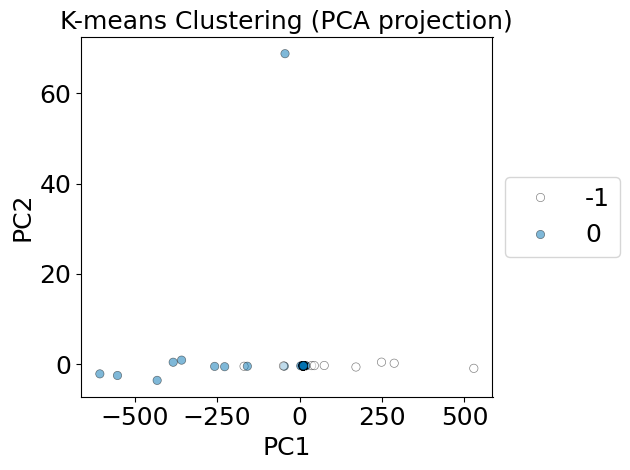

creating consensus factors and performing decomposition with fixed mode
   rank  cophenetic_corr  silhouette_score  kmeans_inertia       fit
0     1              NaN               NaN     7599.804219  0.587825
   cell_type_entropy  p_adj_postmortem  p_adj_postmortem_initial  \
0           1.574496          0.061738                  0.009258   

   p_adj_postmortem_post_therapy  factor  rank  
0                        0.74556       1     1  
rank 2
computing cophenetic correlation
performing kmeans clustering
(342, 10000)


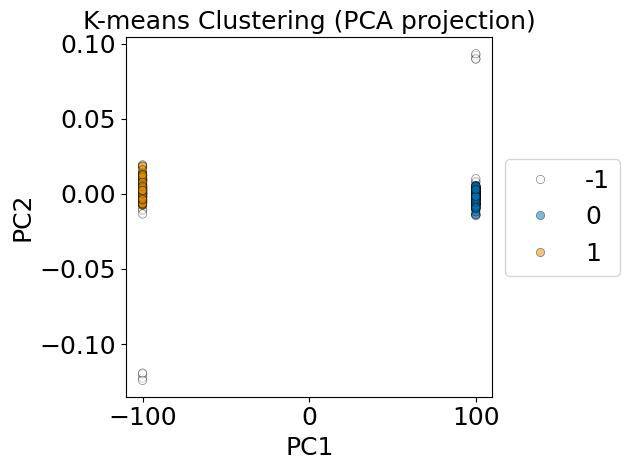

creating consensus factors and performing decomposition with fixed mode
   rank  cophenetic_corr  silhouette_score  kmeans_inertia       fit
0     2              1.0          0.999969         0.00003  0.682027
   cell_type_entropy  p_adj_postmortem  p_adj_postmortem_initial  \
0           1.151412          0.012546                  0.012986   
1           1.319018          0.012546                  0.001921   

   p_adj_postmortem_post_therapy  factor  rank  
0                       0.063687       1     2  
1                       0.436098       2     2  
rank 3
computing cophenetic correlation
performing kmeans clustering
(513, 10000)


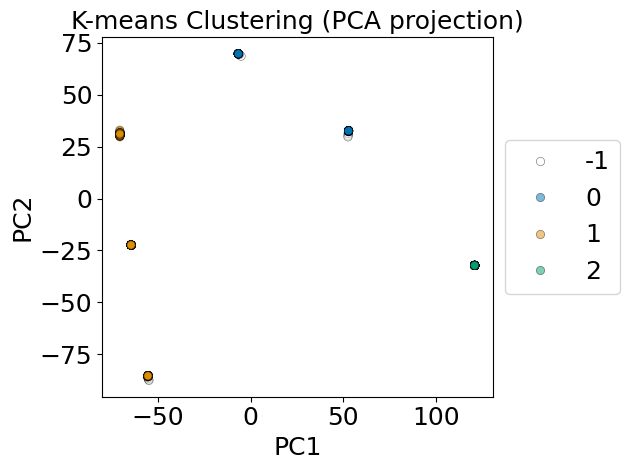

creating consensus factors and performing decomposition with fixed mode
   rank  cophenetic_corr  silhouette_score  kmeans_inertia       fit
0     3         0.931137          0.651934     2924.494728  0.700172
   cell_type_entropy  p_adj_postmortem  p_adj_postmortem_initial  \
0           1.310097          0.055140                  0.015129   
1           1.096808          0.024493                  0.015129   
2           0.875403          0.055140                  0.073333   

   p_adj_postmortem_post_therapy  factor  rank  
0                       0.495587       1     3  
1                       0.089734       2     3  
2                       0.233145       3     3  
rank 4
computing cophenetic correlation
performing kmeans clustering
(684, 10000)


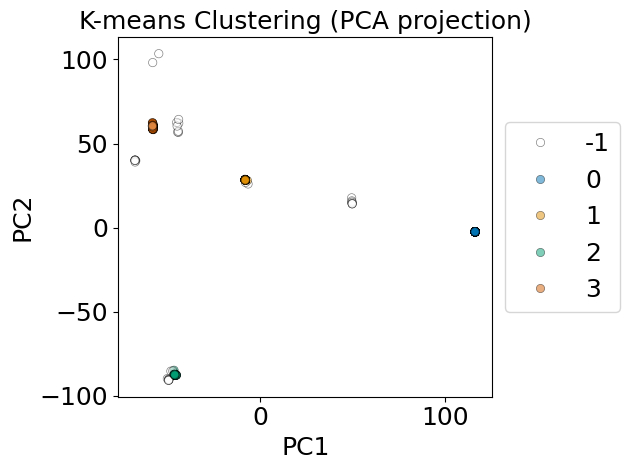

creating consensus factors and performing decomposition with fixed mode
   rank  cophenetic_corr  silhouette_score  kmeans_inertia       fit
0     4         0.993534          0.996059        0.353858  0.733742
   cell_type_entropy  p_adj_postmortem  p_adj_postmortem_initial  \
0           0.461916          0.019813                  0.005188   
1           0.852643          0.137906                  0.015271   
2           0.512822          0.290019                  0.542541   
3           0.688284          0.006009                  0.005188   

   p_adj_postmortem_post_therapy  factor  rank  
0                       0.290052       1     4  
1                       0.948254       2     4  
2                       0.290052       3     4  
3                       0.029887       4     4  
rank 5
computing cophenetic correlation
performing kmeans clustering
(855, 10000)


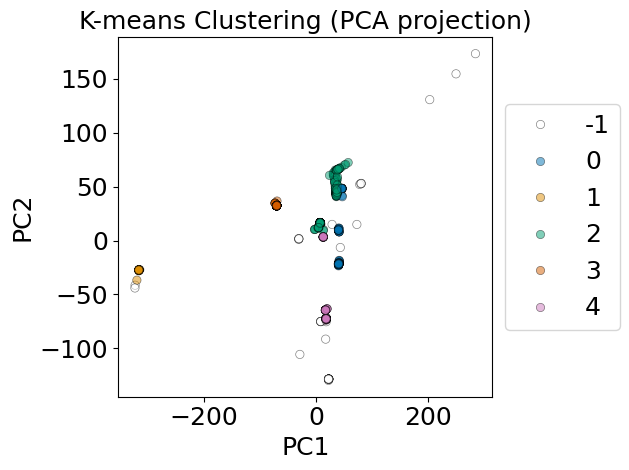

creating consensus factors and performing decomposition with fixed mode
   rank  cophenetic_corr  silhouette_score  kmeans_inertia       fit
0     5          0.96195          0.705402     1509.091503  0.709592
   cell_type_entropy  p_adj_postmortem  p_adj_postmortem_initial  \
0           0.985054          0.011122                  0.004849   
1           0.518074          0.667308                  0.870412   
2           1.231656          0.077173                  0.004849   
3           0.642646          0.077173                  0.028569   
4           1.106285          0.077173                  0.028569   

   p_adj_postmortem_post_therapy  factor  rank  
0                       0.069846       1     5  
1                       0.404544       2     5  
2                       0.948254       3     5  
3                       0.645423       4     5  
4                       0.645423       5     5  
rank 6
computing cophenetic correlation
performing kmeans clustering
(1026, 10000)


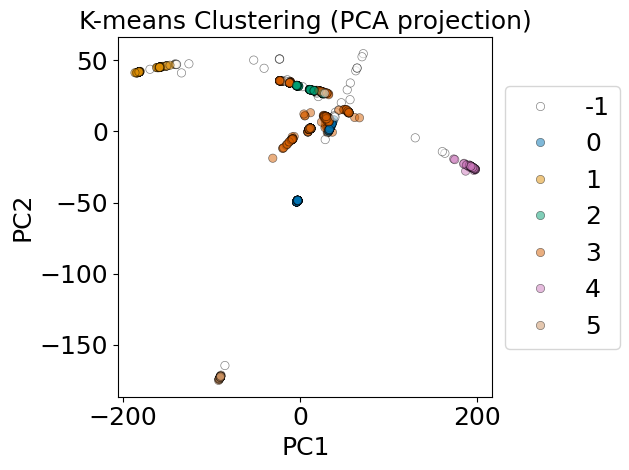

creating consensus factors and performing decomposition with fixed mode
   rank  cophenetic_corr  silhouette_score  kmeans_inertia       fit
0     6         0.817851            0.5536     1347.461461  0.713739
   cell_type_entropy  p_adj_postmortem  p_adj_postmortem_initial  \
0           0.949653          0.084296                  0.019479   
1           1.248437          0.084296                  0.019479   
2           0.662845          0.216633                  0.568474   
3           1.015789          0.084296                  0.019479   
4           1.391074          0.084296                  0.019479   
5           0.632107          0.313223                  0.568474   

   p_adj_postmortem_post_therapy  factor  rank  
0                       0.845628       1     6  
1                       0.799975       2     6  
2                       0.325238       3     6  
3                       0.619606       4     6  
4                       0.619606       5     6  
5                  

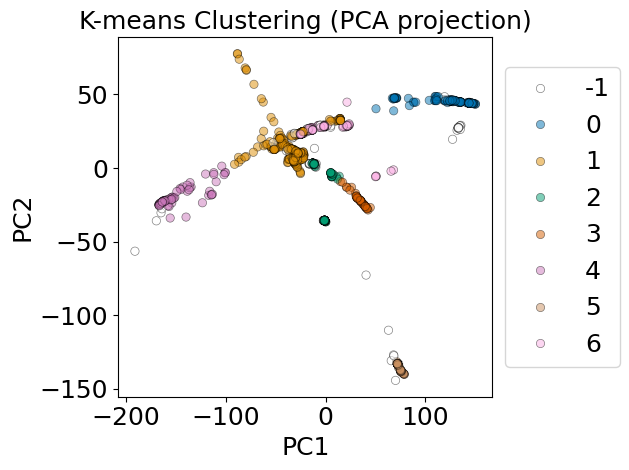

creating consensus factors and performing decomposition with fixed mode
   rank  cophenetic_corr  silhouette_score  kmeans_inertia       fit
0     7         0.844946          0.498312     1668.937977  0.744417
   cell_type_entropy  p_adj_postmortem  p_adj_postmortem_initial  \
0           0.211371          0.696241                  0.403907   
1           0.000000          0.008226                  0.002884   
2           1.076763          0.055329                  0.006052   
3           0.441248          0.276097                  0.626029   
4           0.843760          0.791379                  0.770249   
5           0.117936          0.020995                  0.043241   
6           0.193139          0.008226                  0.005044   

   p_adj_postmortem_post_therapy  factor  rank  
0                       0.770249       1     7  
1                       0.195692       2     7  
2                       0.770249       3     7  
3                       0.170920       4     7  


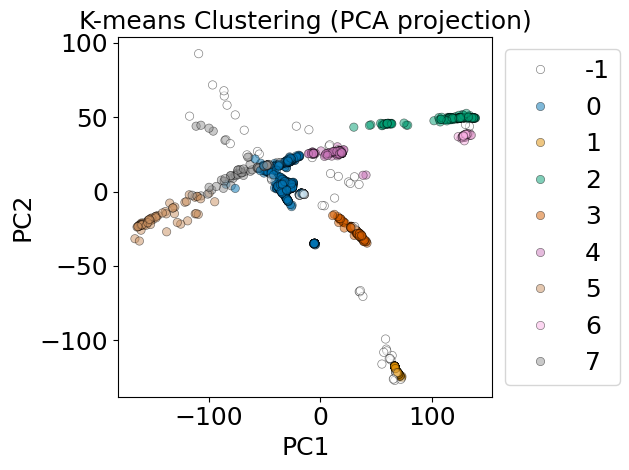

creating consensus factors and performing decomposition with fixed mode
   rank  cophenetic_corr  silhouette_score  kmeans_inertia       fit
0     8         0.864164          0.540791     1531.381855  0.735082
   cell_type_entropy  p_adj_postmortem  p_adj_postmortem_initial  \
0           0.409076          0.225385                  0.232011   
1           0.116956          0.057495                  0.096320   
2           0.177821          0.225385                  0.509364   
3           0.554431          0.087398                  0.187060   
4           0.000000          0.253977                  0.485820   
5           1.301959          0.050183                  0.003464   
6           1.155700          0.050183                  0.003296   
7           1.069778          0.102524                  0.187060   

   p_adj_postmortem_post_therapy  factor  rank  
0                        0.48582       1     8  
1                        0.18706       2     8  
2                        0.187

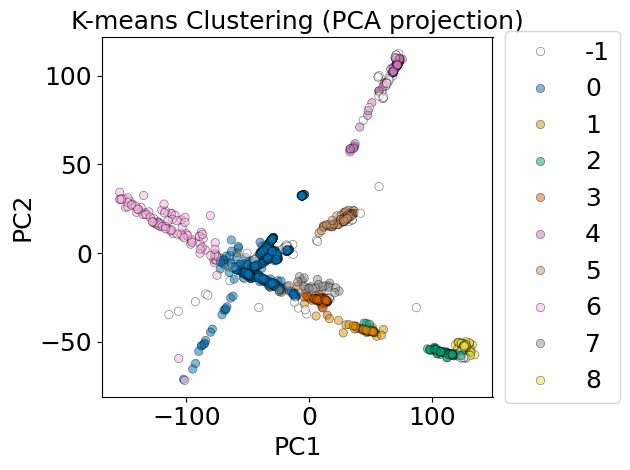

creating consensus factors and performing decomposition with fixed mode
   rank  cophenetic_corr  silhouette_score  kmeans_inertia       fit
0     9         0.830148          0.600626     1648.865276  0.723985
   cell_type_entropy  p_adj_postmortem  p_adj_postmortem_initial  \
0           1.444549          0.092607                  0.038026   
1           0.727149          0.203017                  0.333842   
2           0.689152          0.083435                  0.038026   
3           0.647385          0.179936                  0.071994   
4           0.307997          0.051842                  0.038026   
5           0.853139          0.135248                  0.054180   
6           1.169394          0.083435                  0.071994   
7           0.758037          0.022344                  0.003325   
8           1.131555          0.046760                  0.038026   

   p_adj_postmortem_post_therapy  factor  rank  
0                       0.641385       1     9  
1          

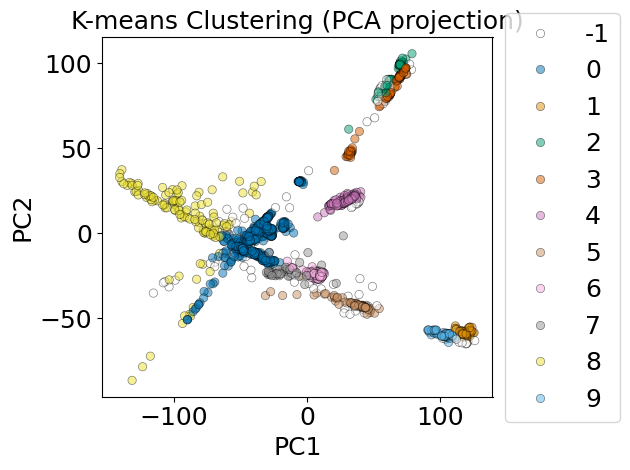

creating consensus factors and performing decomposition with fixed mode
   rank  cophenetic_corr  silhouette_score  kmeans_inertia       fit
0    10         0.840095          0.580352     1699.036702  0.725774
   cell_type_entropy  p_adj_postmortem  p_adj_postmortem_initial  \
0           1.018916          0.011263                  0.001892   
1           0.579917          0.245752                  0.234186   
2           0.254984          0.025725                  0.013646   
3           0.440663          0.354539                  0.454992   
4           0.320087          0.187926                  0.274233   
5           0.000000          0.025725                  0.008221   
6           0.000000          0.025725                  0.014154   
7           1.233527          0.013470                  0.008221   
8           1.529965          0.109854                  0.021879   
9           1.336557          0.025725                  0.007961   

   p_adj_postmortem_post_therapy  factor 

In [15]:
# read in factors and concatenate multiple runs of gene factorization
metrics_df = pd.DataFrame() # metrics per rank related to consensus factorization
summary_df = pd.DataFrame() # postmortem pvals and cell type entropy

R_min = min_rank
R_max = max_rank

np.random.seed(42)
for R in range(R_min, R_max + 1, 1):
    print("rank " + str(R))

    df = results_df[results_df["rank"] == R]
    
    # read in runs for given R
    gene_factors_list = []
    tensor_id_list = []
    for index, row in df.iterrows():
        rank = int(row["rank"])
        random_state = int(row["random_state"])
    
        # read in file
        output_dir_file = row["output_dir"]
        filepath = output_dir_file  + "/" + 'tensor_rank_' + str(rank) + '_random_state=' + str(random_state) + '.pt'
        tensor_factors = torch.load(filepath, weights_only=False)
        tensor_factors = cp_normalize(tensor_factors)
        gene_factors = tensor_factors[1][0]
    
        gene_factors_list.append(gene_factors)

        # keep track of which files were used
        for r in range(R):
            tensor_id_list.append(filepath + "_factor=" + str(r))
            
    
    # calculate cophenetic correlation
    print("computing cophenetic correlation")
    if R != 1:
        cophenetic_corr = calculate_cophenetic_corr(gene_factors_list)
    else:
        cophenetic_corr = np.nan
    
    A_concat = torch.cat(gene_factors_list, dim=1)
    X = A_concat.numpy().T

    
    print("performing kmeans clustering")
    kmeans_df, clustering_silhouette_score, kmeans_inertia = do_kmeans(X, R, lof = True)
    figure_filepath = figures_dir + "kmeans/" + "rank_" + str(R) + "_kmeans_pca.pdf"
    visualize_kmeans(X, R, kmeans_df, figure_filepath)
    kmeans_df["tensor_id"] = tensor_id_list
    
    print("creating consensus factors and performing decomposition with fixed mode")
    A_consensus = compute_consensus_factors(A_concat, R, kmeans_df)
    consensus_tensor_fact = non_negative_parafac_with_consensus_fixed(data_tensor, R, A_consensus)
    
    torch.save(consensus_tensor_fact, consensus_dir + 'consensus_tensor_rank_' + str(R) + '.pt')

    
    X_reconstructed = tl.cp_to_tensor(consensus_tensor_fact) #reconstruction
    fit = 1 - (torch.norm(data_tensor- X_reconstructed) / torch.norm(data_tensor))

    
    # add metrics to summary data frame
    new_row_df = pd.DataFrame({"rank": [R], "cophenetic_corr": [cophenetic_corr], "silhouette_score": [clustering_silhouette_score], 
                               "kmeans_inertia": [kmeans_inertia], "fit": [fit.item()]})
    metrics_df = pd.concat([metrics_df, new_row_df], ignore_index=True)
    print(new_row_df)
    

    cell_type_entropy, p_adj_postmortem, p_adj_postmortem_initial, p_adj_postmortem_post_therapy = calculate_postmortem_pvals_and_celltype_entropy(consensus_tensor_fact, R)
    temp_df = pd.DataFrame({"cell_type_entropy": cell_type_entropy, "p_adj_postmortem": p_adj_postmortem, "p_adj_postmortem_initial": p_adj_postmortem_initial, "p_adj_postmortem_post_therapy": p_adj_postmortem_post_therapy, "factor": np.arange(1, R+1).tolist()})
    temp_df['rank'] = R
    print(temp_df)
    summary_df = pd.concat([summary_df, temp_df], ignore_index = True)
    
    kmeans_df[["cluster", "tensor_id"]].to_csv(figures_dir + "kmeans/" + "kmeans_df_rank_" + str(R) + ".tsv", sep = "\t", index=False)


In [16]:
metrics_df.to_csv(figures_dir + "rank_vs_metrics_" + str(R_min) + "_to_" + str(R_max) + ".tsv", sep = "\t", index=False)
summary_df.to_csv(figures_dir + "rank_vs_celltype_entropy_and_p_adj_postmortem_" + str(R_min) + "_to_" + str(R_max) + ".tsv", sep = "\t", index=False)

# Plot metrics

In [17]:
metrics_df = pd.read_csv(figures_dir + "rank_vs_metrics_" + str(min_rank) + "_to_" + str(max_rank) + ".tsv", sep = "\t")
summary_df = pd.read_csv(figures_dir + "rank_vs_celltype_entropy_and_p_adj_postmortem_" + str(min_rank) + "_to_" + str(max_rank) + ".tsv", sep = "\t")
summary_df['-log10(p_adj_postmortem)'] = -np.log10(summary_df['p_adj_postmortem'])

In [18]:
p_threshold = -np.log10(0.05)
entropy_threshold = 1
summary_df['postmortem_specific'] = summary_df['-log10(p_adj_postmortem)'] > p_threshold
summary_df['celltype_specific'] = summary_df['cell_type_entropy'] < entropy_threshold
summary_df['postmortem_and_celltype_specific'] = (summary_df['-log10(p_adj_postmortem)'] > p_threshold) & (summary_df['cell_type_entropy'] < entropy_threshold)
num_significant_df = summary_df.groupby('rank', as_index=False).agg({'postmortem_and_celltype_specific': 'sum', 'postmortem_specific': 'sum', 'celltype_specific': 'sum'}) # number of factors that are cell type specific and postmortem specific
metrics_df = pd.merge(metrics_df, num_significant_df, on='rank', how='inner')

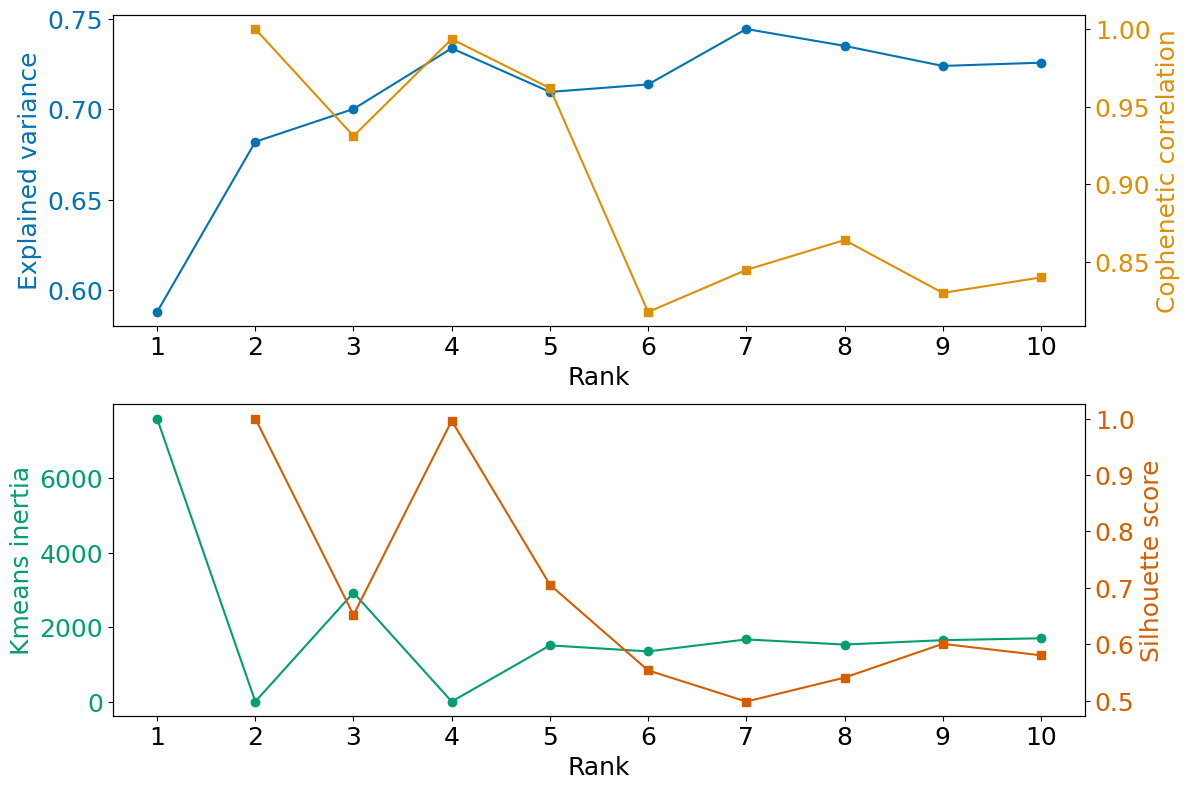

In [19]:
# Rank vs metrics plot
fig, axs = plt.subplots(2, 1, figsize=(12, 8))

df = metrics_df
x = df['rank']
y1 = df['fit']
y2 = df['cophenetic_corr']
y3 = df['kmeans_inertia']
y4 = df['silhouette_score']

custom_palette = sns.color_palette("colorblind", n_colors=4)
col1 = custom_palette[0]
col2 = custom_palette[1]
col3 = custom_palette[2]
col4 = custom_palette[3]

ax1 = axs[0]
ax1.plot(x, y1, marker='o', linestyle='-', color=col1)
ax1.set_xlabel('Rank')
ax1.set_ylabel('Explained variance', color=col1)
ax1.tick_params(axis='y', labelcolor=col1)
ax1b = ax1.twinx()
ax1b.plot(x, y2, marker='s', linestyle='-', color=col2)
ax1b.set_ylabel('Cophenetic correlation', color=col2)
ax1b.tick_params(axis='y', labelcolor=col2)
ax1.set_xticks(np.arange(1, max(df['rank']) + 1))

ax2 = axs[1]
ax2.plot(x, y3, marker='o', linestyle='-', color=col3)
ax2.set_xlabel('Rank')
ax2.set_ylabel('Kmeans inertia', color=col3)
ax2.tick_params(axis='y', labelcolor=col3)
ax2b = ax2.twinx()
ax2b.plot(x, y4, marker='s', linestyle='-', color=col4)
ax2b.set_ylabel('Silhouette score', color=col4)
ax2b.tick_params(axis='y', labelcolor=col4)
ax2.set_xticks(np.arange(1, max(df['rank']) + 1))

plt.tight_layout()

plt.savefig(figures_dir + "rank_vs_metrics.pdf")
plt.show()


# Start here to load consensus tensor

In [20]:
x_y_label_fontsize = 18
p_val_fontsize = 18

def max_without_outliers(data):
    data = np.array(data)
    q1 = np.percentile(data, 25)
    q3 = np.percentile(data, 75)
    iqr = q3 - q1

    # Define outlier bounds
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Filter data within bounds
    filtered = data[(data >= lower_bound) & (data <= upper_bound)]

    return np.max(filtered) if len(filtered) > 0 else None
    

def factor_plot(df, pval_df, value_col, group_col, subgroup_col, fig_width, fig_height, width, figure_outpath = "", save_figures=True, jitter = 0, plot_points = False, plot_significant_only = True, p_signif_color="black"):
    
    fig, axs = plt.subplots(2, 1, figsize=(fig_width, fig_height), sharex=True, gridspec_kw={'height_ratios': [1, 1]})
    
    ax1 = axs[0]
    
    groups = df[group_col].unique().tolist()
    subgroups = df[subgroup_col].unique().tolist()
    n_groups = len(groups)
    n_subgroups = len(subgroups)

    if n_subgroups == 2:
        custom_palette = ["#FE8900", "#785EF0"]
    else:
        custom_palette = sns.color_palette("colorblind", n_colors=n_subgroups)
    
    
    # box plots
    positions = []
    data_to_plot = []
    colors = []
    
    for i, group in enumerate(groups):
        for j, subgroup in enumerate(subgroups):
            pos = i - (width * (n_subgroups/2)) + (width * j) + width/2 + 0.5
            positions.append(pos)
            vals = df[(df[group_col] == group) & (df[subgroup_col] == subgroup)][value_col].tolist()
            data_to_plot.append(vals)
            colors.append(custom_palette[j])
    bplot = ax1.boxplot(data_to_plot, positions=positions, widths=width*0.8, patch_artist=True, showfliers=False)
    
    # change boxplot and median line colors
    for patch, color in zip(bplot['boxes'], colors):
        patch.set_facecolor(color)
    
    for line in bplot['medians']:
        line.set_color('black')
    
    
    # add invidiual points
    if plot_points:
        x_values = []
        y_values = []
        for p, y_list in zip(positions, data_to_plot):
            x_values += [p] * len(y_list)
            y_values += y_list
        if jitter == 0:
            jitter = width * 0.25 # default jitter
        jitter_values = np.random.uniform(-jitter, jitter, size=len(y_values))
        ax1.scatter(x_values + jitter_values, y_values, alpha=0.6, color='black', s=12, zorder=3)
    
    
    # set x-ticks in the middle of each group
    group_centers = [0.5 + i - (width/2) * (n_subgroups/2) for i in range(n_groups)]
    ax1.set_xticks(group_centers)
    ax1.set_xticklabels(groups)
    ax1.set_xlabel("", fontsize = x_y_label_fontsize)
    ax1.set_ylabel("Normalized loading", fontsize = x_y_label_fontsize)

    if n_groups == 8:
        ax1.set_ylim(-0.02, 0.35)
    elif n_groups == 9:
        ax1.set_ylim(-0.02, 0.52)
    elif n_groups == 10:
        ax1.set_ylim(-0.02, 0.48)
    
    # add legend manually
    custom_lines = []
    for i, _ in enumerate(subgroups):
        custom_lines.append(Line2D([0], [0], color=custom_palette[i], lw=4))
    ax1.legend(custom_lines, subgroups, title='Timepoint', bbox_to_anchor=(1, 1), loc="upper left")
    

    # add p-values and line (TODO make this into a function)
    if n_subgroups == 2:
        x_offset = width/2 
        for i, row in pval_df.iterrows():
            r = int(row['factor'])
            p = row['p_adj_postmortem']
        
            if p < 0.05:
                col_use = p_signif_color
            else:
                if plot_significant_only:
                    continue
                col_use = "black"
            
            p_text = f"p = {p:.3f}" if p >= 0.001 else "p < 0.001"
            
            x = r - 0.5
     
            if plot_points:
                y_max = df[df['factor'] == str(r)]['value'].max()
            else:
                y_max_list = []
                for s in subgroups:
                    y_max_i = max_without_outliers(df[(df['factor'] == str(r)) & (df[subgroup_col] == s)]['value'])
                    y_max_list.append(y_max_i)
                y_max = max(y_max_list)
            
            y_line = y_max + 0.01
            y_text = y_max + 0.015
            x1 = x - x_offset
            x2 = x + x_offset
            ax1.plot([x1, x2], [y_line, y_line], color=col_use, linewidth=1)
            ax1.text(x, y_text, p_text, ha='center', va='bottom', fontsize=p_val_fontsize, color = col_use)
    else:
         for i, row in pval_df.iterrows():
            r = int(row['factor'])
            p = row['p_adj_postmortem_initial']
            
            if p < 0.05:
                col_use = p_signif_color
            else:
                if plot_significant_only:
                    continue
                col_use = "black"
            
            p_text = f"p = {p:.3f}" if p >= 0.001 else "p < 0.001"
            
            x = r - 0.5
            
            if plot_points:
                y_max = df[df['factor'] == str(r)]['value'].max()
            else:
                y_max_list = []
                for s in subgroups:
                    y_max_i = max_without_outliers(df[(df['factor'] == str(r)) & (df[subgroup_col] == s)]['value'])
                    y_max_list.append(y_max_i)
                y_max = max(y_max_list)
            
            y_line = y_max + 0.065
            y_text = y_max + 0.075
            x1 = x - width
            x2 = x + width
            ax1.plot([x1, x2], [y_line, y_line], color=col_use, linewidth=1)
            ax1.text(x, y_text, p_text, ha='center', va='bottom', fontsize=p_val_fontsize, color = col_use)       

            # post therapy
            p = row['p_adj_postmortem_post_therapy']
            
            if p < 0.05:
                col_use = p_signif_color
            else:
                if plot_significant_only:
                    continue
                col_use = "black"
            
            p_text = f"p = {p:.3f}" if p >= 0.001 else "p < 0.001"
            
            x = r - 0.5
            
            if plot_points:
                y_max = df[df['factor'] == str(r)]['value'].max()
            else:
                y_max_list = []
                for s in subgroups:
                    y_max_i = max_without_outliers(df[(df['factor'] == str(r)) & (df[subgroup_col] == s)]['value'])
                    y_max_list.append(y_max_i)
                y_max = max(y_max_list)

            y_line = y_max + 0.025
            y_text = y_max + 0.035
            x1 = x
            x2 = x + width
            ax1.plot([x1, x2], [y_line, y_line], color=col_use, linewidth=1)
            ax1.text(x, y_text, p_text, ha='center', va='bottom', fontsize=p_val_fontsize, color = col_use)     
    
    
    # heatmap
    ax2 = axs[1]
    sns.heatmap(celltype_facs_df.iloc[:,0:rank], cmap = "viridis", ax = ax2, cbar=True, cbar_kws={'location': 'bottom', 'shrink': 0.5, 'label': 'Normalized loading'})
    ax2.set_xlabel("Factor", fontsize=x_y_label_fontsize)
    
    
    plt.tight_layout()
    
    if save_figures:
        plt.savefig(figure_outpath, dpi=300) 
    
    plt.show()

In [21]:
summary_df = pd.read_csv(figures_dir + "rank_vs_celltype_entropy_and_p_adj_postmortem_" + str(min_rank) + "_to_" + str(max_rank) + ".tsv", sep = "\t")
summary_df['-log10(p_adj_postmortem)'] = -np.log10(summary_df['p_adj_postmortem'])
summary_df['-log10(p_adj_postmortem_initial)'] = -np.log10(summary_df['p_adj_postmortem_initial'])
summary_df['-log10(p_adj_postmortem_post_therapy)'] = -np.log10(summary_df['p_adj_postmortem_post_therapy'])

In [22]:
save_figures = True

In [23]:
def plot_sample_facs_heatmap(sample_facs_w_metadata_df, rank):
    plt.figure(figsize=(20, 8))
    sns.heatmap(sample_facs_w_metadata_df.iloc[:, 0:rank], cmap = "viridis")
    plt.xlabel("Factor")
    
    if save_figures:
        plt.savefig(figures_output_dir + "sample_factors_heatmap.pdf") 
    plt.show()

In [24]:
def plot_factor_entropies(sample_facs_w_metadata_df_long, celltype_facs_df_long, gene_facs_df, top_genes_per_factor = 50):

    postmortem_sample_entropies = []
    celltype_entropies = []
    gene_entropies = []
    for i in range(1, rank + 1):
        entropy_postmortem = entropy(sample_facs_w_metadata_df_long[(sample_facs_w_metadata_df_long['factor'] == str(i)) & (sample_facs_w_metadata_df_long['is_postmortem'] == "Postmortem")]['value'].tolist())
        postmortem_sample_entropies.append(entropy_postmortem)
    
        entropy_celltype = entropy(celltype_facs_df_long[celltype_facs_df_long['factor'] == str(i)]['value'].tolist())
        celltype_entropies.append(entropy_celltype)
    
        gene_list_i = gene_facs_df[str(i)].tolist()
        gene_list_i.sort(reverse = True)
        entropy_gene = entropy(gene_list_i[:top_genes_per_factor])
        gene_entropies.append(entropy_gene)
        
    fig, ax = plt.subplots(figsize=(24, 6))
    
    custom_palette = sns.color_palette("colorblind", n_colors=3)
    col1 = custom_palette[0]
    col2 = custom_palette[1]
    col3 = custom_palette[2]
    
    x = np.arange(1, rank + 1)
    ax.plot(x, postmortem_sample_entropies, marker='o', linestyle='-', color=col1, label = "Postmortem sample entropy")
    ax.plot(x, celltype_entropies, marker='o', linestyle='-', color=col2, label = "Cell type entropy")
    ax.plot(x, gene_entropies, marker='o', linestyle='-', color=col3, label = "Gene entropy")
    
    ax.set_xlabel('Factor')
    ax.set_ylabel('Entropy')
    ax.set_xticks(np.arange(1, rank + 1))
    ax.legend(bbox_to_anchor=(1, 1), loc="upper left")
    plt.tight_layout()
    
    if save_figures:
        plt.savefig(figures_output_dir + "factor_vs_entropy.pdf") 
    
    plt.show()

1
Folder '/Users/pengja/PennNeurosurgery Dropbox/Jackie Peng/SilverbushLab/Projects/Jackie_post-mortem/Figures/Figure 1/Tensor Decomposition/rank_1/' already exists.


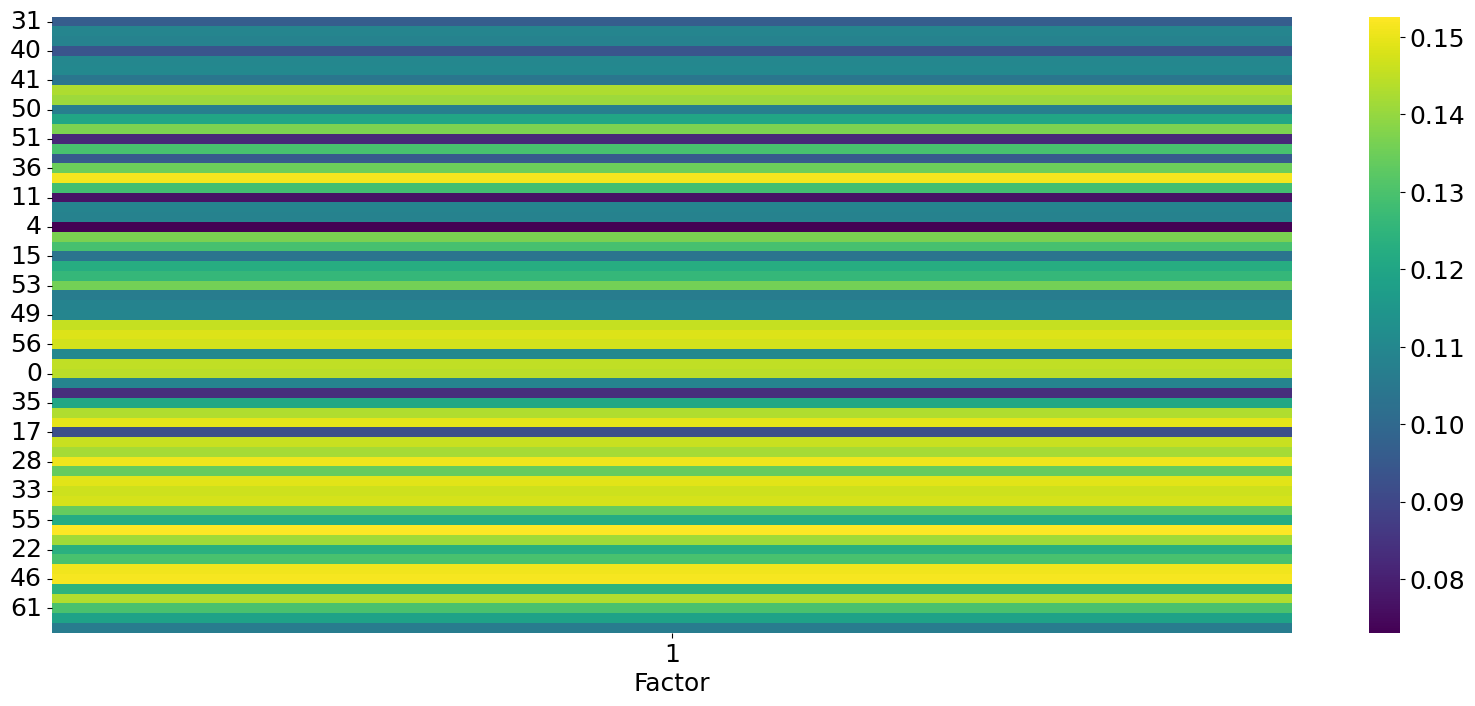

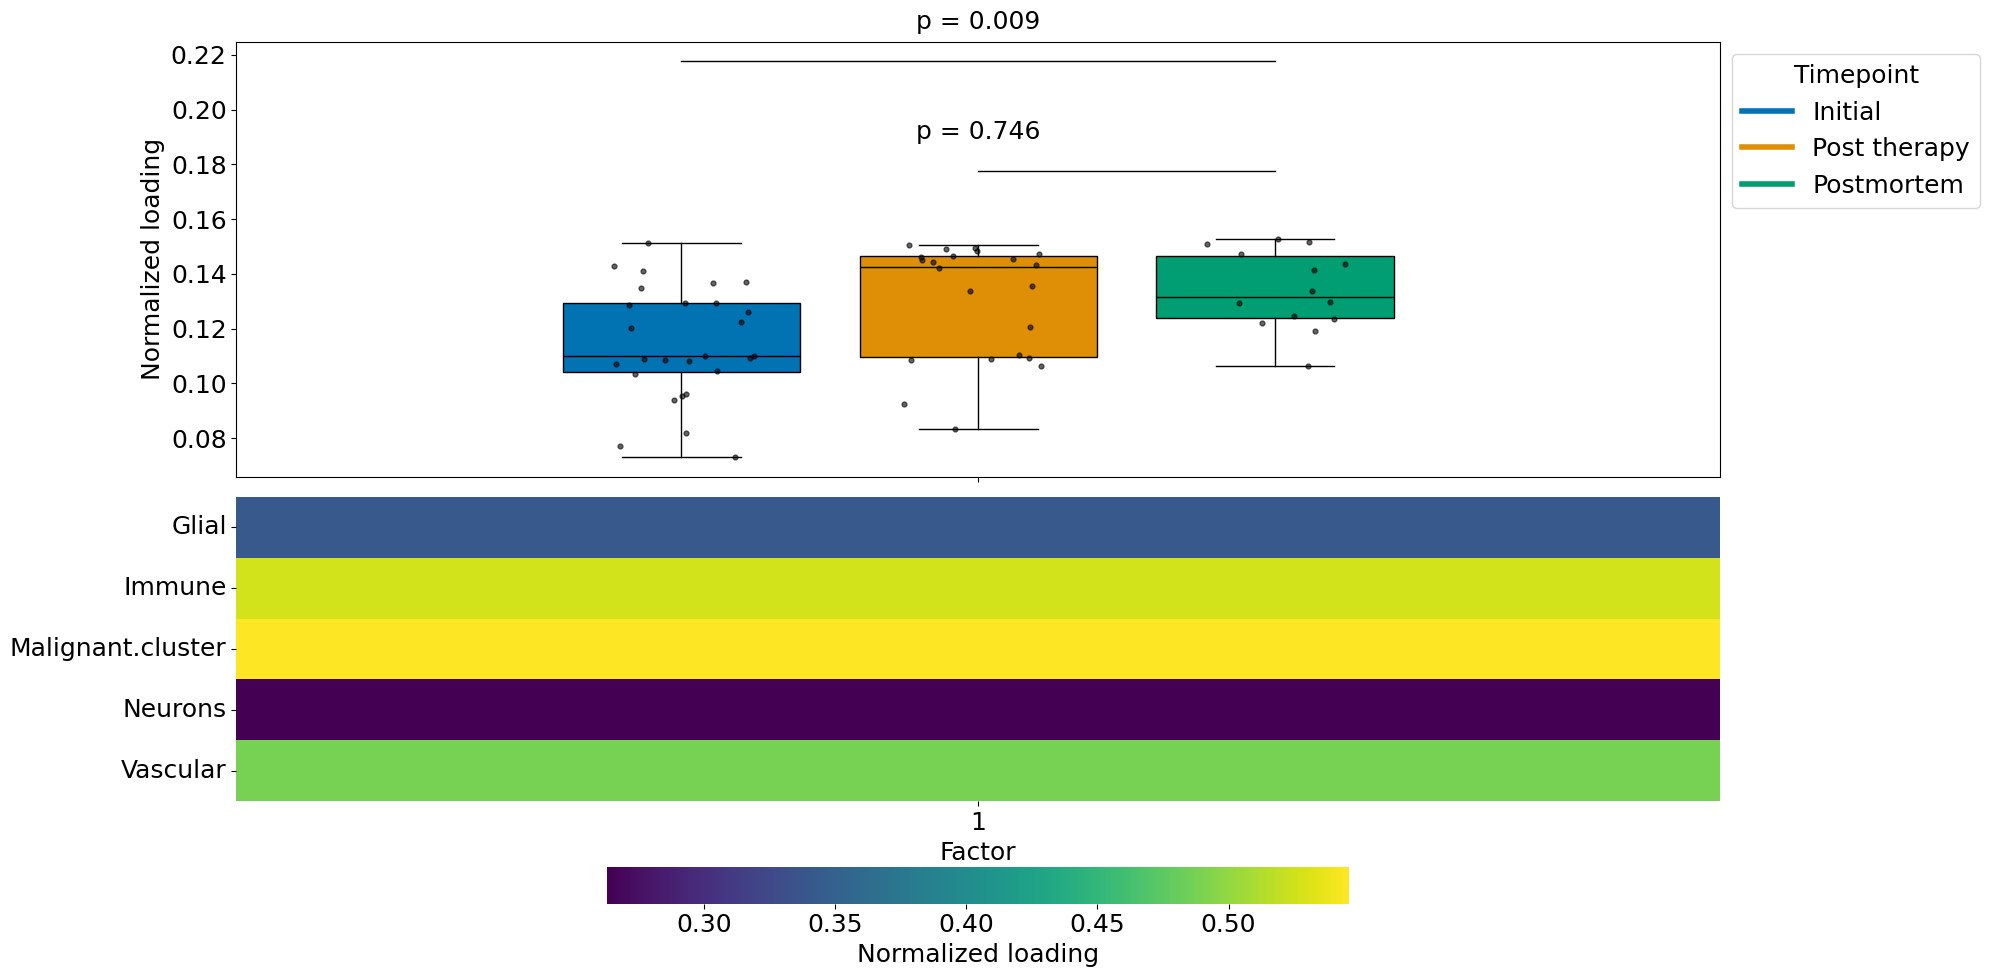

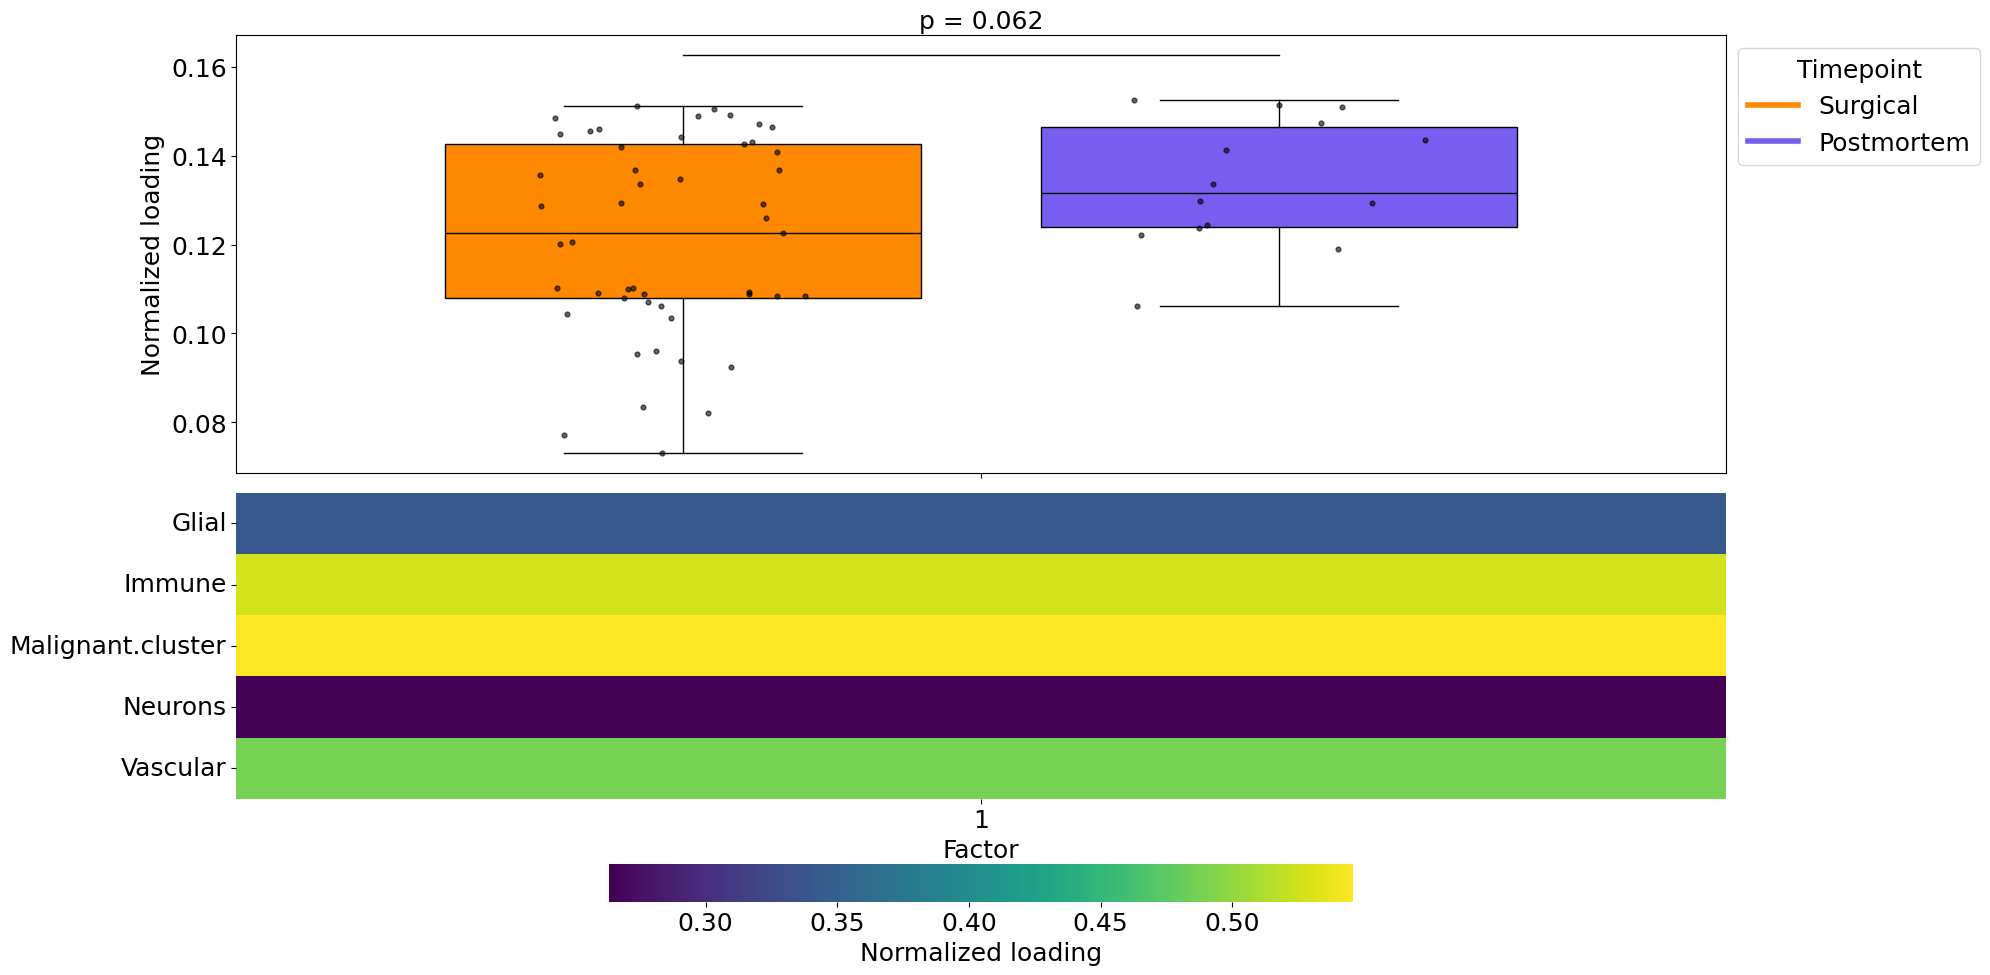

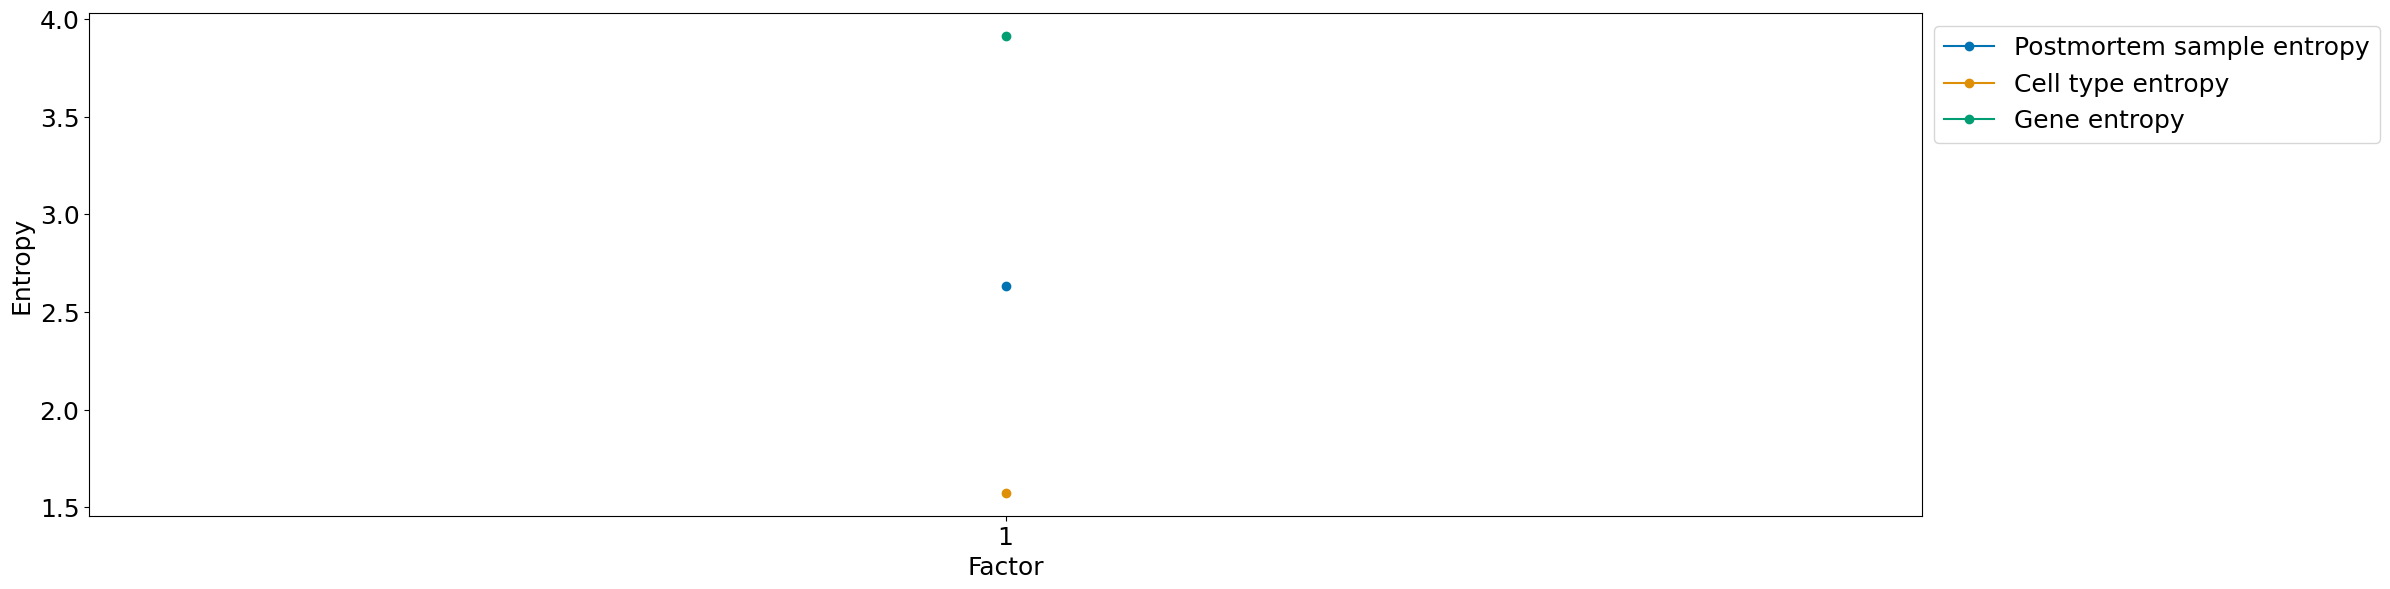


Factor: 1
MT-CO3', 'MT-CO2', 'MT-ATP6', 'MT-ND4', 'MT-ND3', 'MT-CYB', 'DOCK4', 'MAML2', 'MT-ND1', 'FMNL2', 'MT-ND2', 'HFM1', 'MAGI2', 'PDE4B', 'ZEB1', 'FRMD4A', 'RORA', 'NPAS3', 'SOX5', 'DLG2', 'MBNL1', 'CHD9', 'NAV2', 'PDE4D', 'BAZ2B', 'CELF2', 'PTK2', 'ZSWIM6', 'RPL13', 'LRP1B', 'FOXN3', 'NLGN1', 'SIK3', 'TBC1D5', 'CADM2', 'MEF2A', 'PTPRG', 'BICD1', 'PCDH9', 'LDLRAD4', 'ADGRL3', 'MAP2', 'ADGRB3', 'USP34', 'SSH2', 'PRKCA', 'APOE', 'CUX1', 'PICALM', 'SRPK2', 'NFIB', 'PITPNC1', 'ZEB2', 'PSD3', 'AKAP13', 'NF1', 'RASAL2', 'ERC1', 'FCHSD2', 'ARHGAP21', 'MT-ND5', 'PTPRZ1', 'SIPA1L1', 'ELMO1', 'LRMDA', 'FTL', 'PEAK1', 'ARL15', 'MAGI1', 'CCNY', 'RPLP1', 'ERBIN', 'B2M', 'FTH1', 'TRPS1', 'ITPR2', 'FYN', 'ARHGAP26', 'ANK2', 'TMSB4X', 'RPS19', 'CHST11', 'SPTBN1', 'RBFOX1', 'CDC42BPA', 'PLXDC2', 'ITFG1', 'NRXN3', 'ETV6', 'RPL37A', 'AOPEP', 'TBC1D22A', 'PHACTR1', 'PLCB1', 'FBXO11', 'SAMD4A', 'REV3L', 'CLU', 'HERC4', 'DTNA
2
Folder '/Users/pengja/PennNeurosurgery Dropbox/Jackie Peng/SilverbushLab/P

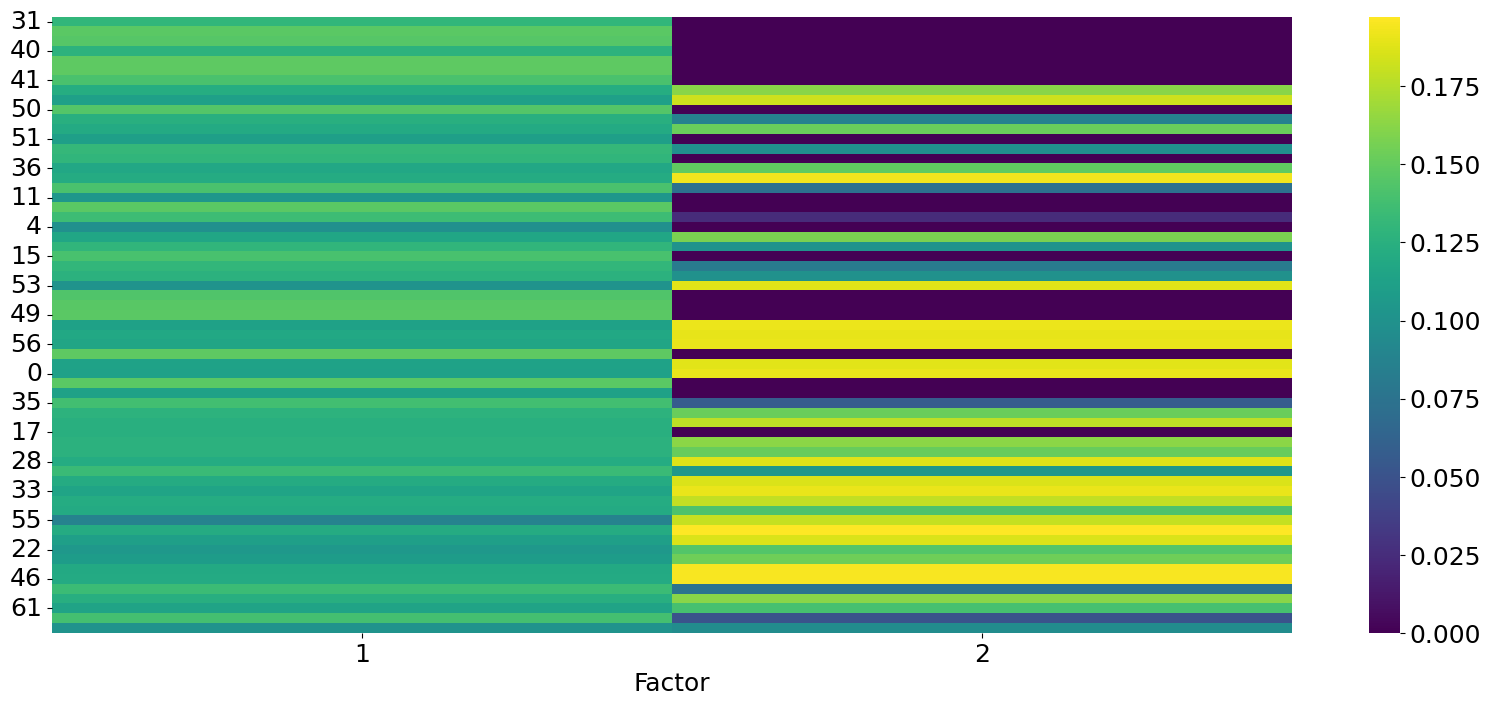

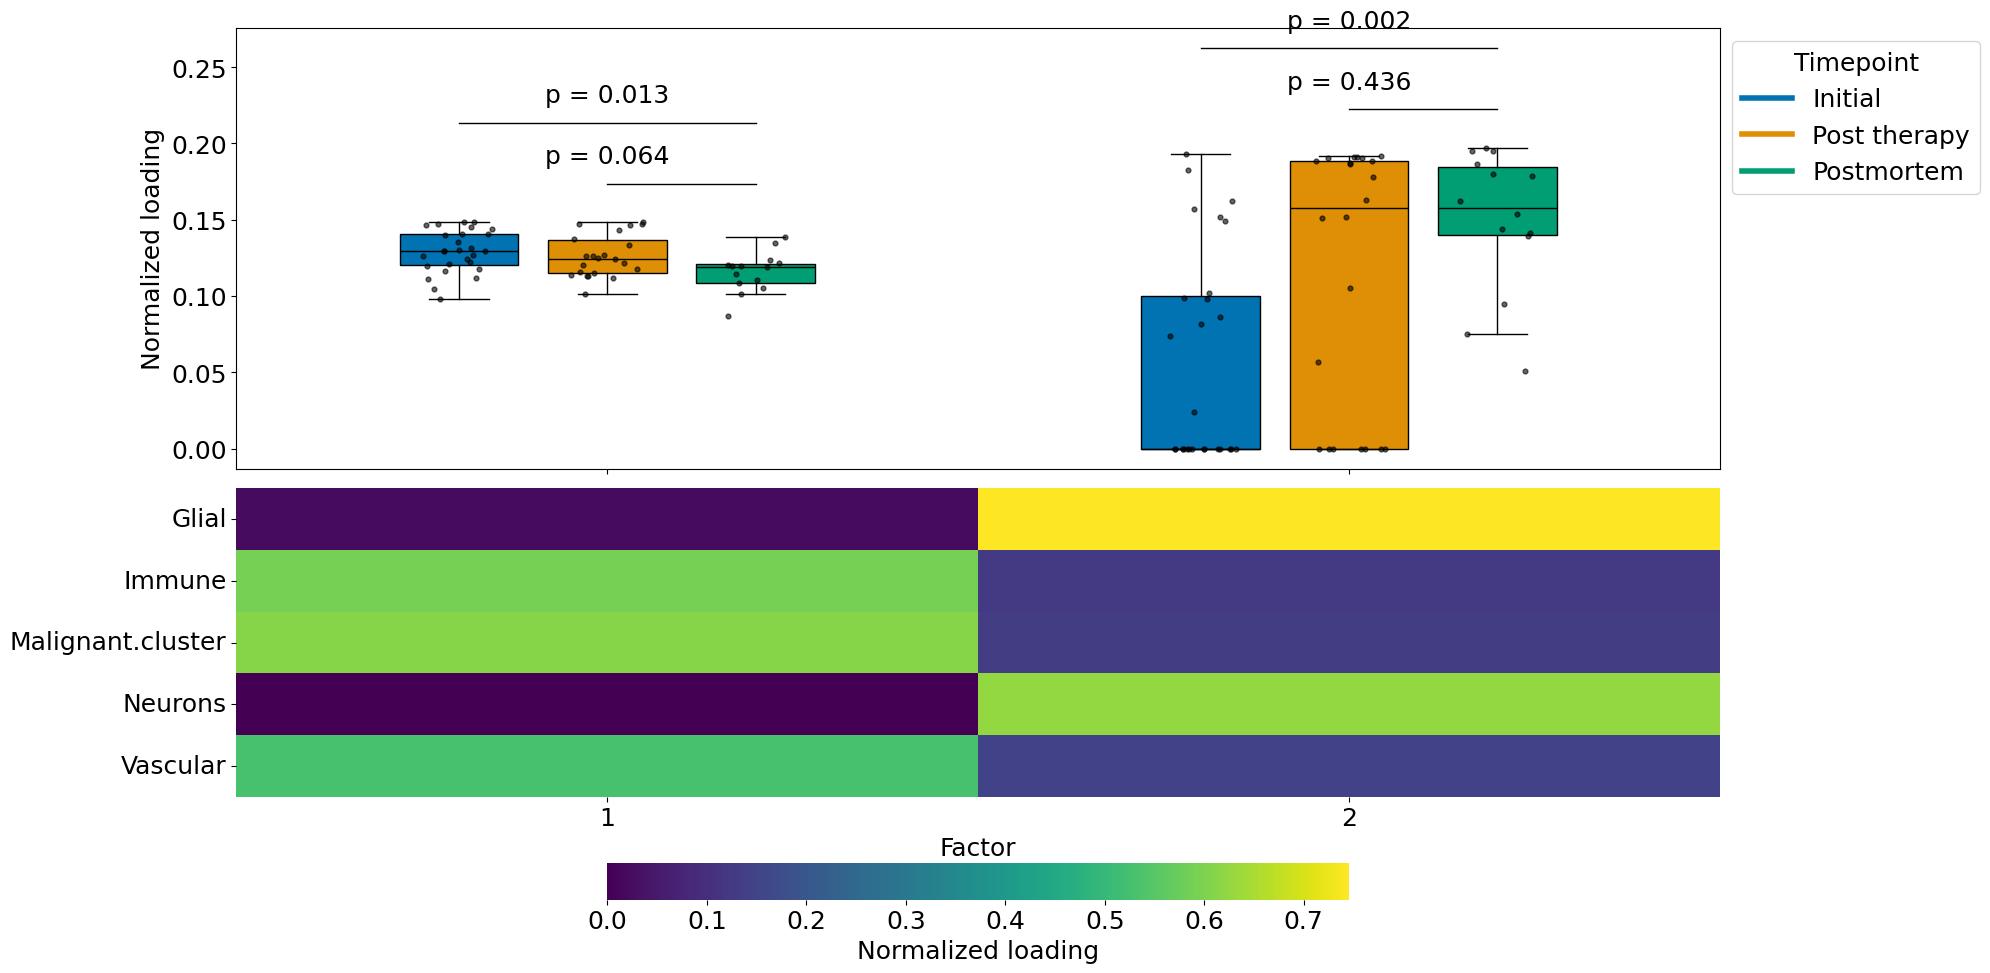

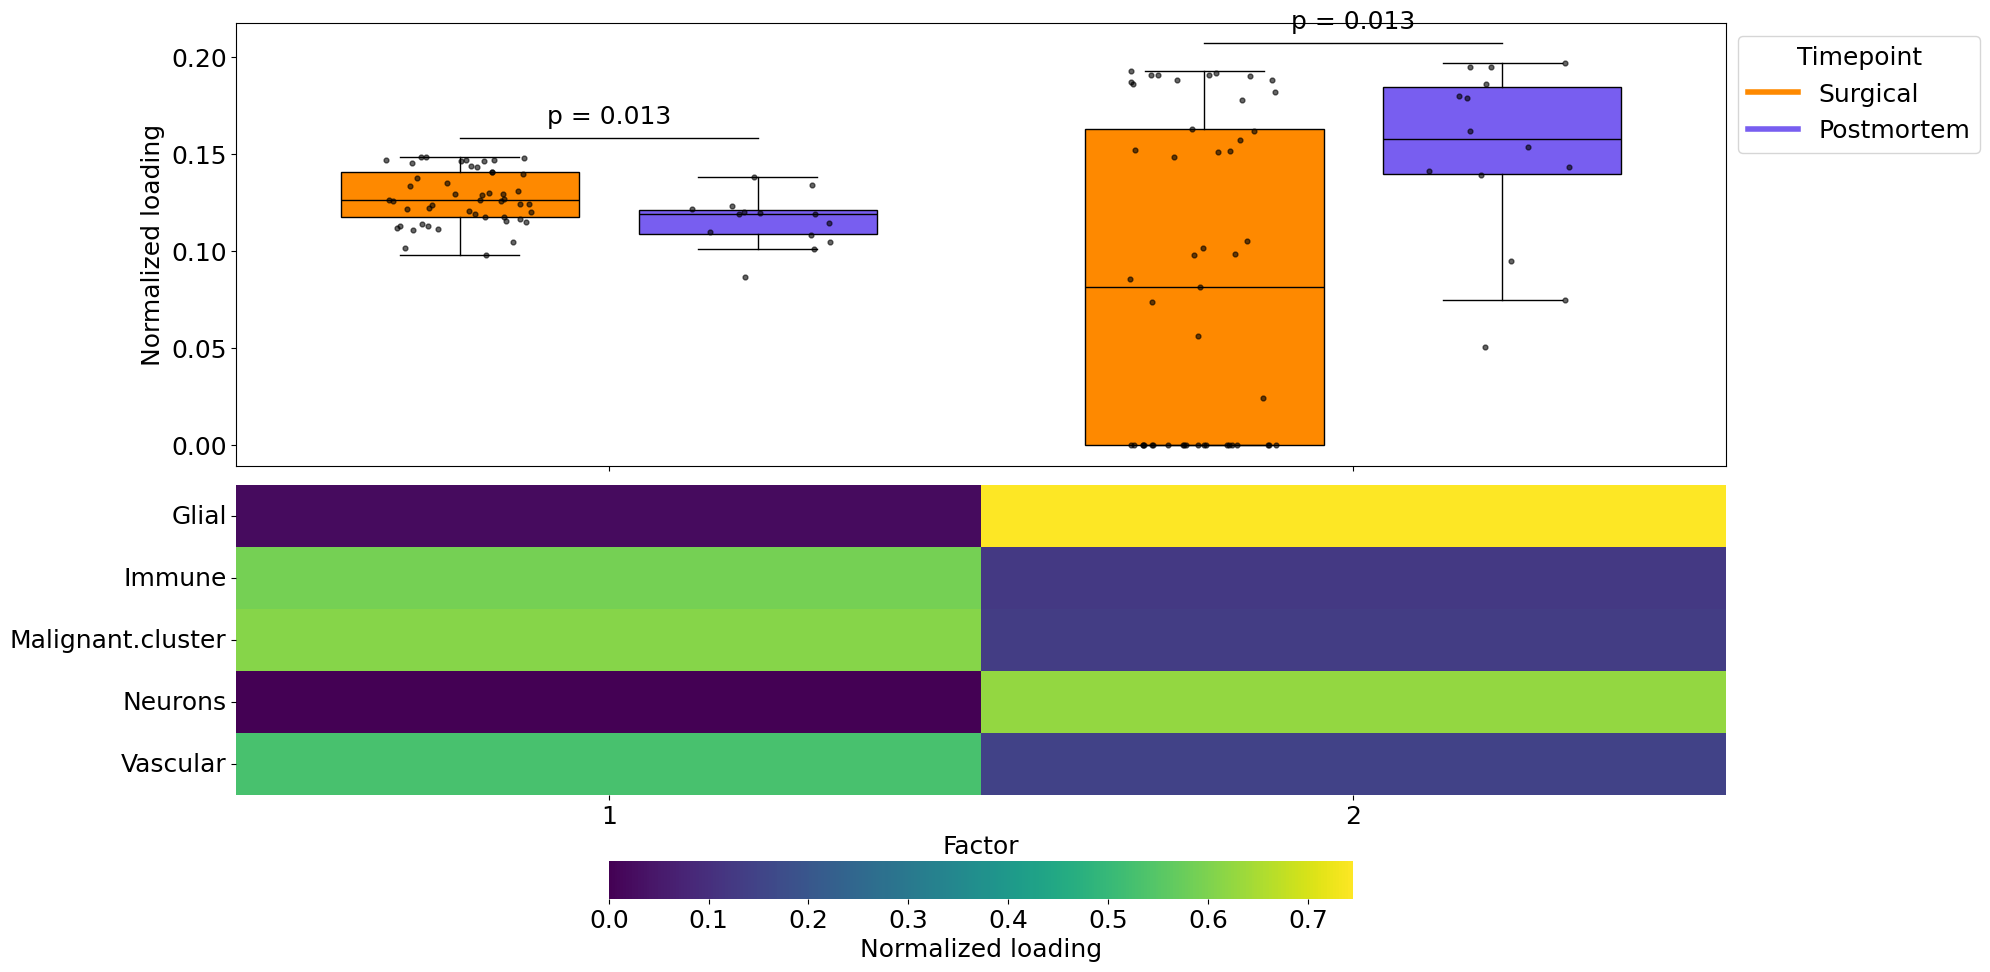

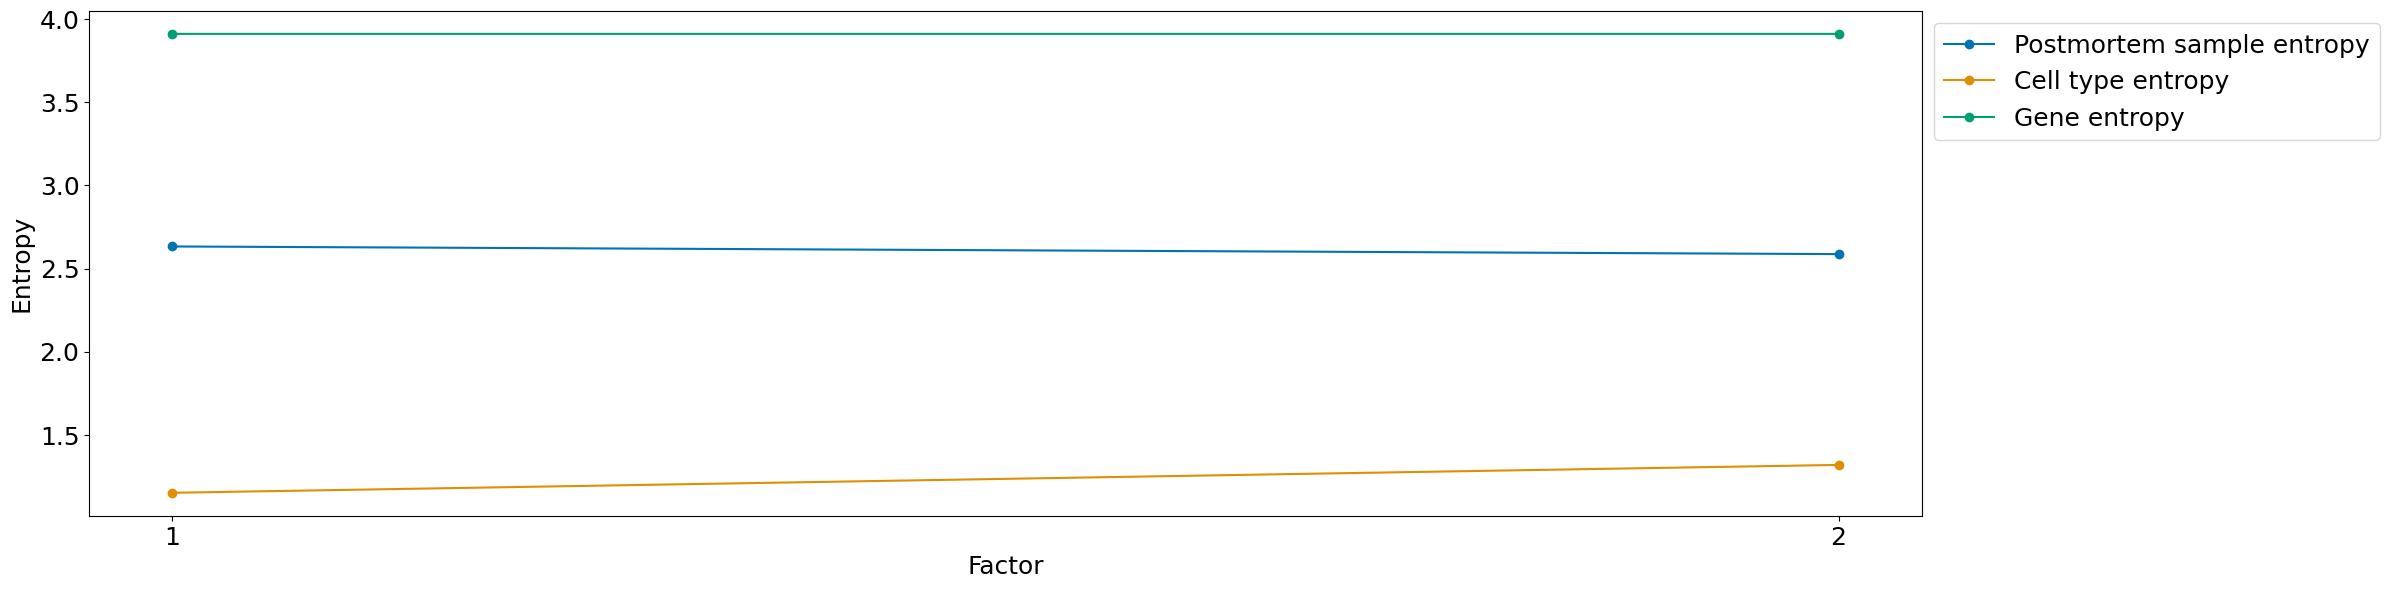


Factor: 1
MT-CO3', 'MT-CO2', 'MAML2', 'MT-ATP6', 'DOCK4', 'MT-ND3', 'MT-ND4', 'MT-CYB', 'LRMDA', 'AKAP13', 'FMNL2', 'ZEB1', 'MT-ND1', 'FRMD4A', 'FOXN3', 'HFM1', 'MT-ND2', 'CHST11', 'CHD9', 'FNDC3B', 'MBNL1', 'MEF2A', 'SOX5', 'RPL13', 'RORA', 'ZSWIM6', 'PTPRG', 'VIM', 'BAZ2B', 'ZEB2', 'LDLRAD4', 'CELF2', 'ARL15', 'ETV6', 'SSH2', 'RPLP1', 'PDE4B', 'PICALM', 'FCHSD2', 'USP34', 'CUX1', 'RASAL2', 'NPAS3', 'RAD51B', 'ARHGAP26', 'ITPR2', 'PTPRZ1', 'TBC1D5', 'BICD1', 'PDE4D', 'TBC1D22A', 'B2M', 'PITPNC1', 'APOE', 'PTK2', 'RPS19', 'TMSB4X', 'PEAK1', 'SIPA1L1', 'NF1', 'PRKCA', 'NAV2', 'UTRN', 'MAGI2', 'NFIB', 'ELMO1', 'ERC1', 'FBXO11', 'FTL', 'TRPS1', 'TMSB10', 'SRPK2', 'DISC1', 'SLC1A3', 'PLXDC2', 'SIK3', 'LIMS1', 'CCNY', 'RAPGEF1', 'CAMK1D', 'VMP1', 'MEF2C', 'ERBIN', 'ATG7', 'FTH1', 'PSD3', 'EEF1A1', 'BACH1', 'NLGN1', 'RPL13A', 'EPB41L2', 'MAP2', 'MT-ND5', 'WSB1', 'RPL37A', 'SAMD4A', 'ARHGAP21', 'ZFHX3', 'SDK1', 'PTN

Factor: 2
PCDH9', 'MT-CO3', 'MT-CO2', 'CADM2', 'DLG2', 'MAGI2', 'LRP1B', 'M

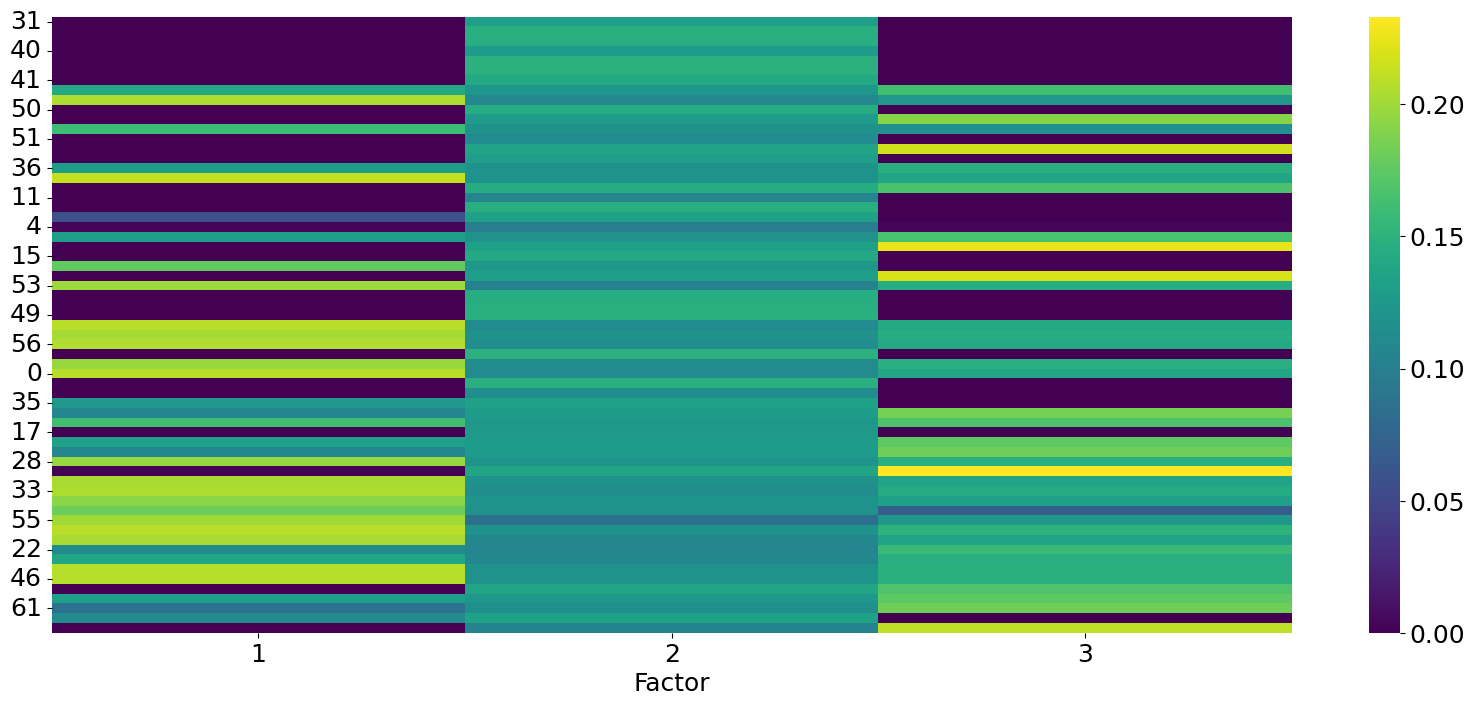

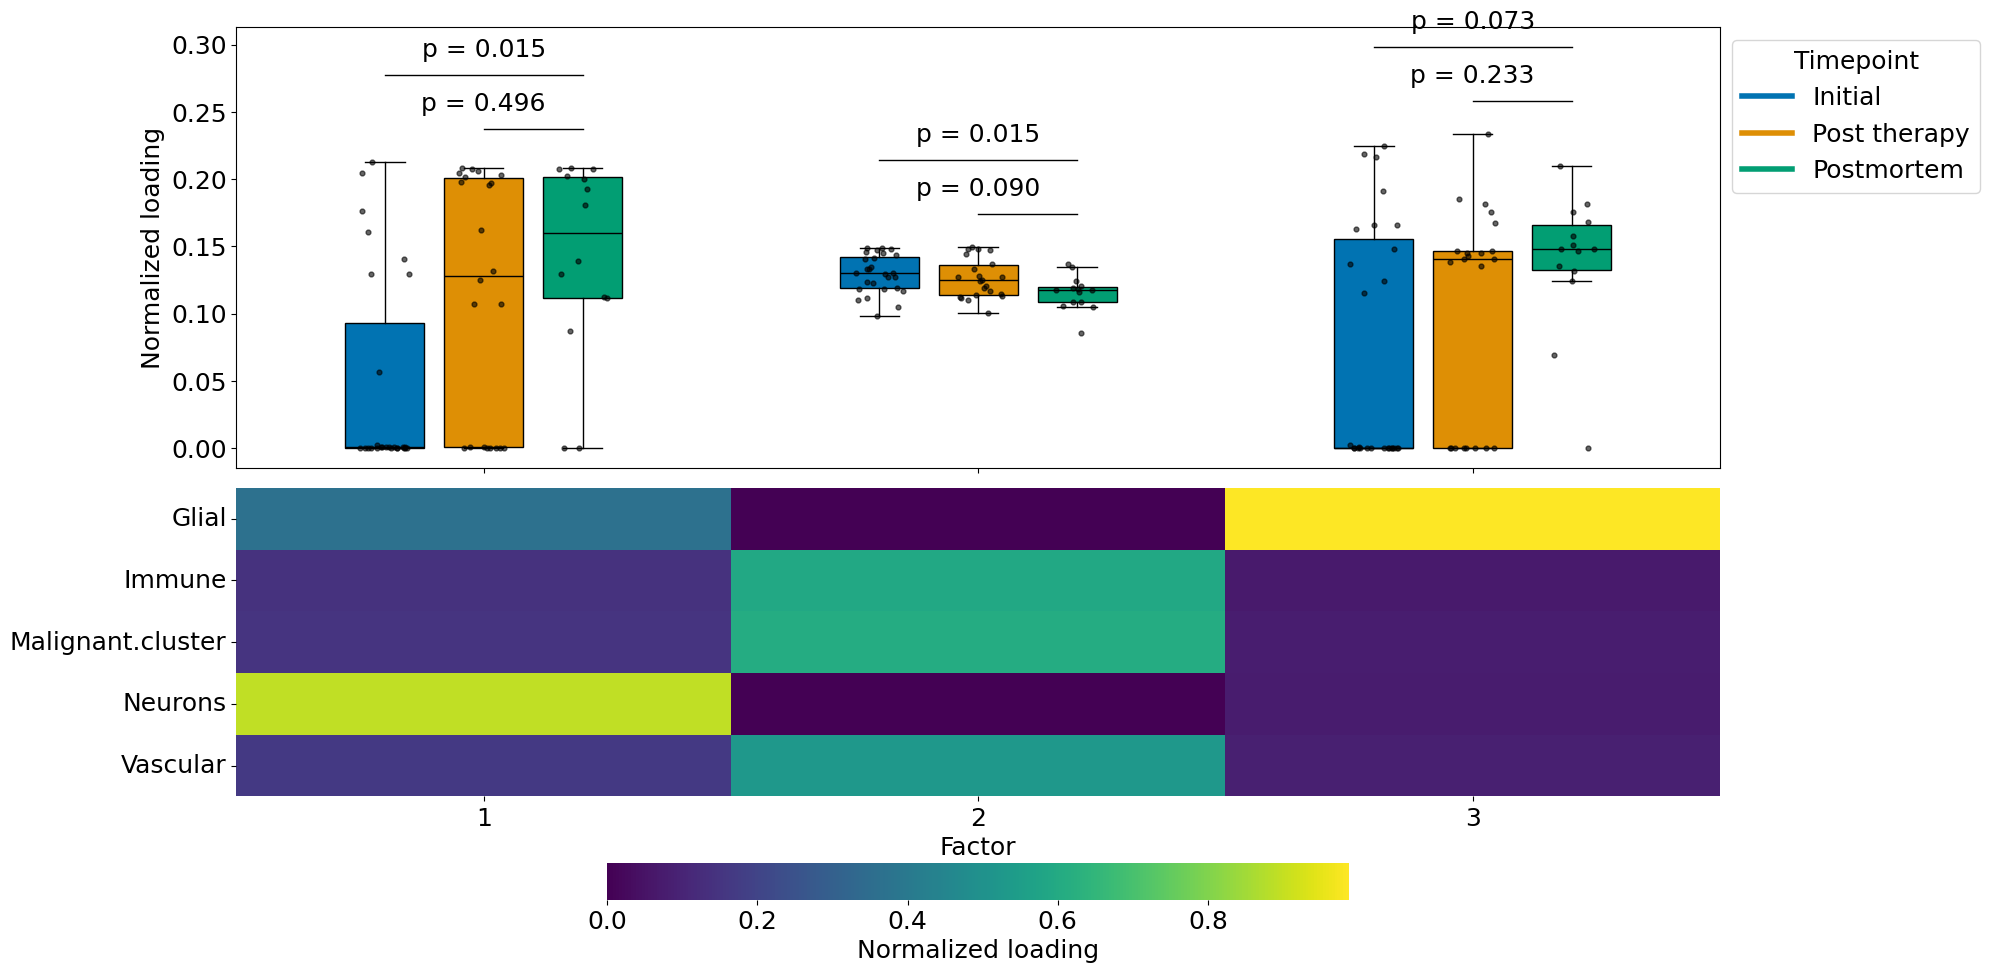

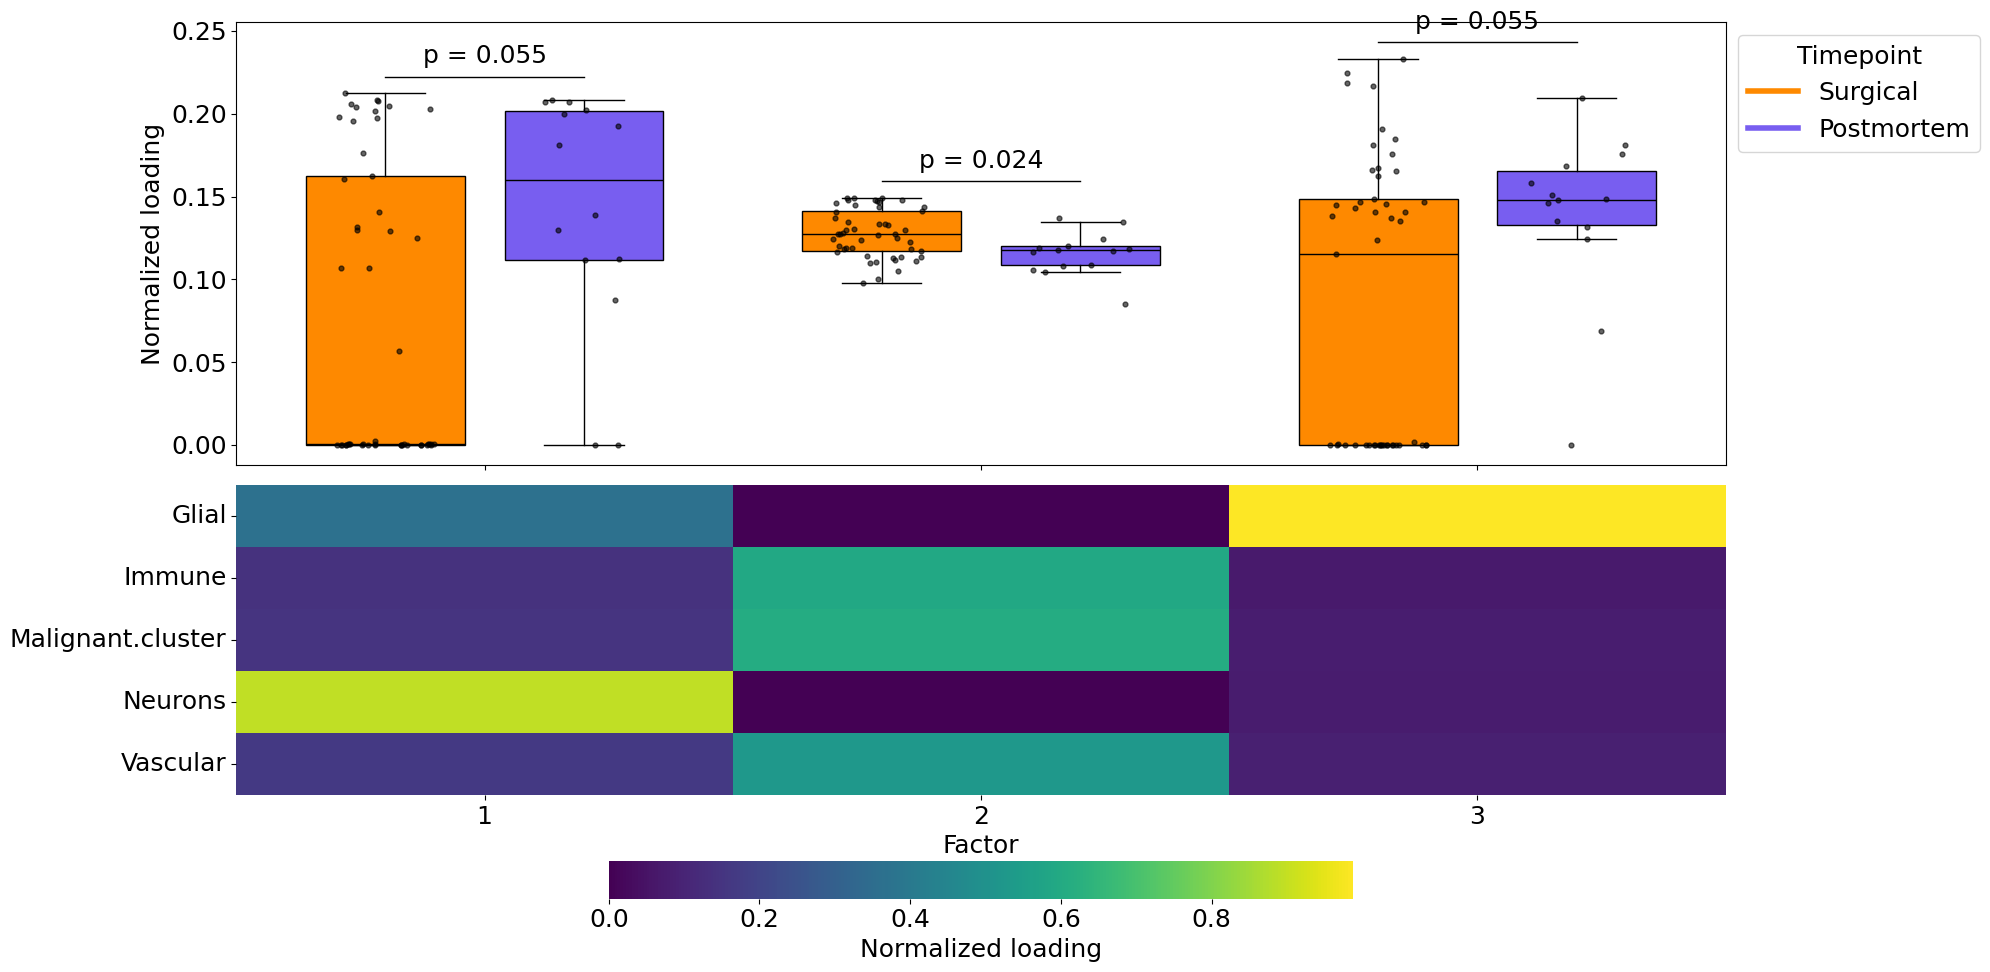

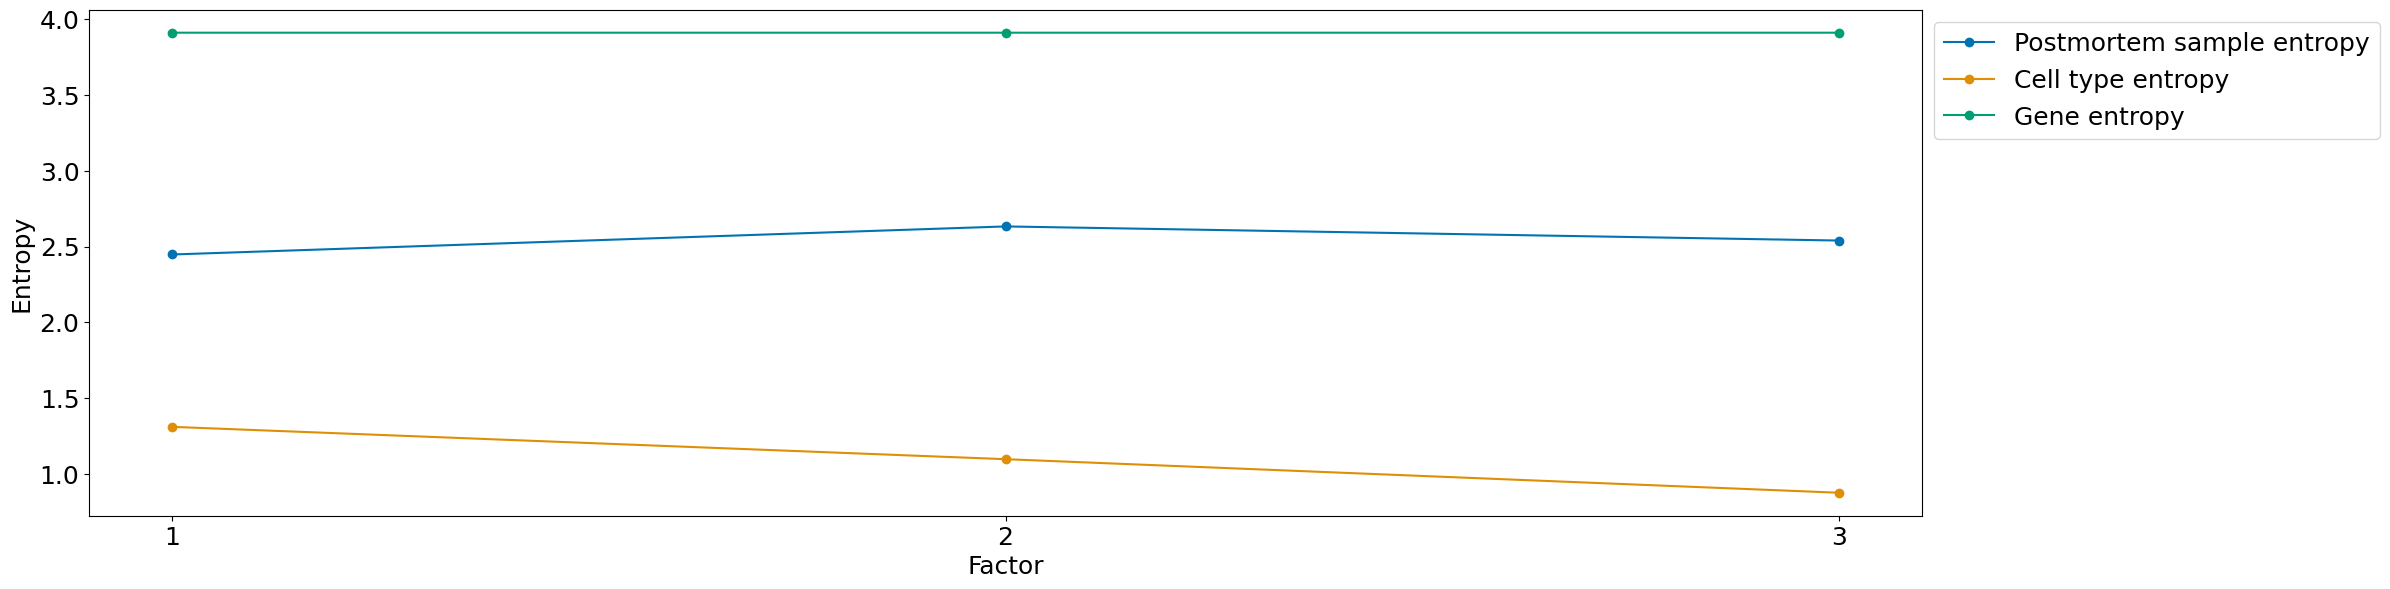


Factor: 1
PCDH9', 'PPP2R2B', 'CADM2', 'MAGI2', 'NPAS3', 'MT-CO2', 'LRP1B', 'MT-CO3', 'DLG2', 'IL1RAPL1', 'PDE4B', 'MT-ATP6', 'NTM', 'MT-ND4', 'NCAM2', 'MBP', 'ERBB4', 'ADGRB3', 'MT-ND3', 'FMNL2', 'ANK2', 'DNM3', 'CTNND2', 'SIK3', 'CTNNA3', 'SLC44A1', 'MT-CYB', 'PLP1', 'MT-ND1', 'TMTC2', 'NCAM1', 'FRMD5', 'DOCK4', 'MAML2', 'MT-ND2', 'NLGN1', 'RNF220', 'NCKAP5', 'NRXN1', 'DTNA', 'AKAP6', 'GPM6B', 'MARCHF1', 'NAV2', 'MAP7', 'PHLPP1', 'PTPRD', 'ST18', 'ADGRL3', 'SPOCK3', 'PIP4K2A', 'ERBIN', 'FBXL7', 'ARHGAP21', 'HFM1', 'CDH20', 'UNC5C', 'DOCK10', 'DLG1', 'ANKS1B', 'PTK2', 'ENOX1', 'ZEB2', 'NKAIN2', 'LIMCH1', 'PTPRK', 'RBFOX1', 'EDIL3', 'APOE', 'DOCK3', 'PRKCA', 'CLU', 'MAN2A1', 'ELMO1', 'DPP6', 'BAZ2B', 'SLC1A3', 'NTRK2', 'SCD5', 'SORBS1', 'SLC24A2', 'ST6GALNAC3', 'KIRREL3', 'CDC42BPA', 'TJP1', 'PSD3', 'PLCL1', 'ANK3', 'CTNNA2', 'TRIM2', 'TBC1D5', 'ARAP2', 'TTLL7', 'GAB1', 'PDE4DIP', 'NRXN3', 'PRUNE2', 'MAPK10', 'GPC5', 'FRYL

Factor: 2
MT-CO3', 'MT-CO2', 'MT-ATP6', 'MAML2', 'MT-ND3', 'DO

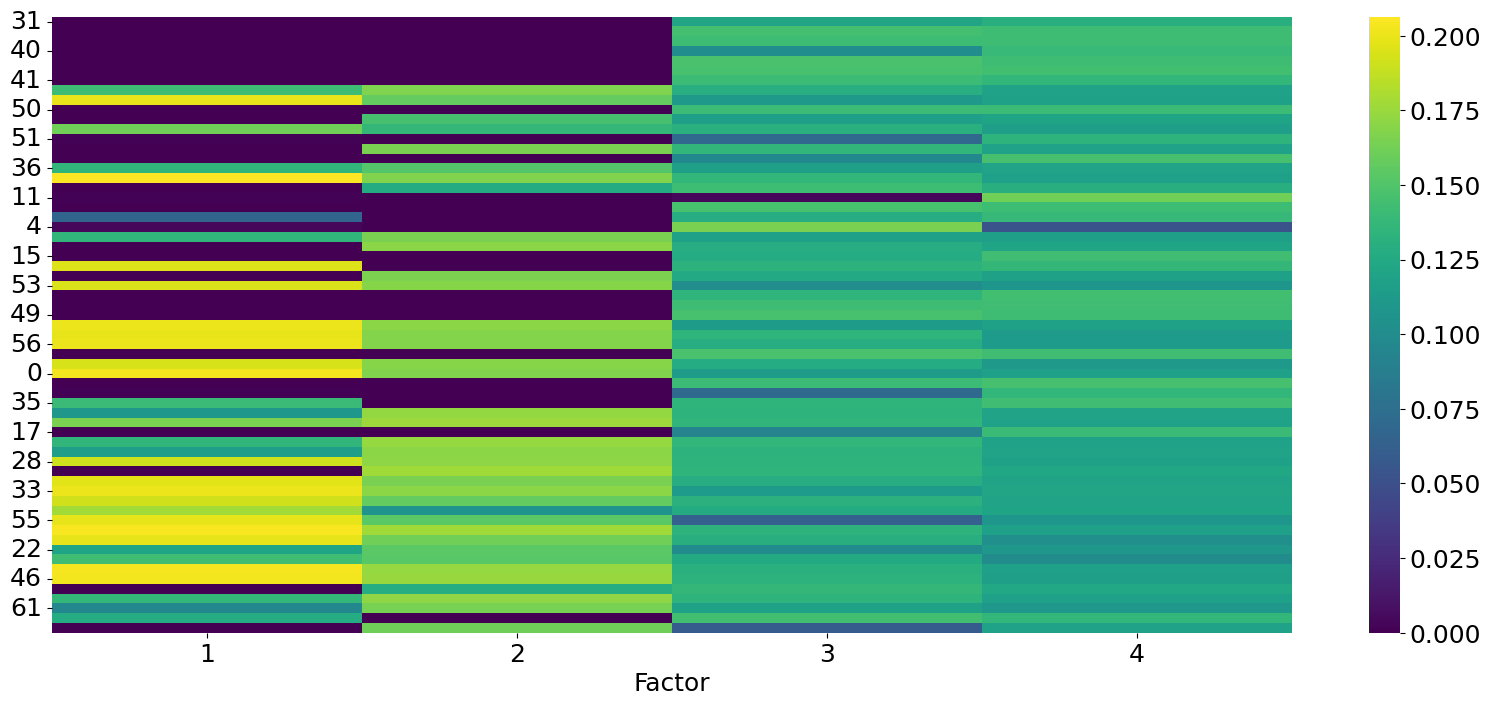

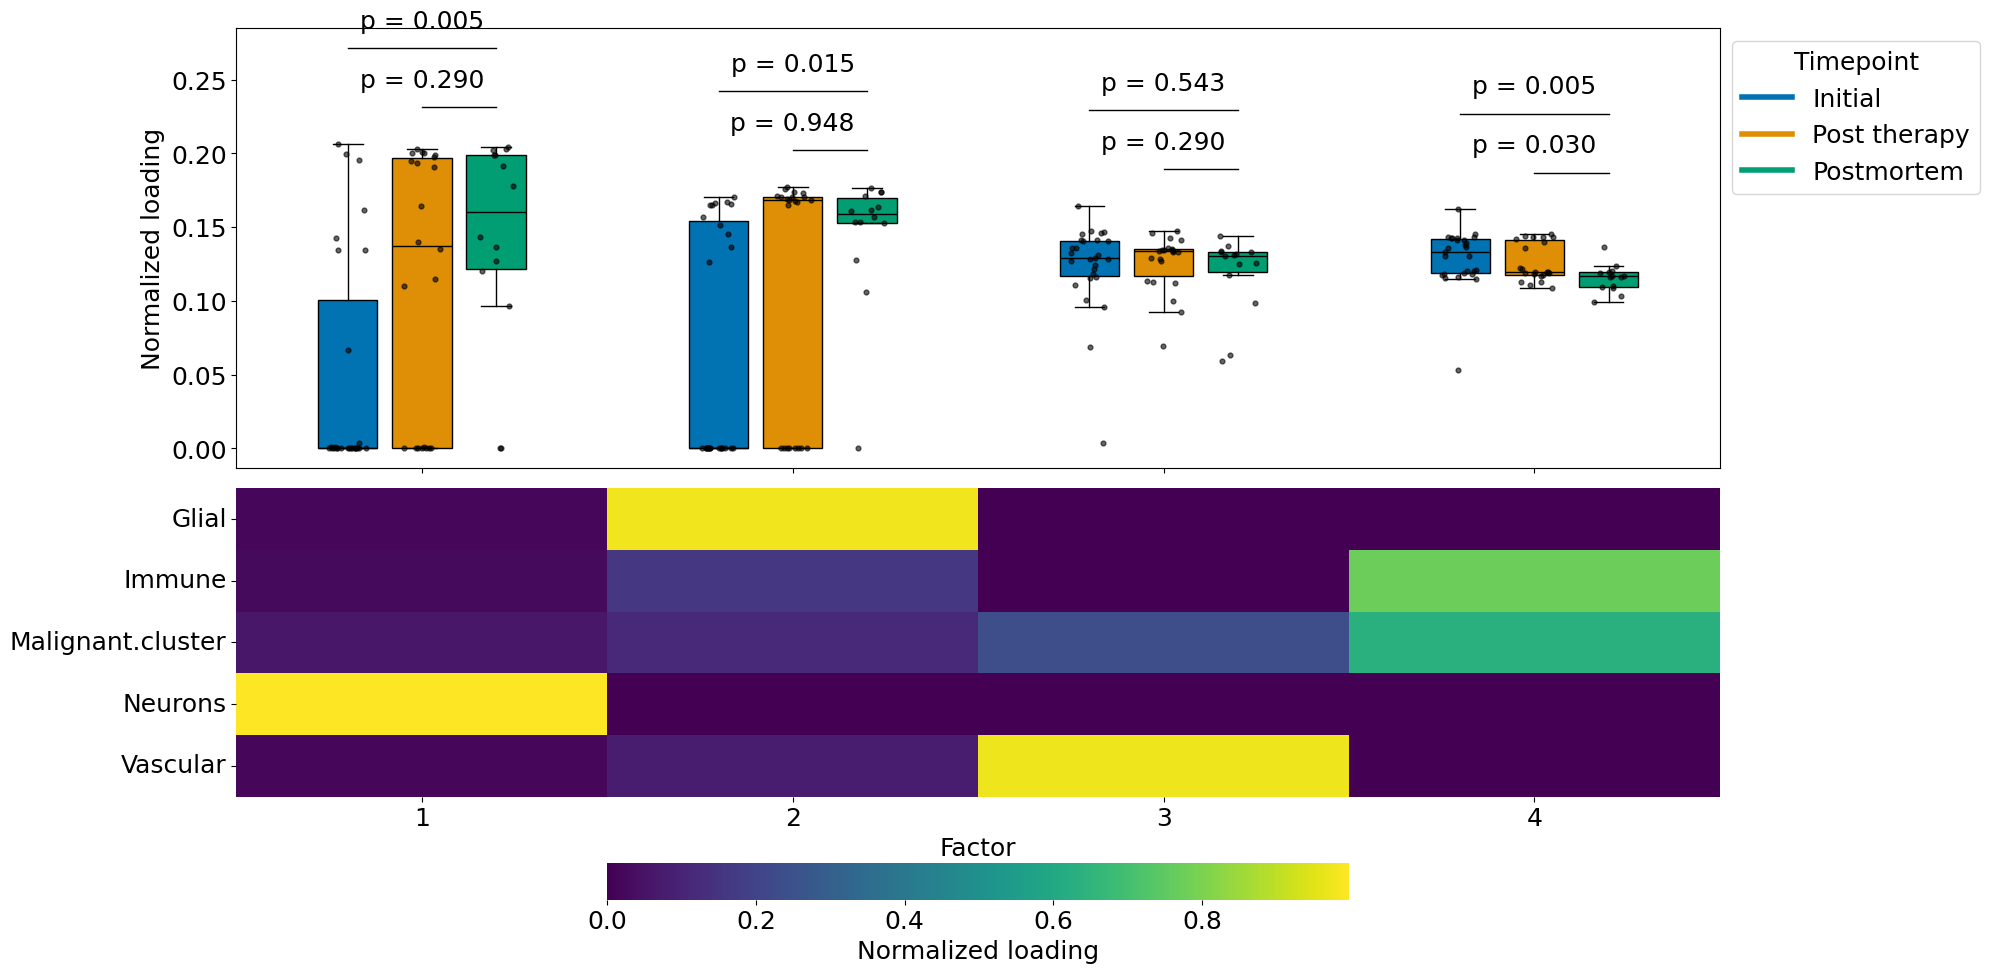

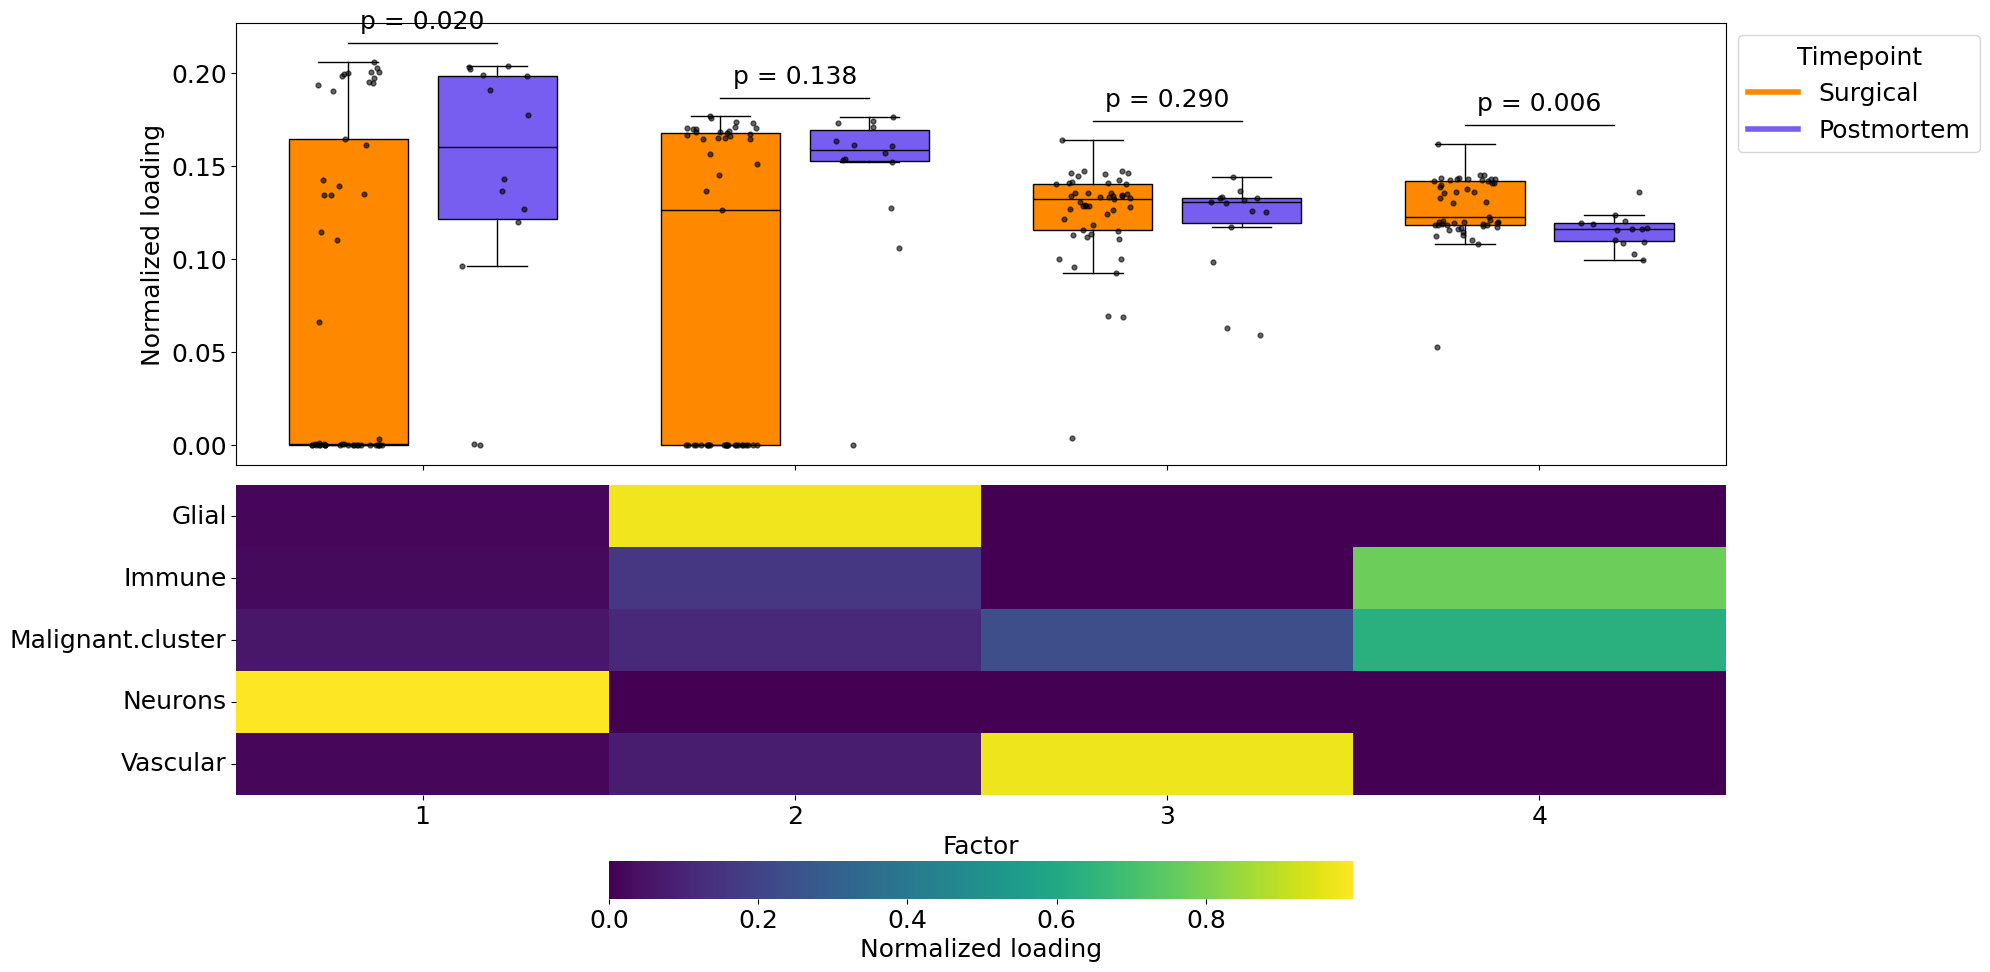

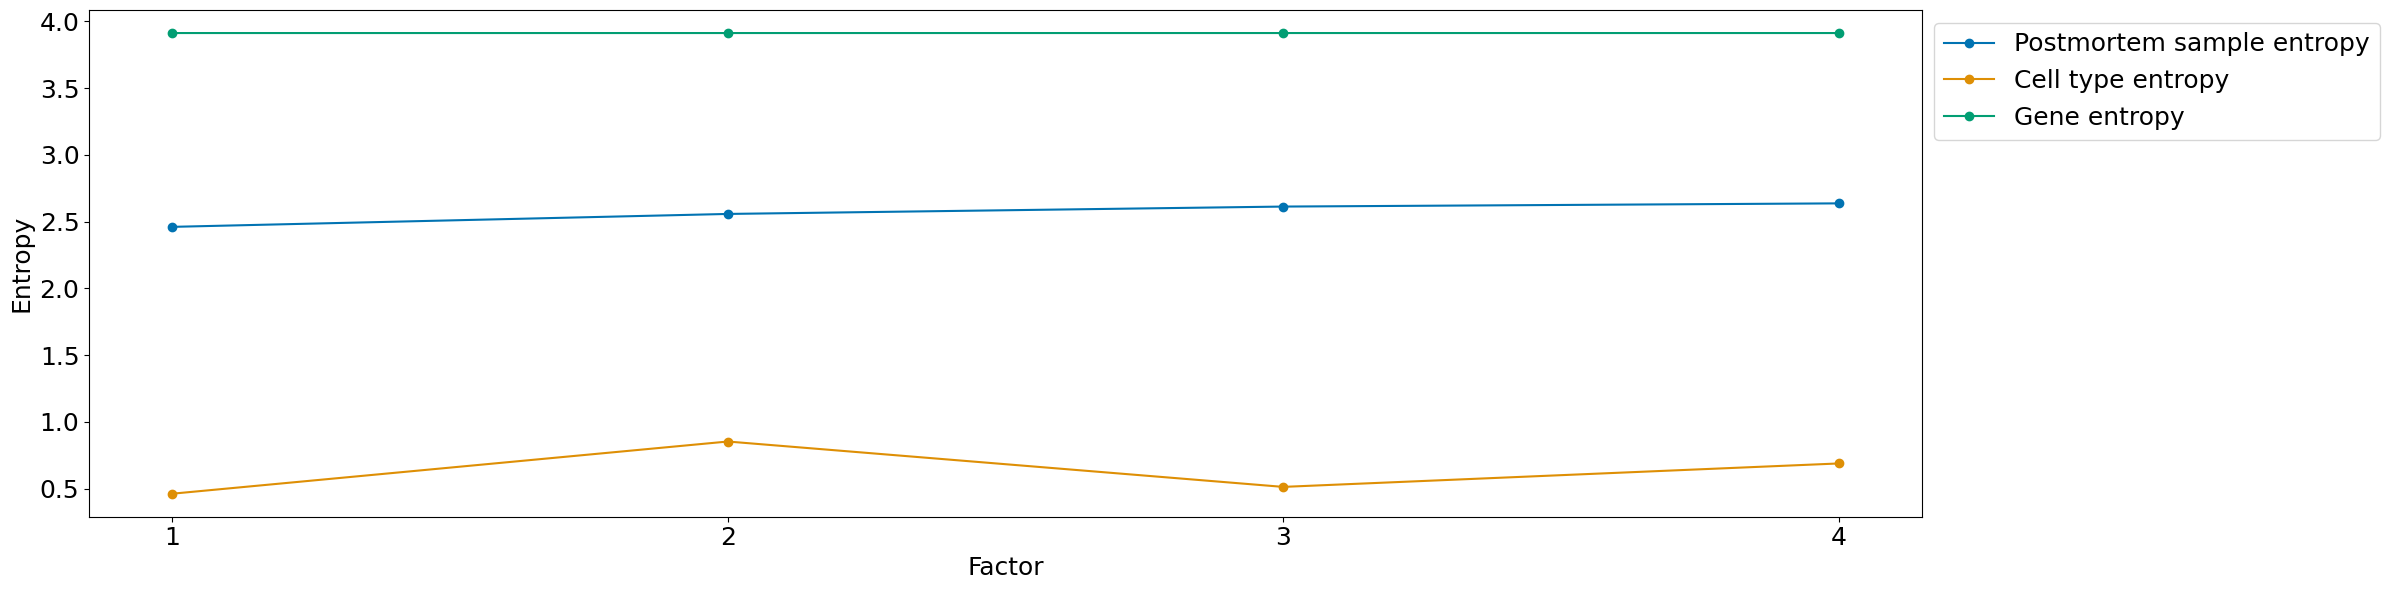


Factor: 1
RBFOX1', 'MT-CO3', 'KCNIP4', 'CNTNAP2', 'MT-CO2', 'FAM155A', 'NRXN1', 'SYT1', 'PCDH9', 'PTPRD', 'CSMD1', 'FGF14', 'ADGRB3', 'DLG2', 'MT-ATP6', 'NRXN3', 'CADM2', 'ROBO2', 'LRP1B', 'MT-ND4', 'NRG3', 'MAGI2', 'DLGAP1', 'NRG1', 'MT-ND3', 'ANK2', 'DPP6', 'CTNNA2', 'GRIK2', 'MT-CYB', 'ADGRL3', 'ANKS1B', 'MT-ND1', 'CTNND2', 'NAV3', 'NEGR1', 'MYT1L', 'DSCAM', 'KAZN', 'RIMS2', 'RGS7', 'MAP2', 'FRMD4A', 'ANK3', 'MT-ND2', 'CELF2', 'RYR2', 'NLGN1', 'HFM1', 'STXBP5L', 'RORA', 'CNTN1', 'IQCJ-SCHIP1', 'PLCB1', 'NCAM1', 'CCSER1', 'KCND2', 'NCAM2', 'PDE4D', 'IL1RAPL1', 'PCLO', 'DOCK3', 'MACROD2', 'PDE4DIP', 'AGBL4', 'KCNQ5', 'ATP8A2', 'CACNA1C', 'LRRTM4', 'MAPK10', 'KCNMA1', 'TENM2', 'AKAP6', 'FGF12', 'CELF4', 'ERC2', 'SNAP25', 'MDGA2', 'PPP2R2B', 'CADPS', 'DMD', 'LRRC4C', 'PTPRN2', 'NRCAM', 'CACNA1B', 'SLC8A1', 'PPFIA2', 'PHACTR1', 'SPOCK1', 'SYN2', 'TMEM178B', 'ERBB4', 'AFF3', 'KALRN', 'CADM1', 'CACNA2D3', 'NKAIN2', 'DCLK1', 'SNAP91', 'CALM1

Factor: 2
PCDH9', 'PPP2R2B', 'CADM2', 'MAGI2', 

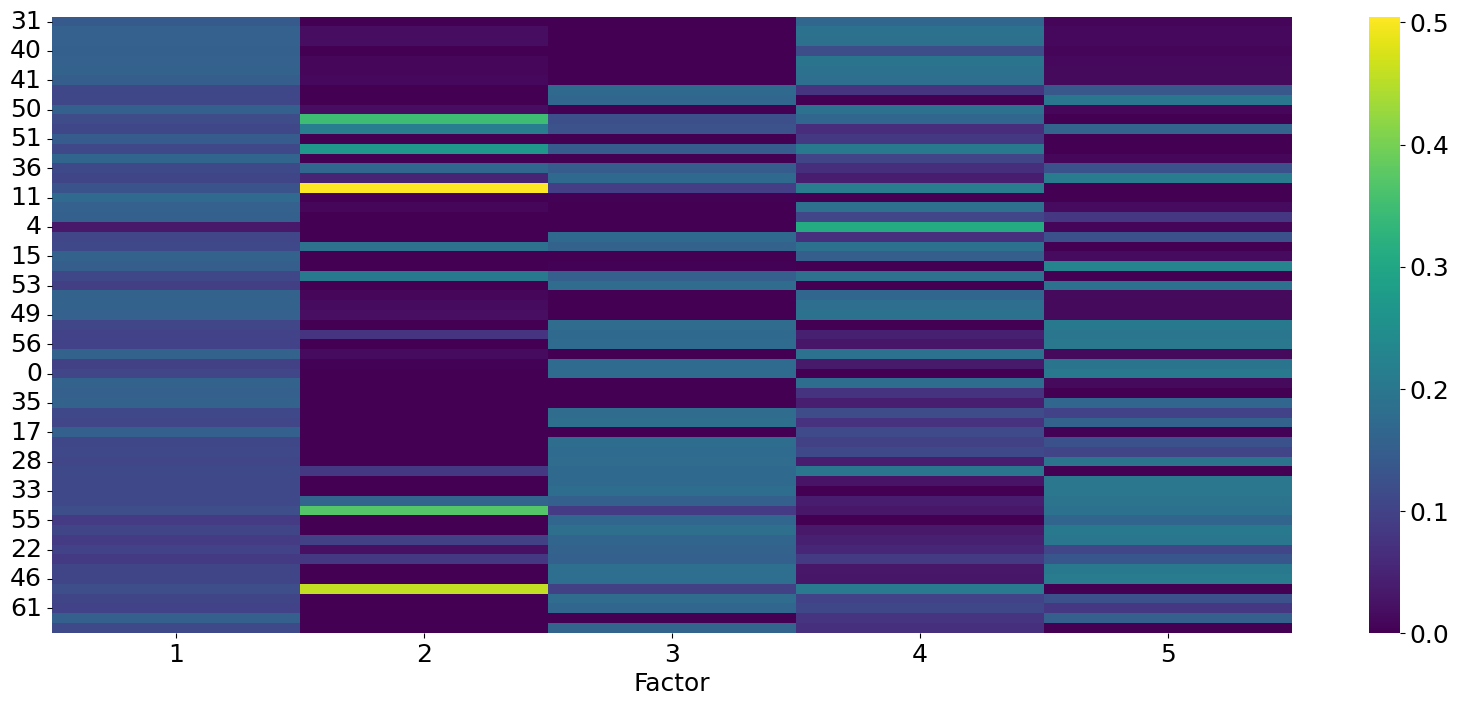

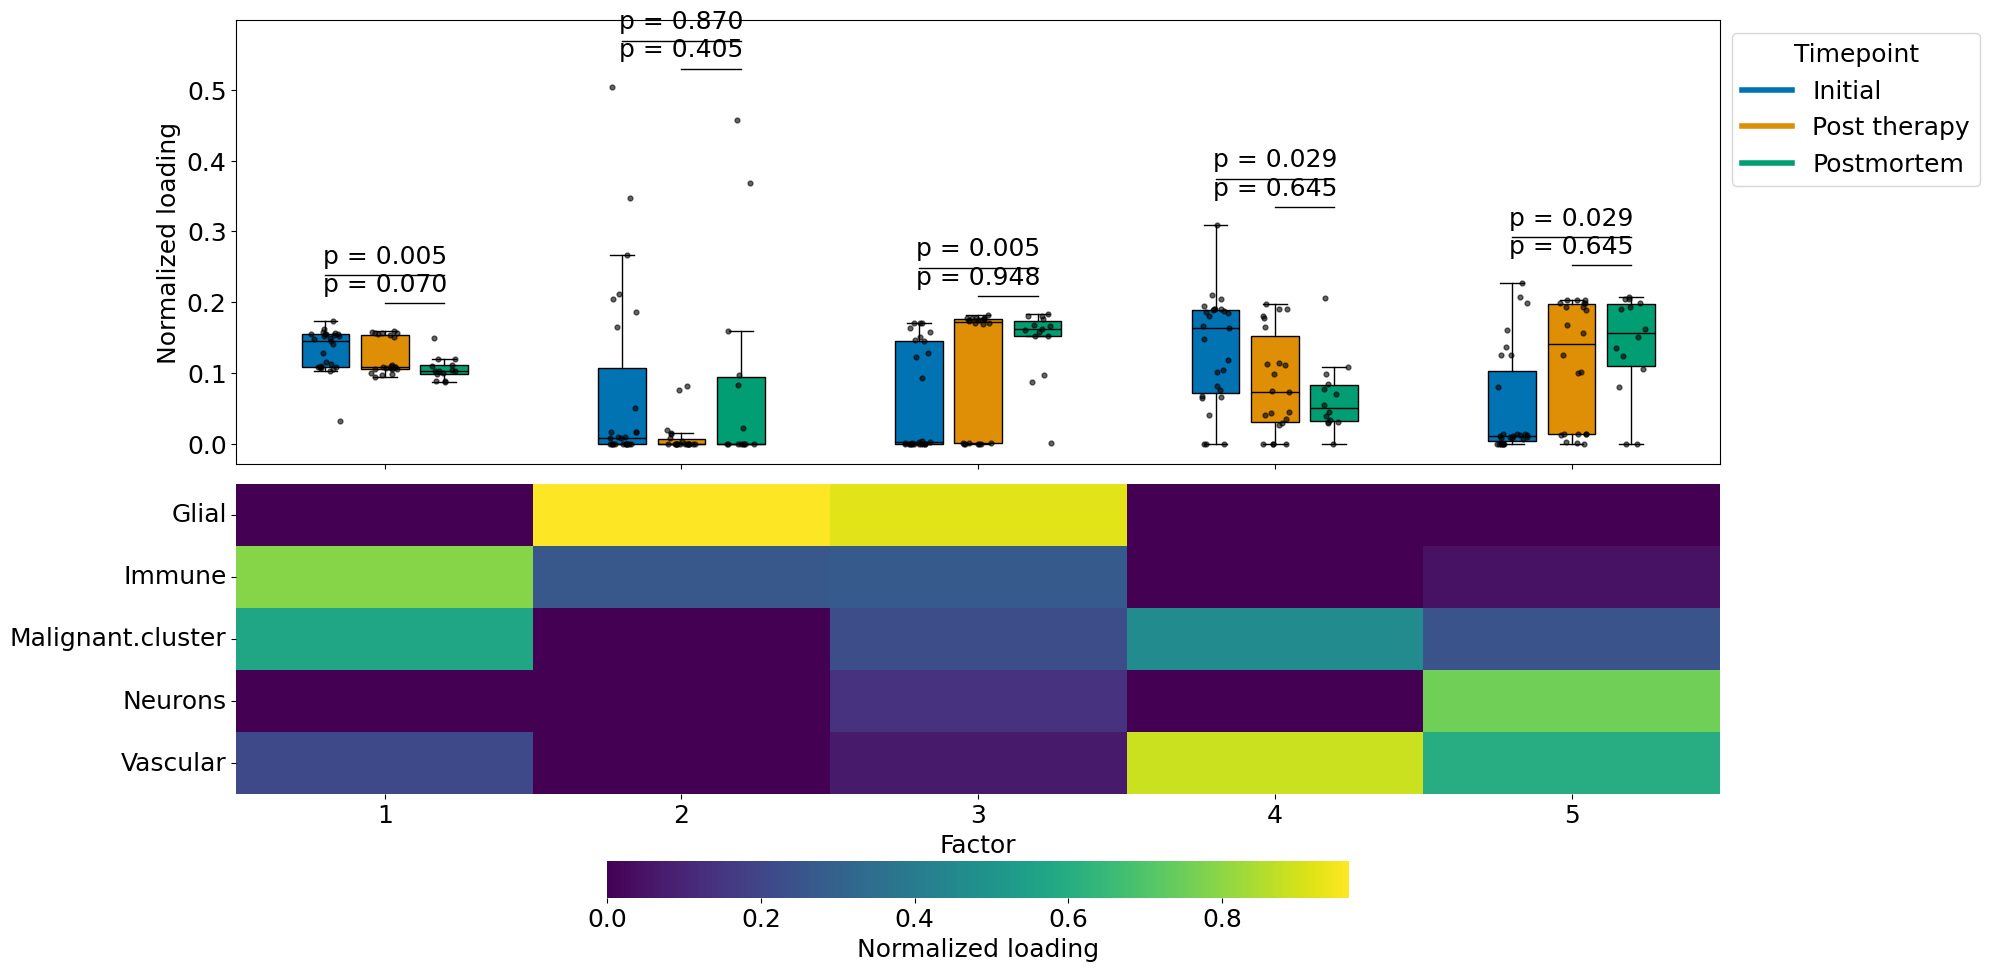

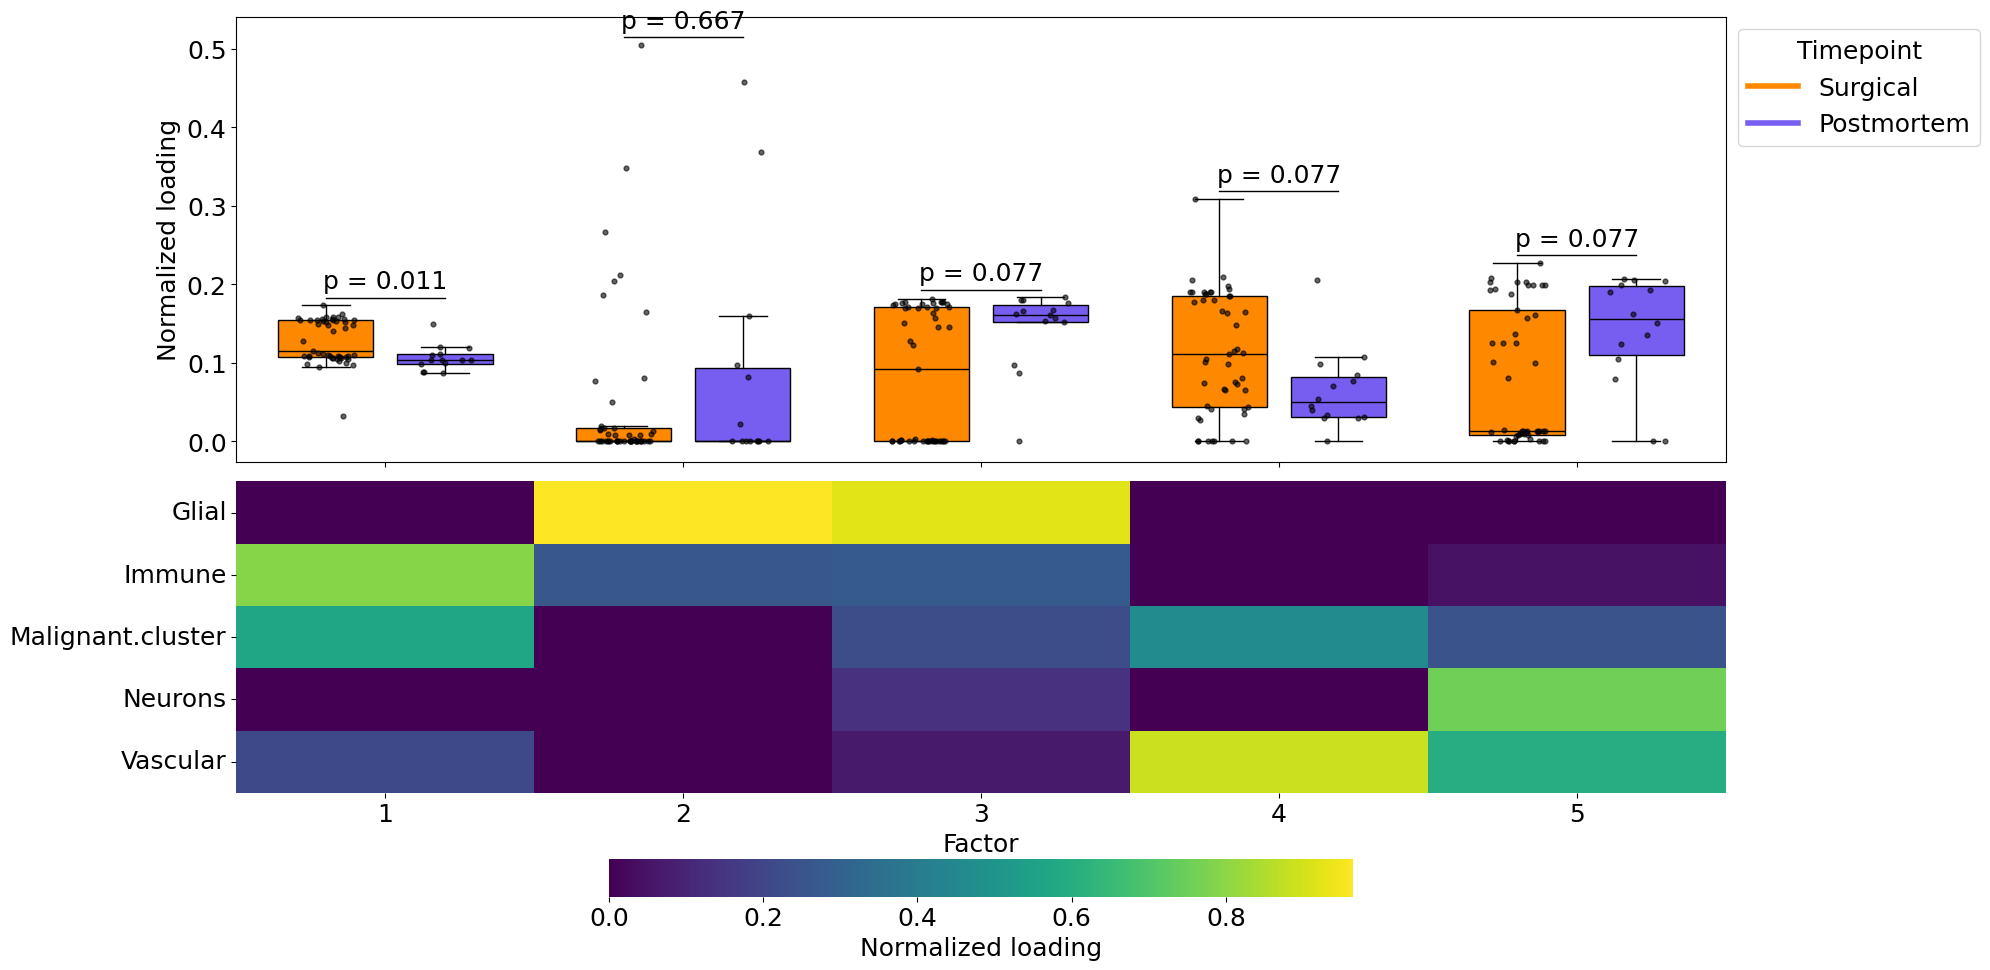

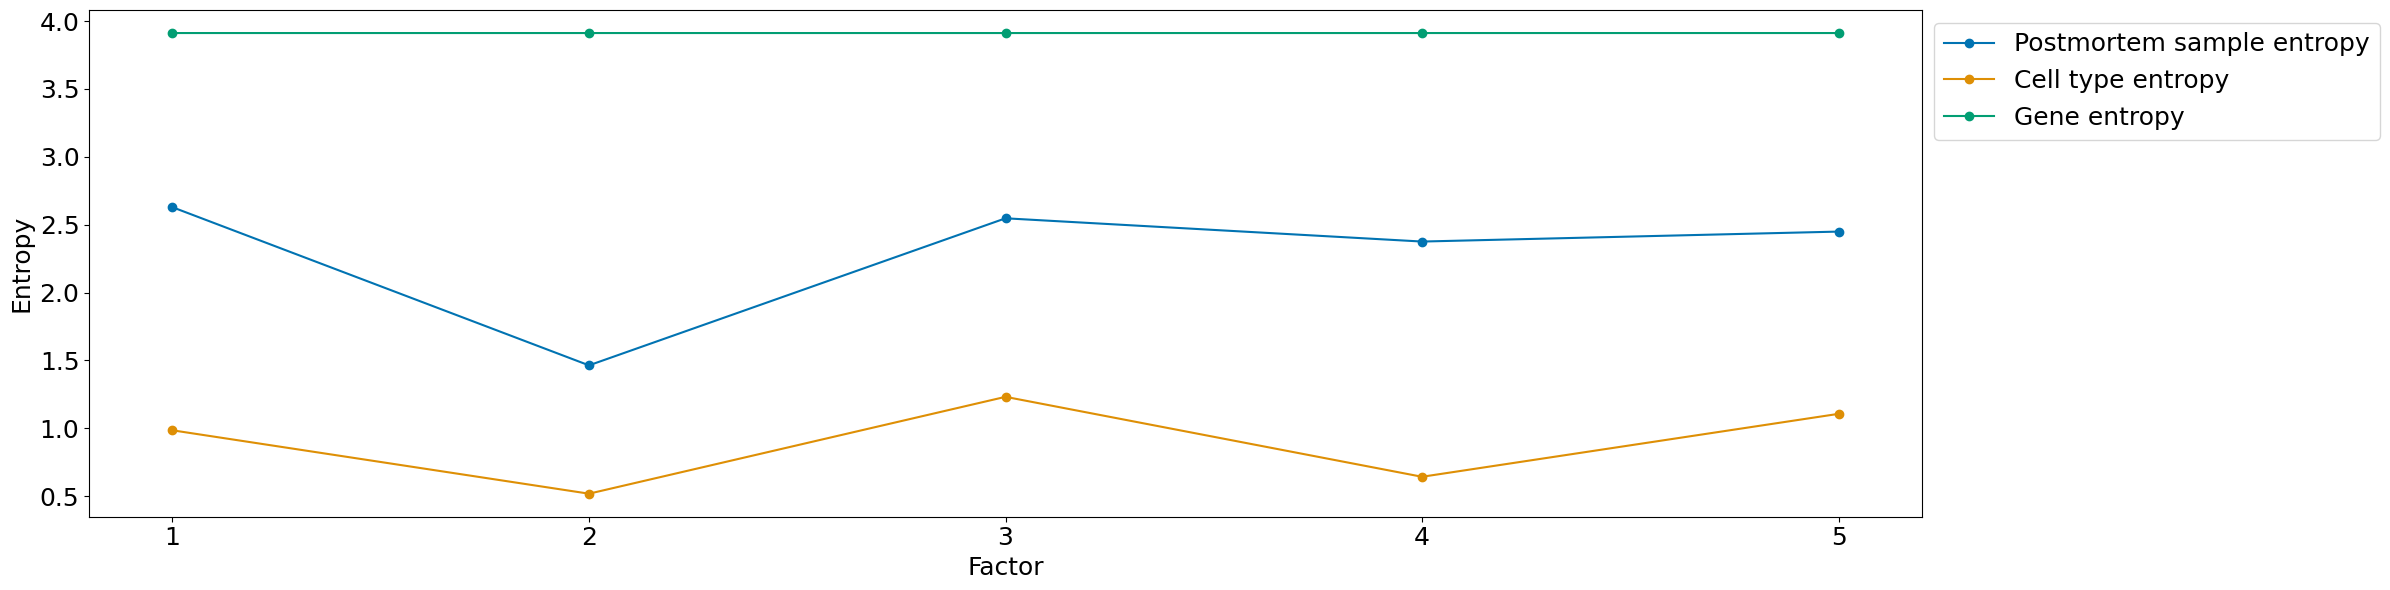


Factor: 1
PLXDC2', 'DOCK4', 'LRMDA', 'SPP1', 'FRMD4A', 'MT-CO3', 'CHST11', 'FMNL2', 'LDLRAD4', 'SLC8A1', 'SFMBT2', 'MT-CO2', 'DOCK8', 'APBB1IP', 'FOXN3', 'MT-ATP6', 'KCNQ3', 'MEF2A', 'MAML2', 'CELF2', 'RBM47', 'ARHGAP15', 'ELMO1', 'TBXAS1', 'ARHGAP24', 'ARHGAP26', 'PTPRJ', 'MT-ND3', 'ST6GAL1', 'SLCO2B1', 'FYB1', 'SLC1A3', 'DPYD', 'CYRIB', 'MT-ND4', 'ABR', 'ZEB2', 'SAT1', 'DOCK2', 'MEF2C', 'AKAP13', 'ITPR2', 'PTPRC', 'SSH2', 'EPB41L2', 'MERTK', 'TBC1D22A', 'SLC11A1', 'ZSWIM6', 'CTSB', 'MBNL1', 'INPP5D', 'ETV6', 'MT-CYB', 'SRGN', 'LYN', 'APOE', 'RUNX1', 'FMN1', 'PICALM', 'PIK3R5', 'MSR1', 'RAB31', 'FCHSD2', 'ANKRD44', 'RAPGEF1', 'ATP8B4', 'BMP2K', 'SH3RF3', 'FTL', 'ATG7', 'SLC9A9', 'MT-ND1', 'SAMSN1', 'KCNMA1', 'FGD4', 'ZFHX3', 'BNC2', 'CD74', 'IKZF1', 'MAML3', 'GAB2', 'FRMD4B', 'DOCK10', 'TNS3', 'LCP2', 'PRKCA', 'SIPA1L1', 'TBC1D5', 'CHD9', 'MT-ND2', 'FKBP5', 'MYO9B', 'LIMS1', 'ELL2', 'MYO1F', 'SRGAP2', 'ADAM28', 'RAD51B', 'HFM1

Factor: 2
RBFOX1', 'CNTNAP2', 'FAM155A', 'MT-CO3', 'CSMD

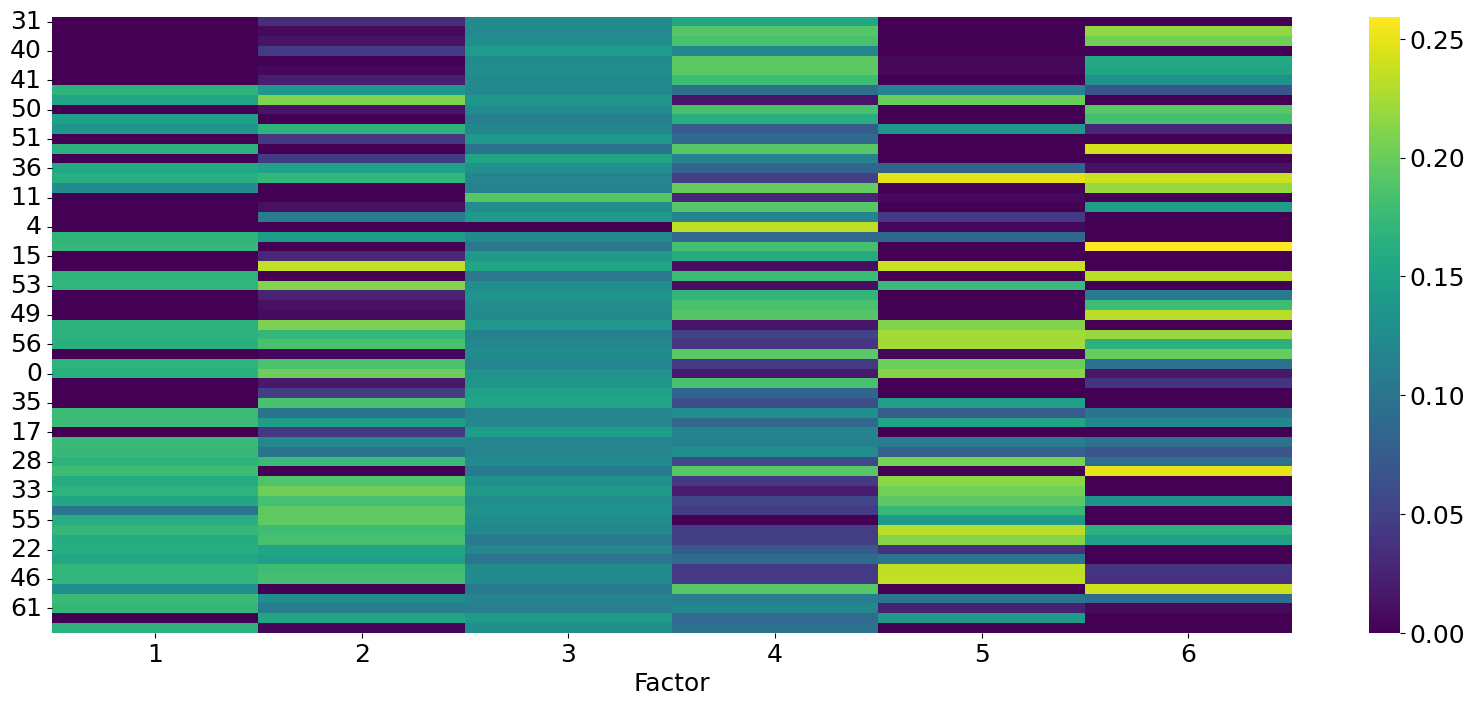

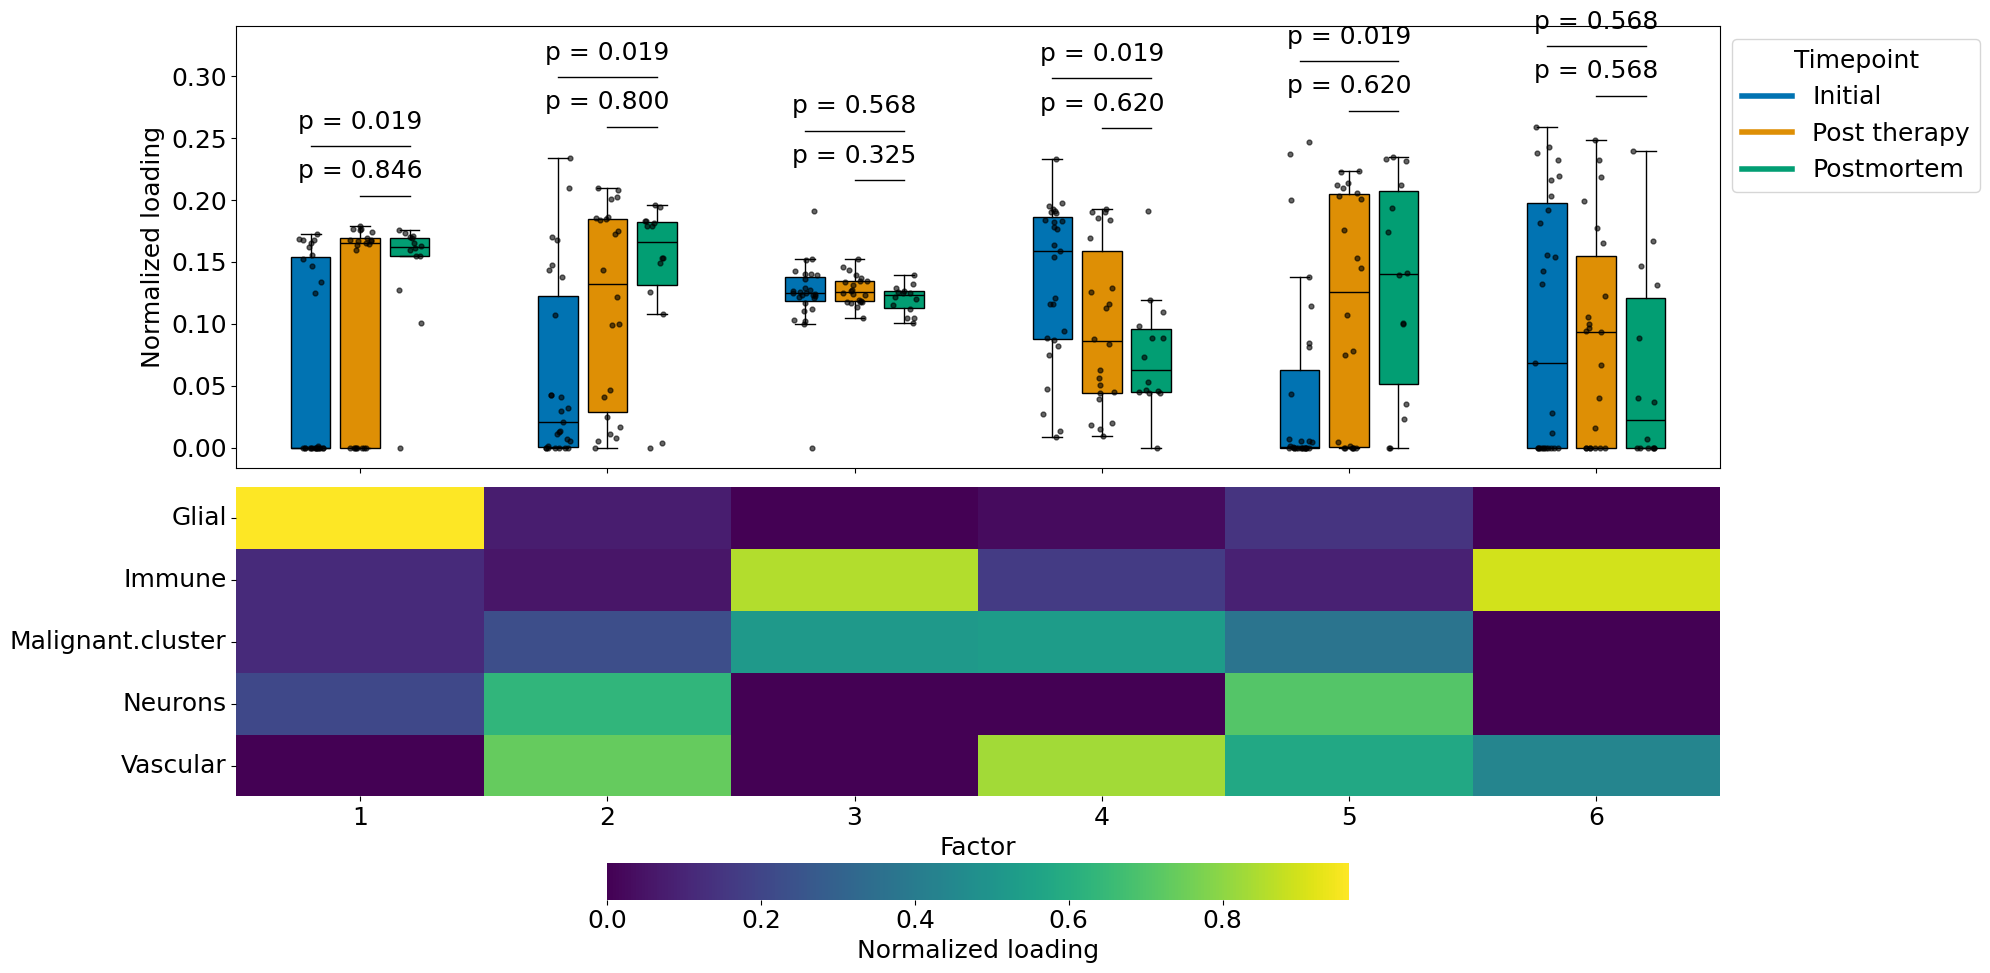

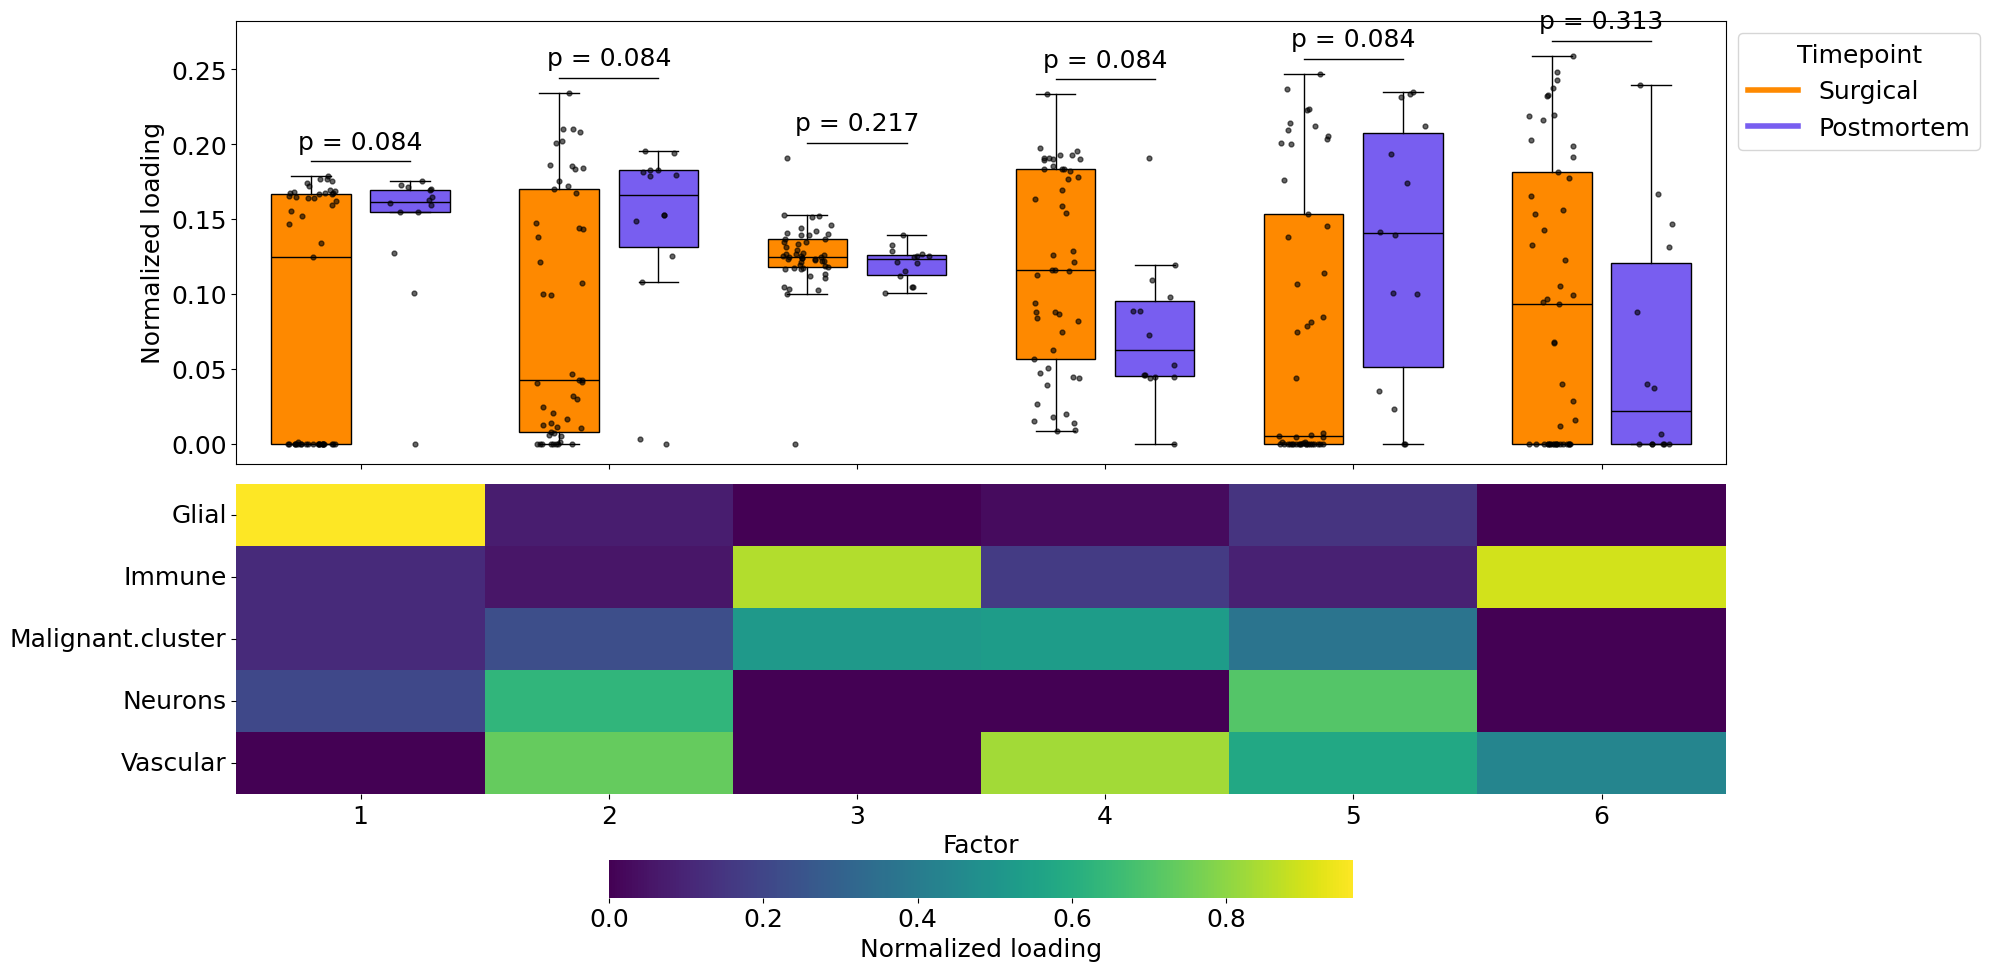

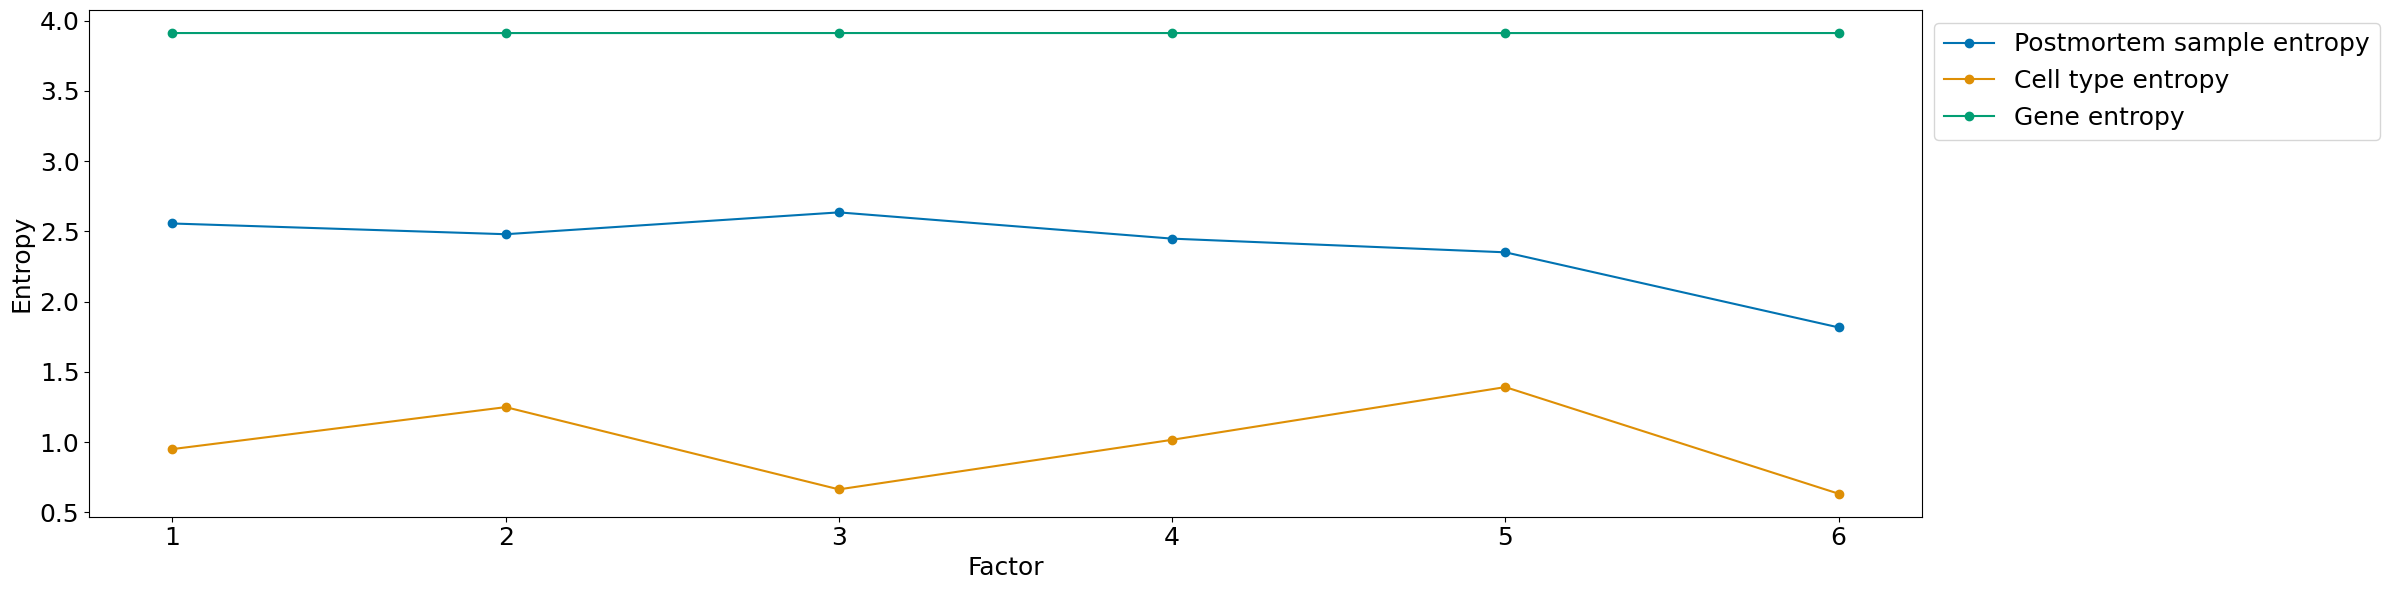


Factor: 1
RBFOX1', 'MT-CO3', 'KCNIP4', 'CNTNAP2', 'MT-CO2', 'FAM155A', 'NRXN1', 'SYT1', 'PCDH9', 'PTPRD', 'CSMD1', 'MT-ATP6', 'ADGRB3', 'DLG2', 'FGF14', 'NRXN3', 'CADM2', 'MT-ND4', 'ROBO2', 'LRP1B', 'MAGI2', 'NRG3', 'DLGAP1', 'MT-ND3', 'NRG1', 'ANK2', 'DPP6', 'MT-CYB', 'CTNNA2', 'GRIK2', 'MT-ND1', 'ADGRL3', 'ANKS1B', 'CTNND2', 'NAV3', 'NEGR1', 'DSCAM', 'FRMD4A', 'MYT1L', 'KAZN', 'MT-ND2', 'RIMS2', 'ANK3', 'MAP2', 'RGS7', 'CELF2', 'HFM1', 'RYR2', 'NLGN1', 'RORA', 'STXBP5L', 'IQCJ-SCHIP1', 'PLCB1', 'CNTN1', 'CCSER1', 'NCAM1', 'KCND2', 'PDE4D', 'NCAM2', 'IL1RAPL1', 'MACROD2', 'DOCK3', 'PDE4DIP', 'PCLO', 'KCNQ5', 'AGBL4', 'CACNA1C', 'KCNMA1', 'ATP8A2', 'MAPK10', 'LRRTM4', 'TENM2', 'AKAP6', 'ERC2', 'FGF12', 'MDGA2', 'PPP2R2B', 'DMD', 'SLC8A1', 'SNAP25', 'LRRC4C', 'CADPS', 'CELF4', 'PTPRN2', 'NRCAM', 'PHACTR1', 'PPFIA2', 'CACNA1B', 'SPOCK1', 'AFF3', 'ERBB4', 'TMEM178B', 'SYN2', 'KALRN', 'CADM1', 'CACNA2D3', 'CALM1', 'NKAIN2', 'PTK2', 'DCLK1

Factor: 2
HFM1', 'MT-CO3', 'MT-ND4', 'MT-CO2', 'M

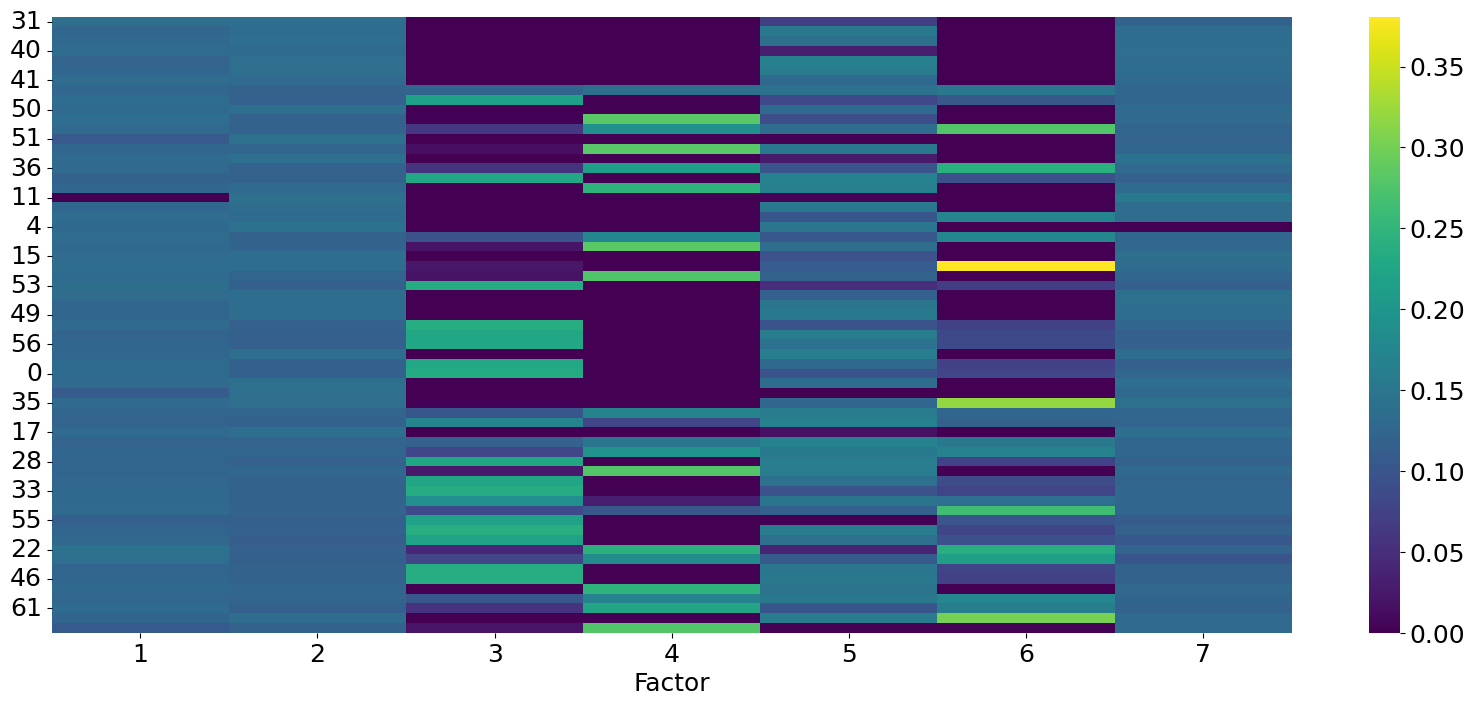

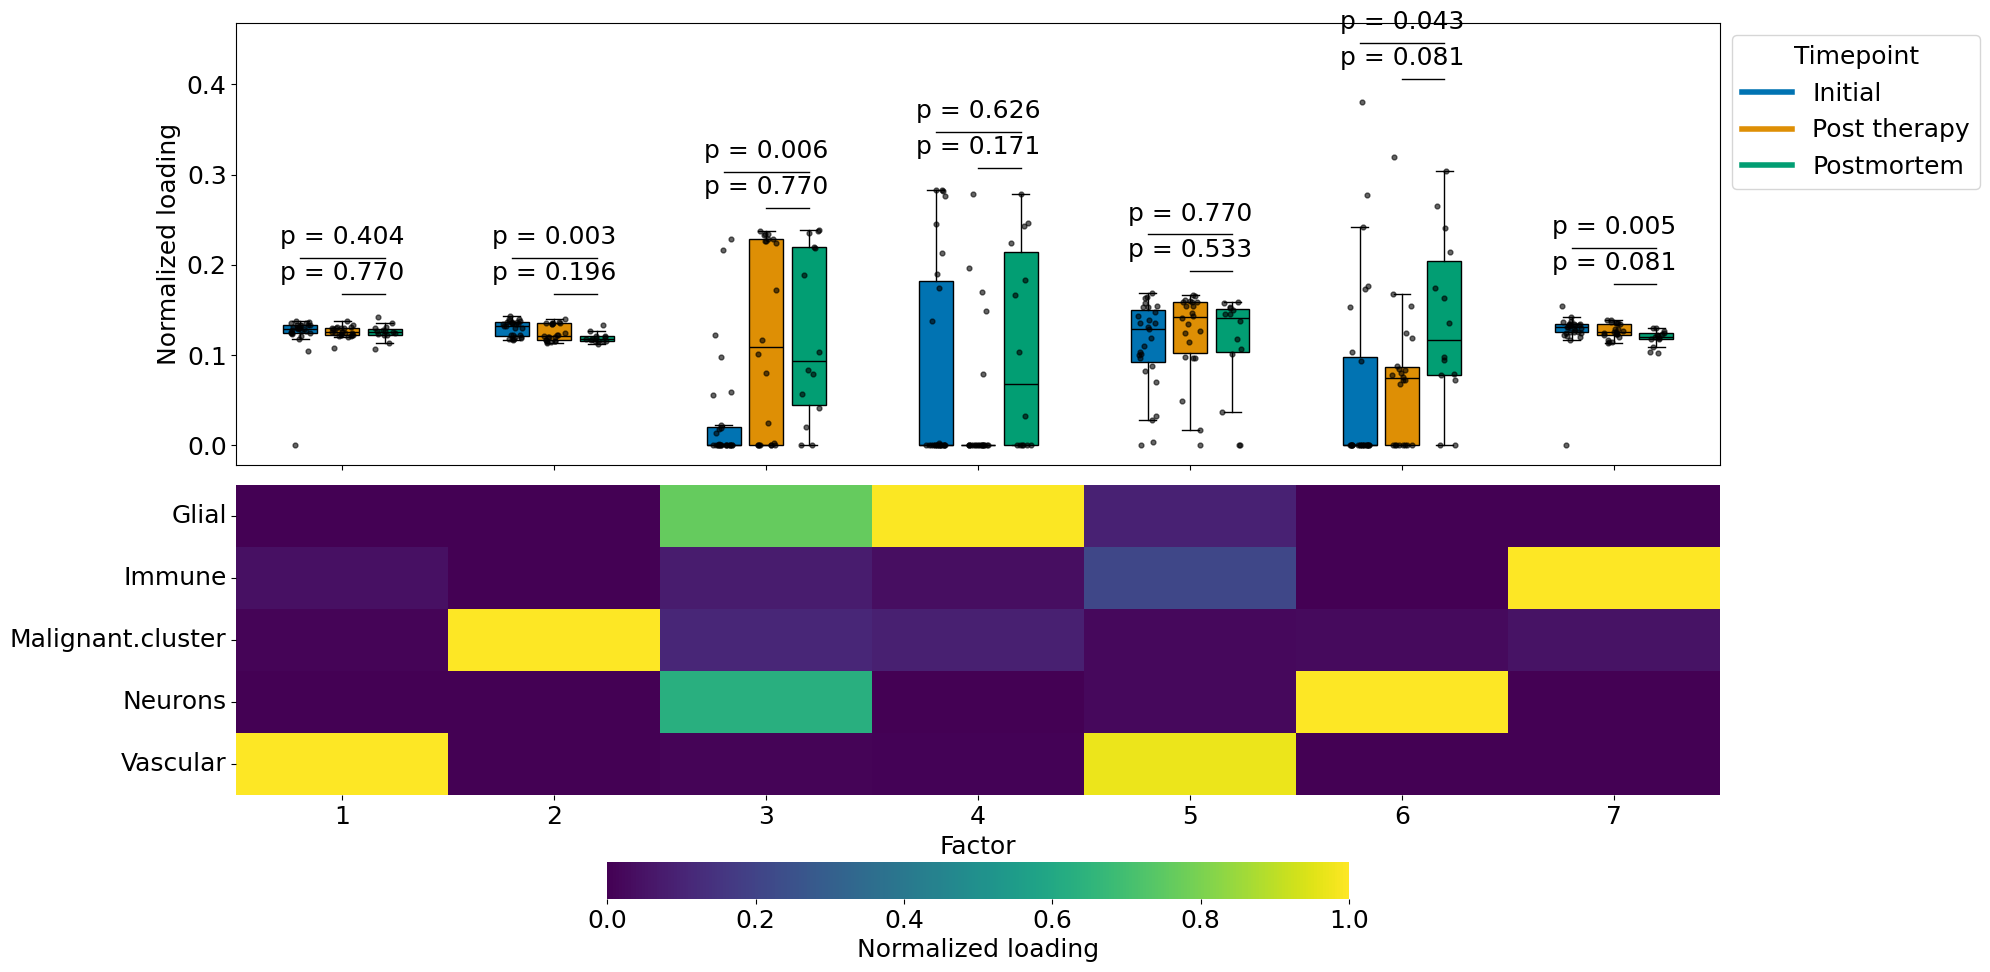

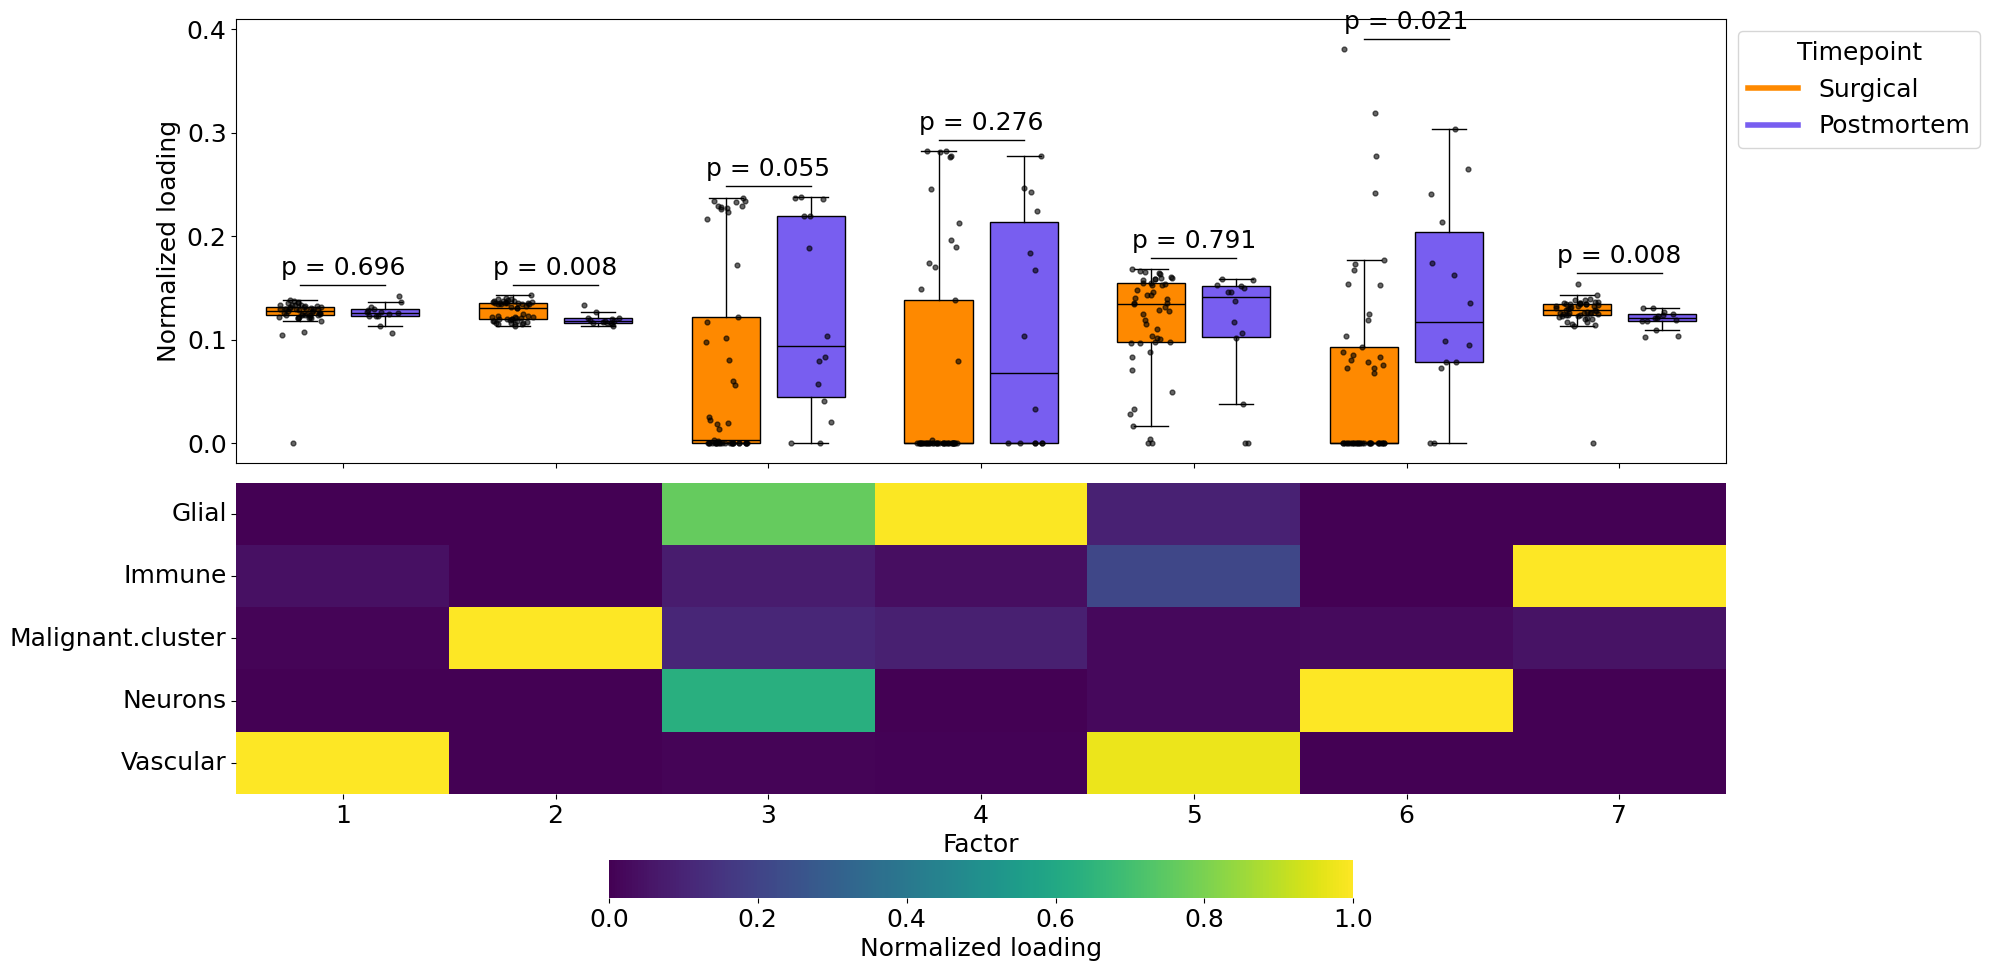

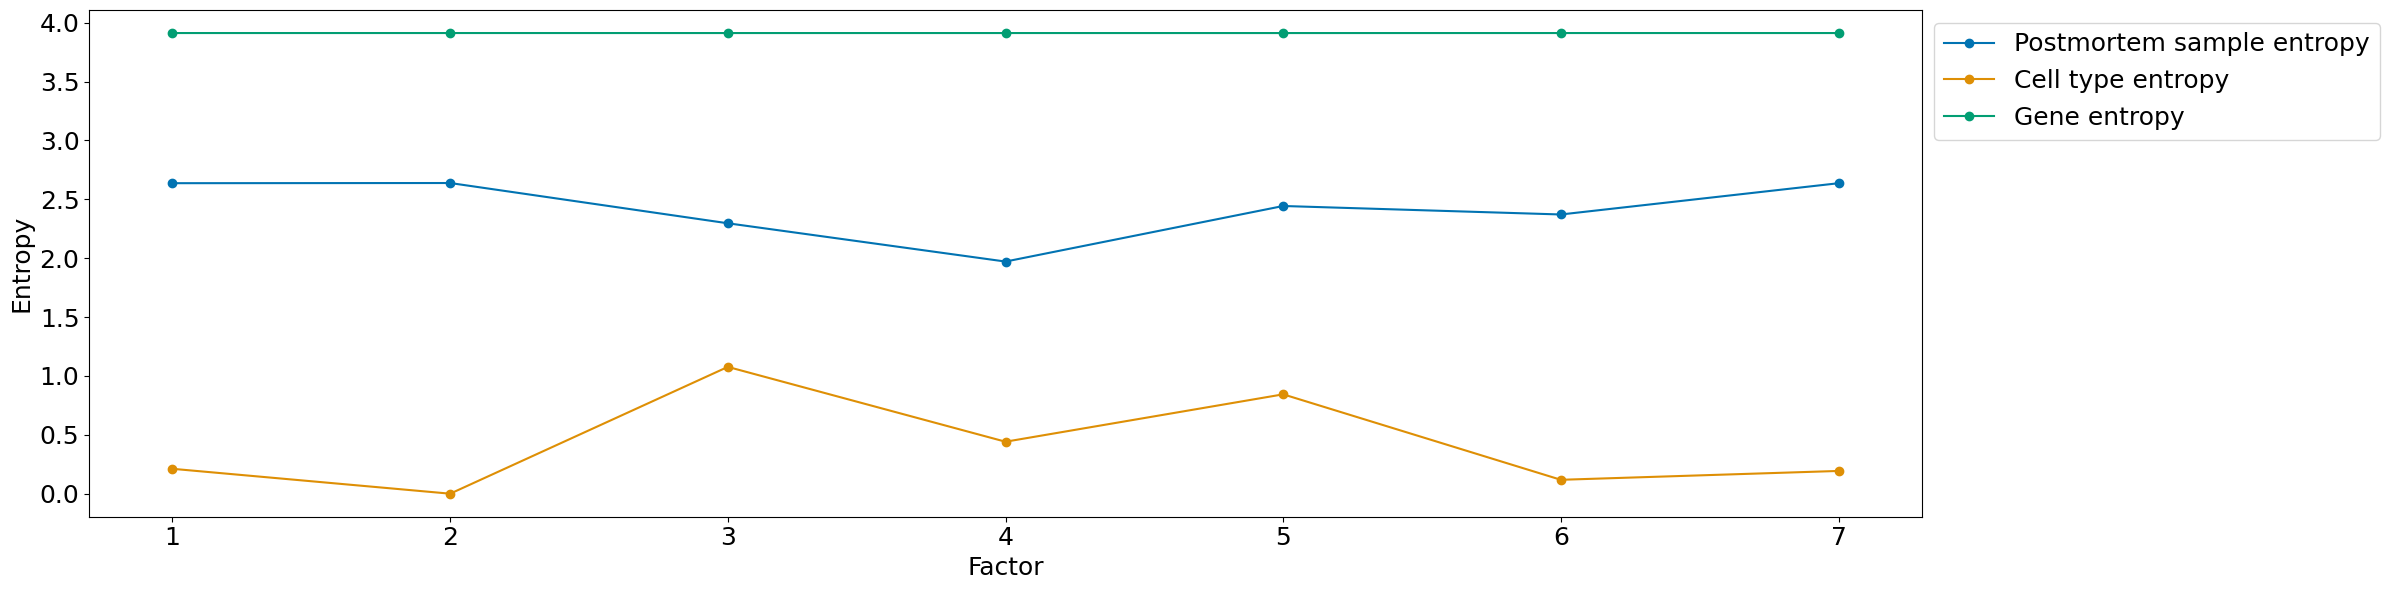


Factor: 1
MT-CO3', 'MT-CO2', 'MT-ATP6', 'PTPRG', 'MT-ND4', 'MT-CYB', 'MT-ND3', 'PTPRM', 'PDE4D', 'HFM1', 'RORA', 'ZEB1', 'ST6GALNAC3', 'INSR', 'GALNT18', 'PLEKHG1', 'FLT1', 'CALD1', 'UTRN', 'MT-ND2', 'ANGPT2', 'EPAS1', 'MAGI1', 'MT-ND1', 'IGFBP7', 'LRMDA', 'IQSEC1', 'PLCB1', 'FYN', 'FN1', 'CCNY', 'FNDC3B', 'MYO10', 'ARL15', 'BBS9', 'SPTBN1', 'MRTFB', 'MAML2', 'CACNA1C', 'NFIB', 'DOCK1', 'PARD3', 'ARHGAP26', 'BAZ2B', 'LHFPL6', 'PTK2', 'RPL13', 'CRIM1', 'PITPNC1', 'UACA', 'GRB10', 'IGF1R', 'MYO1E', 'USP34', 'TACC1', 'TMSB10', 'VIM', 'PPFIBP1', 'MBNL1', 'A2M', 'MEF2A', 'SASH1', 'CDC42BPA', 'PALM2AKAP2', 'PDZD2', 'MECOM', 'FLI1', 'MT-ND5', 'SLC7A5', 'PTEN', 'PEAK1', 'FOXN3', 'ANO2', 'CUX1', 'PRKCH', 'PICALM', 'AKAP13', 'SRPK2', 'DGKH', 'SEC14L1', 'SPARCL1', 'TJP1', 'CHD9', 'AFF1', 'PKP4', 'ARHGEF12', 'PAM', 'EBF1', 'ELMO1', 'APBB2', 'RASAL2', 'SOX5', 'SYNE2', 'RPS6KA2', 'ERC1', 'SVIL', 'ABLIM1', 'SLC22A23', 'TANC1', 'PRICKLE2

Factor: 2
MT-CO3', 'MT-CO2', 'NPAS3', 'MAGI2', 'MT-ATP6', 'PTP

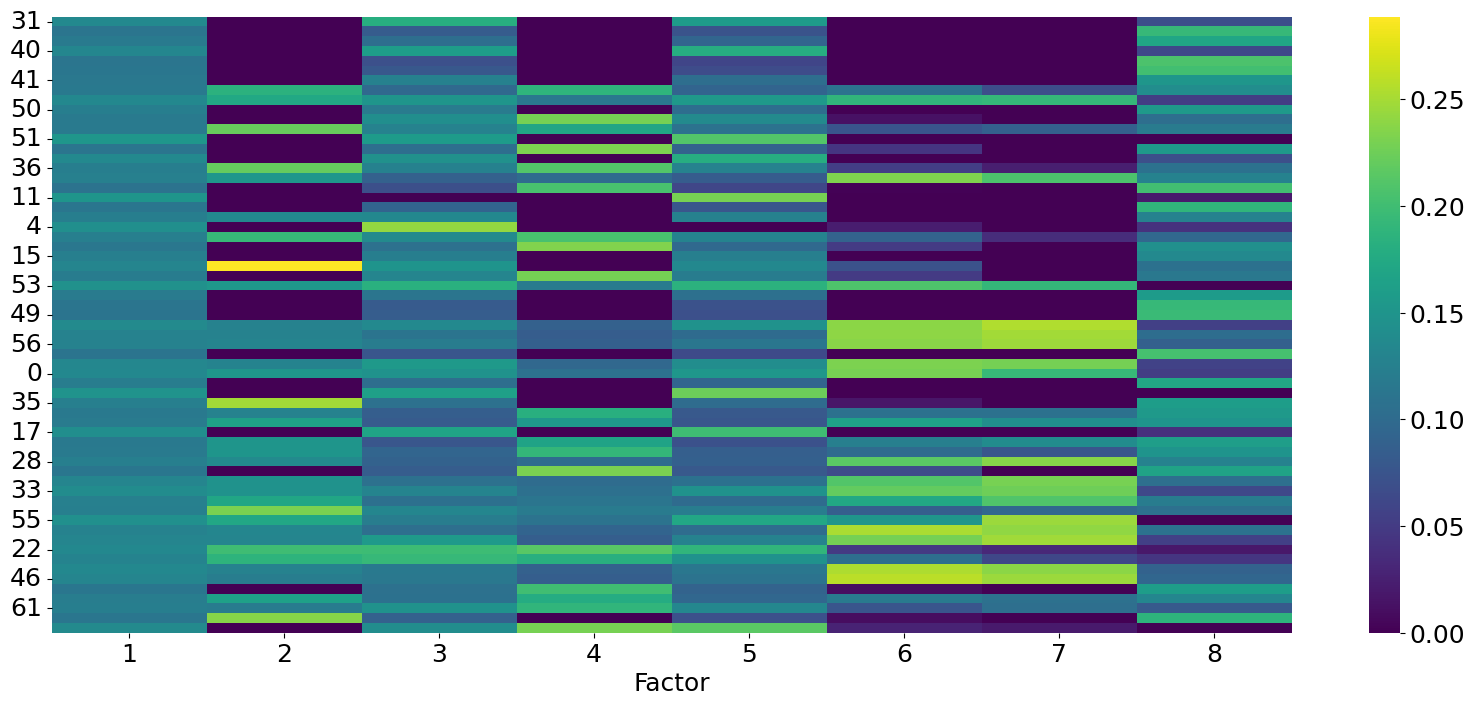

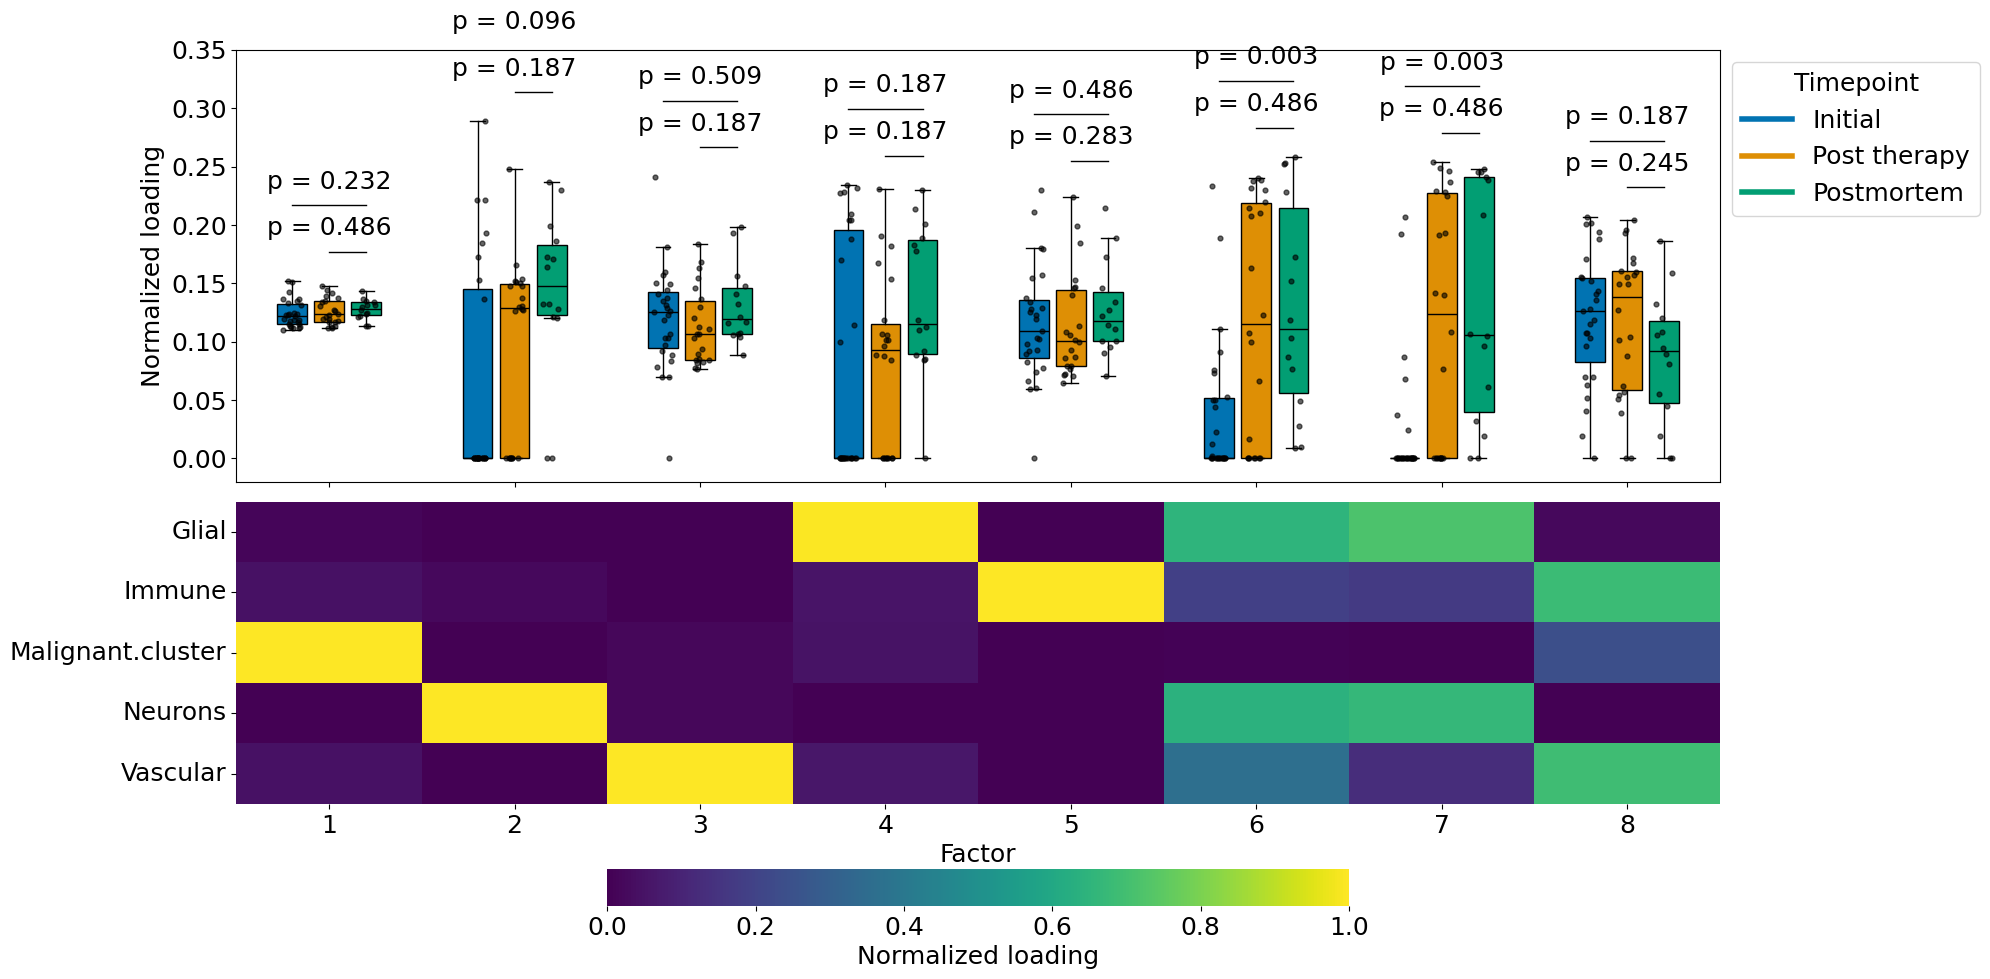

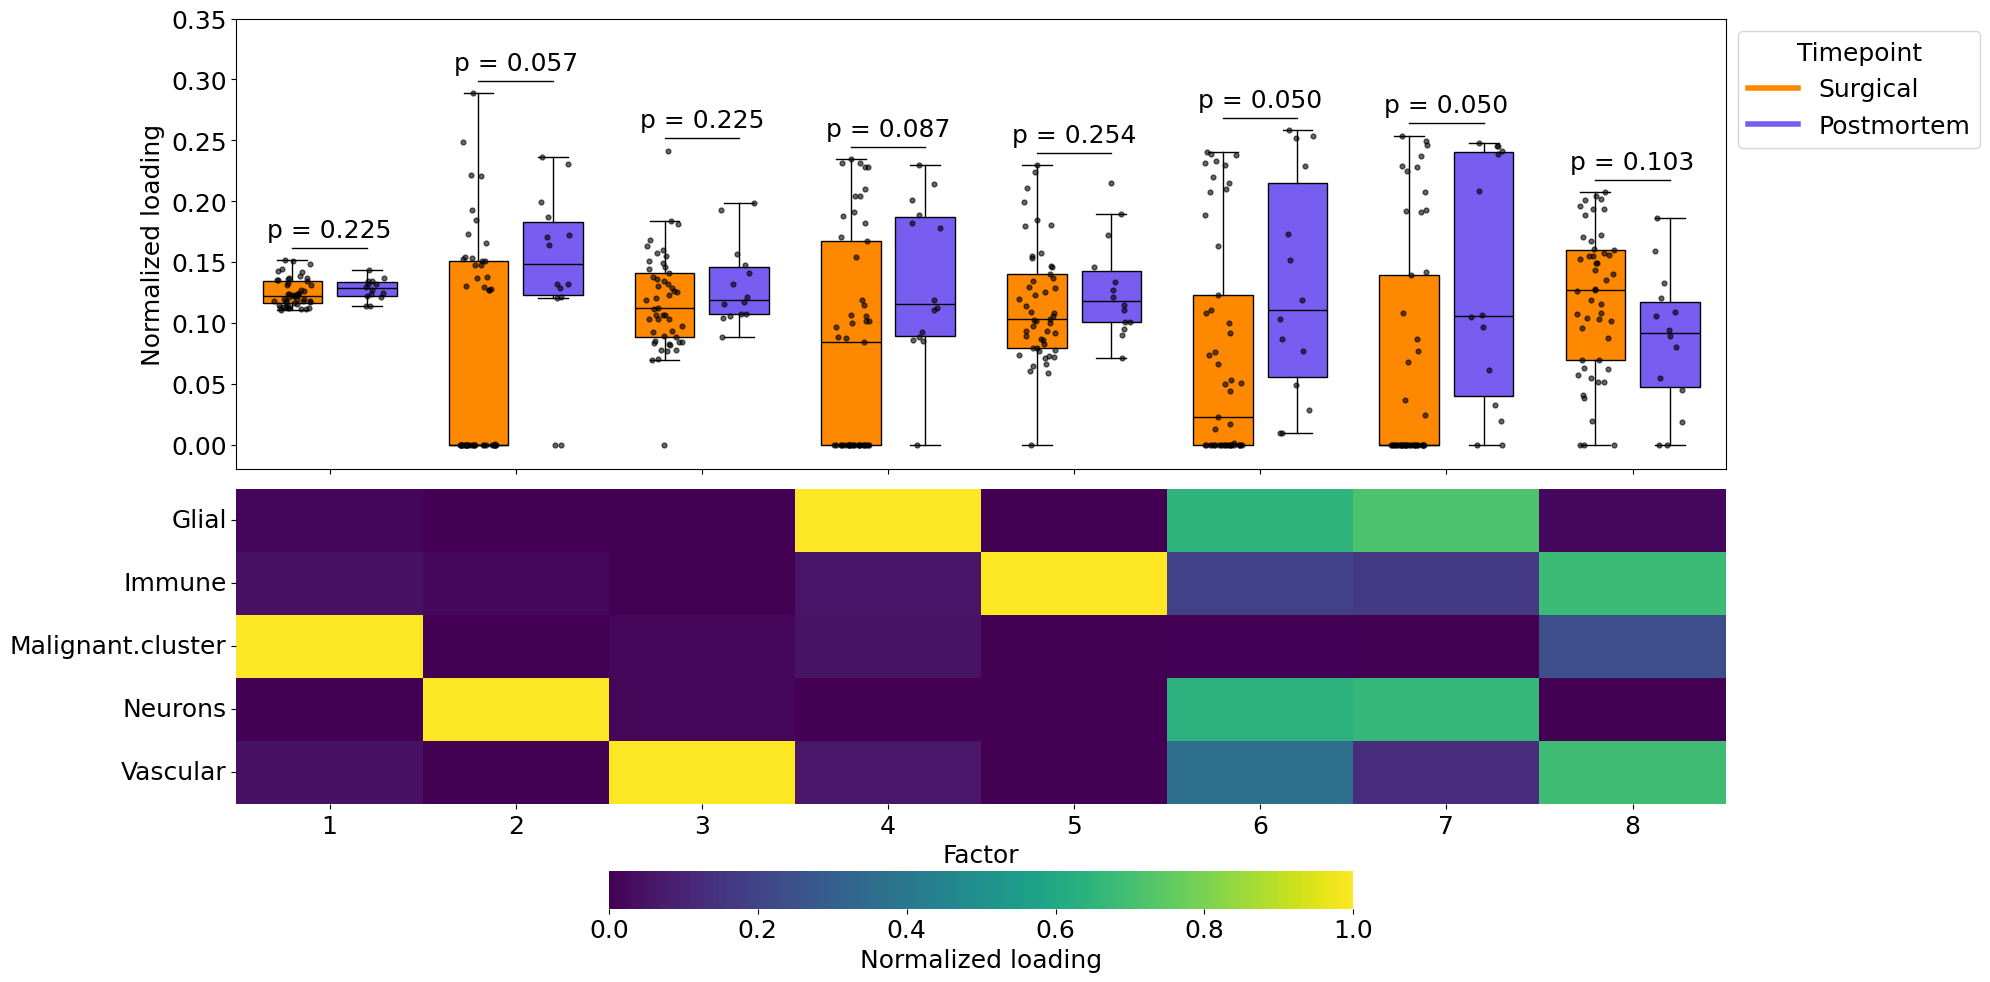

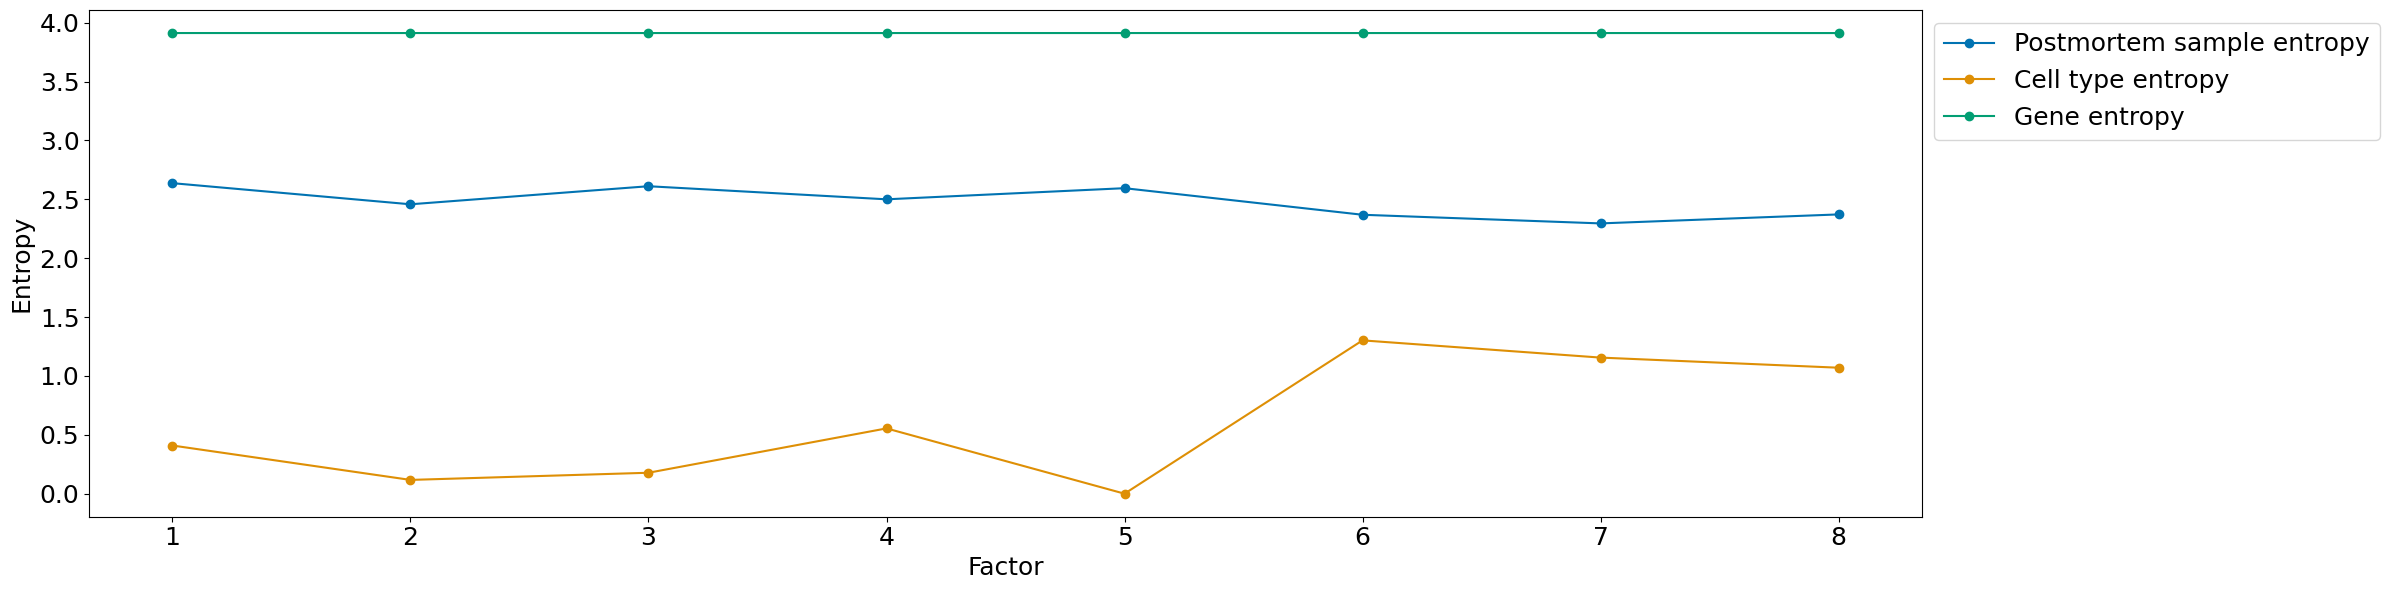


Factor: 1
MT-CO3', 'MT-CO2', 'MT-ATP6', 'LRP1B', 'ADGRB3', 'NPAS3', 'MAGI2', 'CADM2', 'NRXN1', 'PDE4B', 'PCDH9', 'DPP6', 'CTNND2', 'MT-ND4', 'MT-ND3', 'ADGRL3', 'MT-CYB', 'CTNNA2', 'DLG2', 'ANK2', 'NRXN3', 'KAZN', 'PRKCA', 'NLGN1', 'RORA', 'ZEB1', 'NCAM1', 'DTNA', 'MAML2', 'PPP2R2B', 'MAP2', 'FAM155A', 'ERBB4', 'CHD9', 'MT-ND1', 'HFM1', 'CSMD1', 'RBFOX1', 'FRMD5', 'NTM', 'PDE4D', 'MT-ND2', 'PTPRZ1', 'PSD3', 'PTPRG', 'LRRC4C', 'FMNL2', 'GPM6B', 'FRMD4A', 'BICD1', 'GPM6A', 'NRCAM', 'CADM1', 'DSCAM', 'DCLK1', 'KCNIP4', 'NCAM2', 'DOCK4', 'NOVA1', 'KCND2', 'GPC6', 'IL1RAPL1', 'ANKS1B', 'ROBO2', 'NF1', 'MAGI1', 'CELF2', 'NAV2', 'MAPK10', 'PTK2', 'NRG3', 'BAZ2B', 'SIK3', 'DNM3', 'TBC1D5', 'SORBS1', 'XYLT1', 'EXT1', 'TMEM178B', 'SOX5', 'PTPRD', 'ARHGAP21', 'PLCB1', 'TRPS1', 'ERC1', 'AKAP13', 'USP34', 'GRIK2', 'MSRA', 'RBFOX2', 'FGF14', 'SLC1A3', 'FBXO11', 'NAALADL2', 'DLGAP1', 'AKAP6', 'DMD', 'RPLP1', 'ZEB2', 'NLGN4X

Factor: 2
RBFOX1', 'CNTNAP2', 'FAM155A', 'MT-CO3', 'CSMD1', 'MT-CO2', 'PCDH

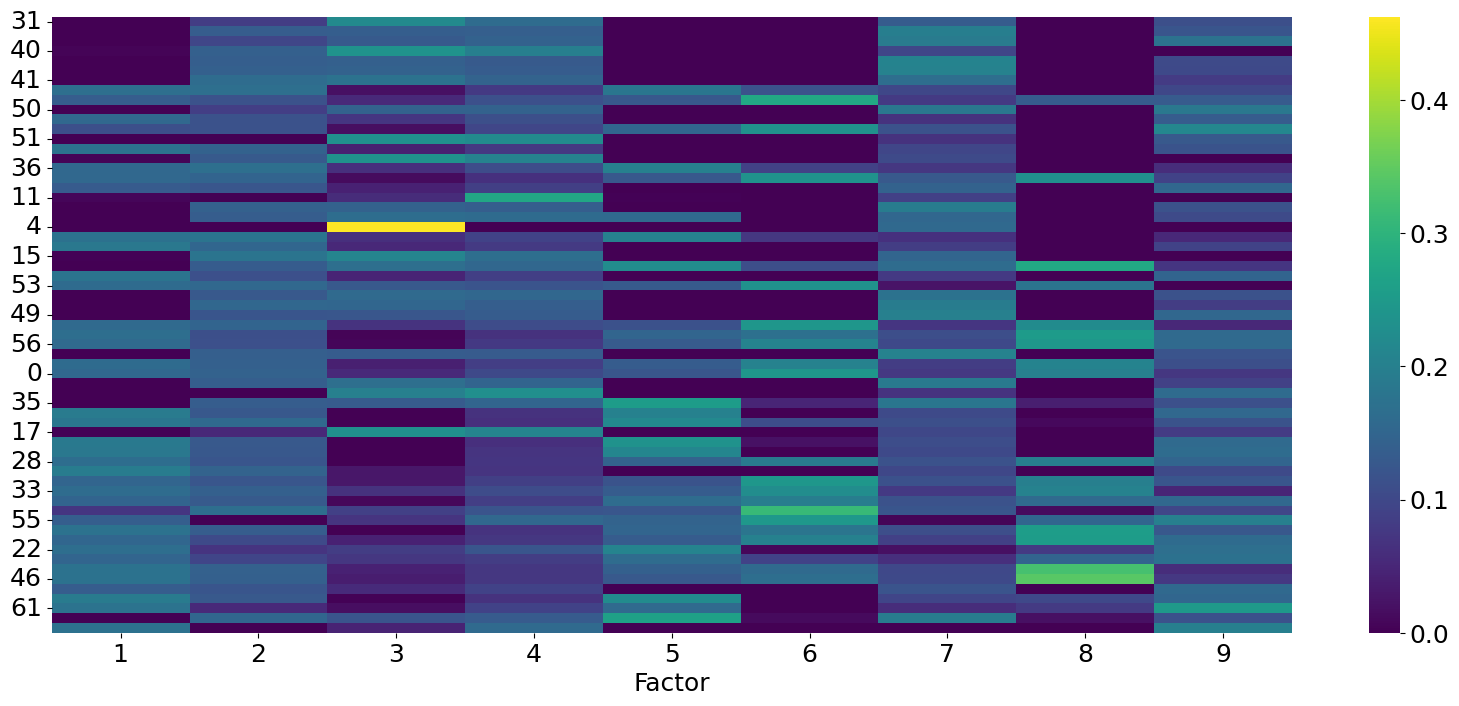

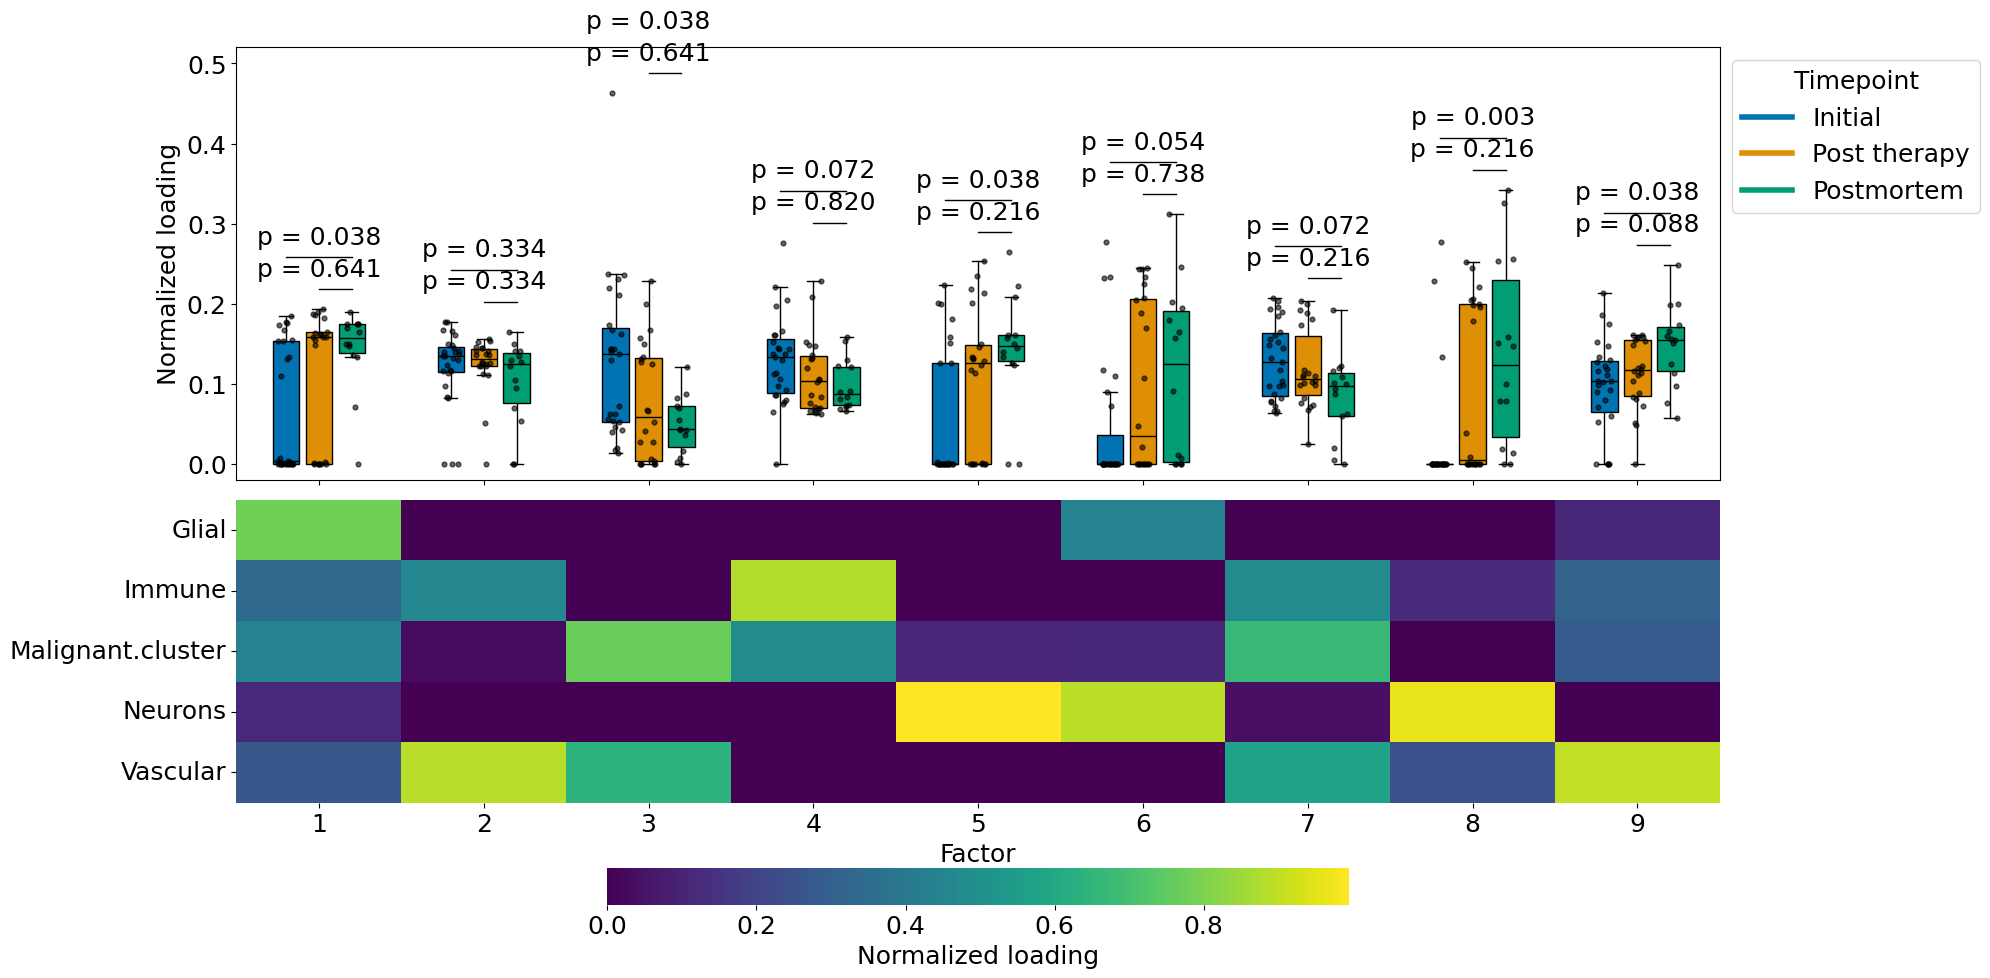

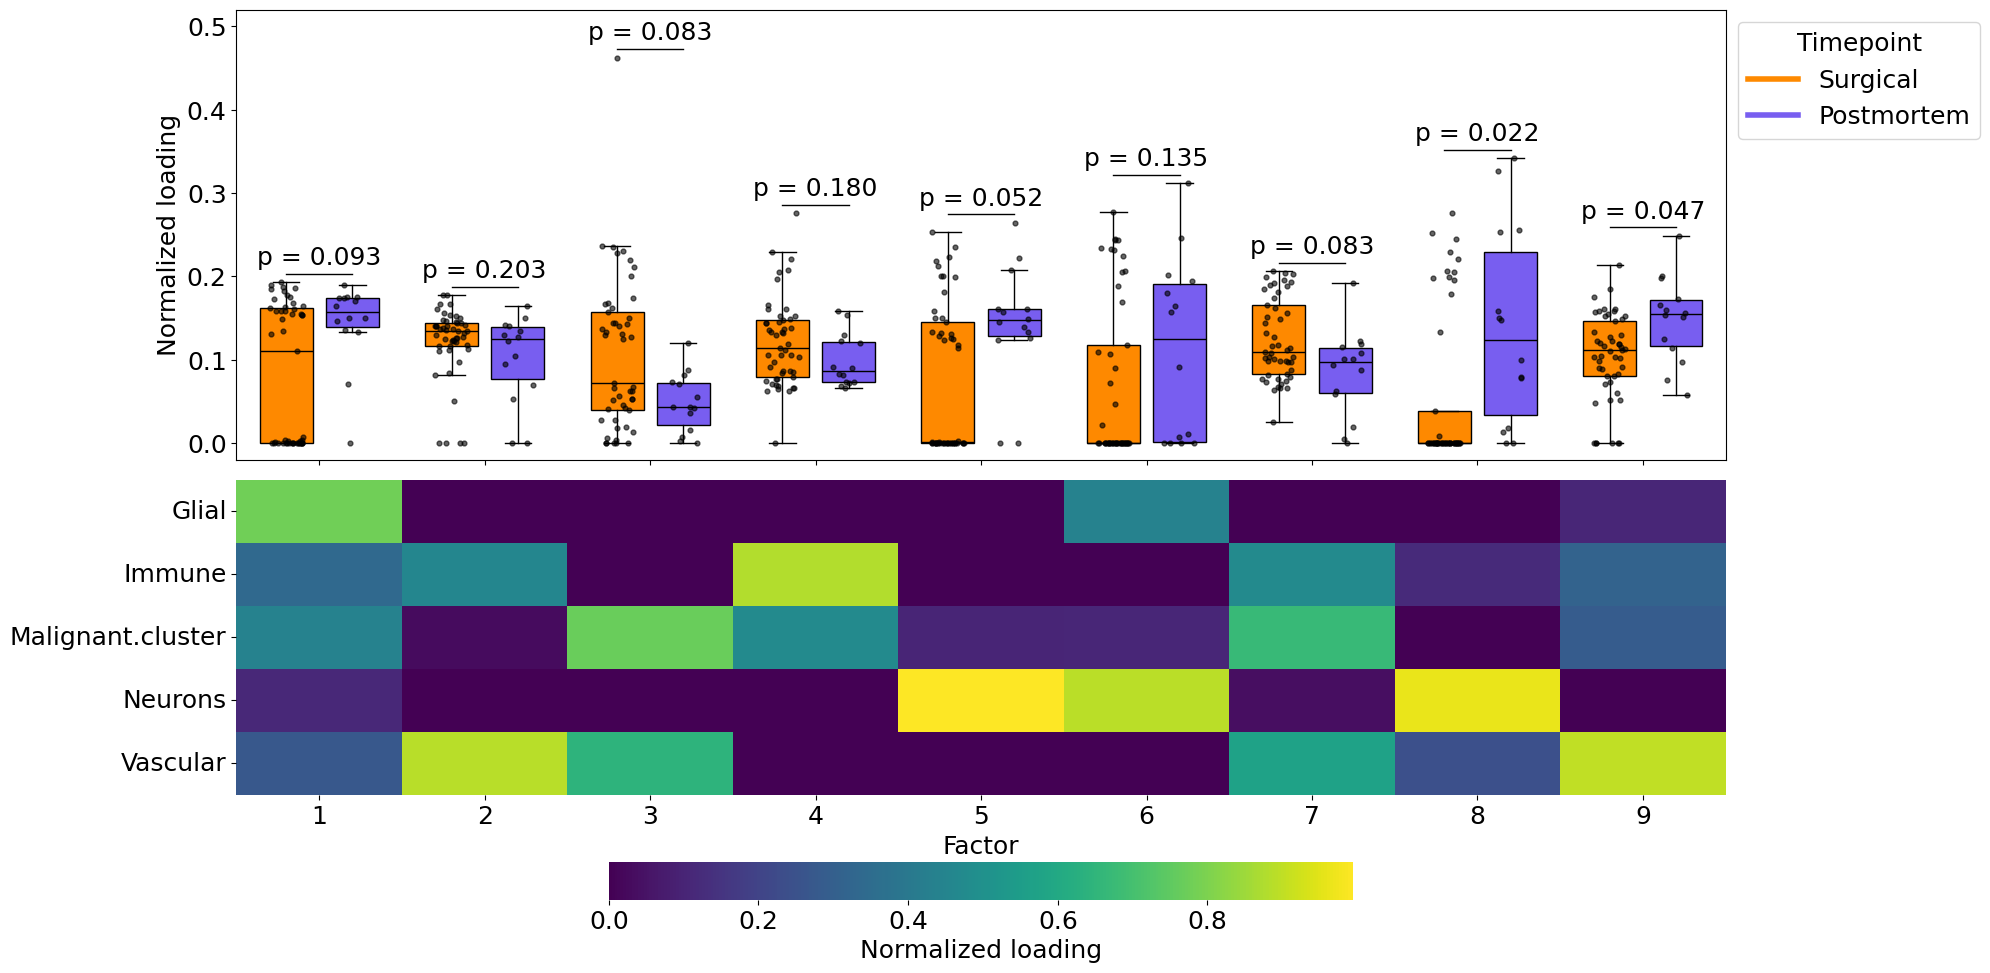

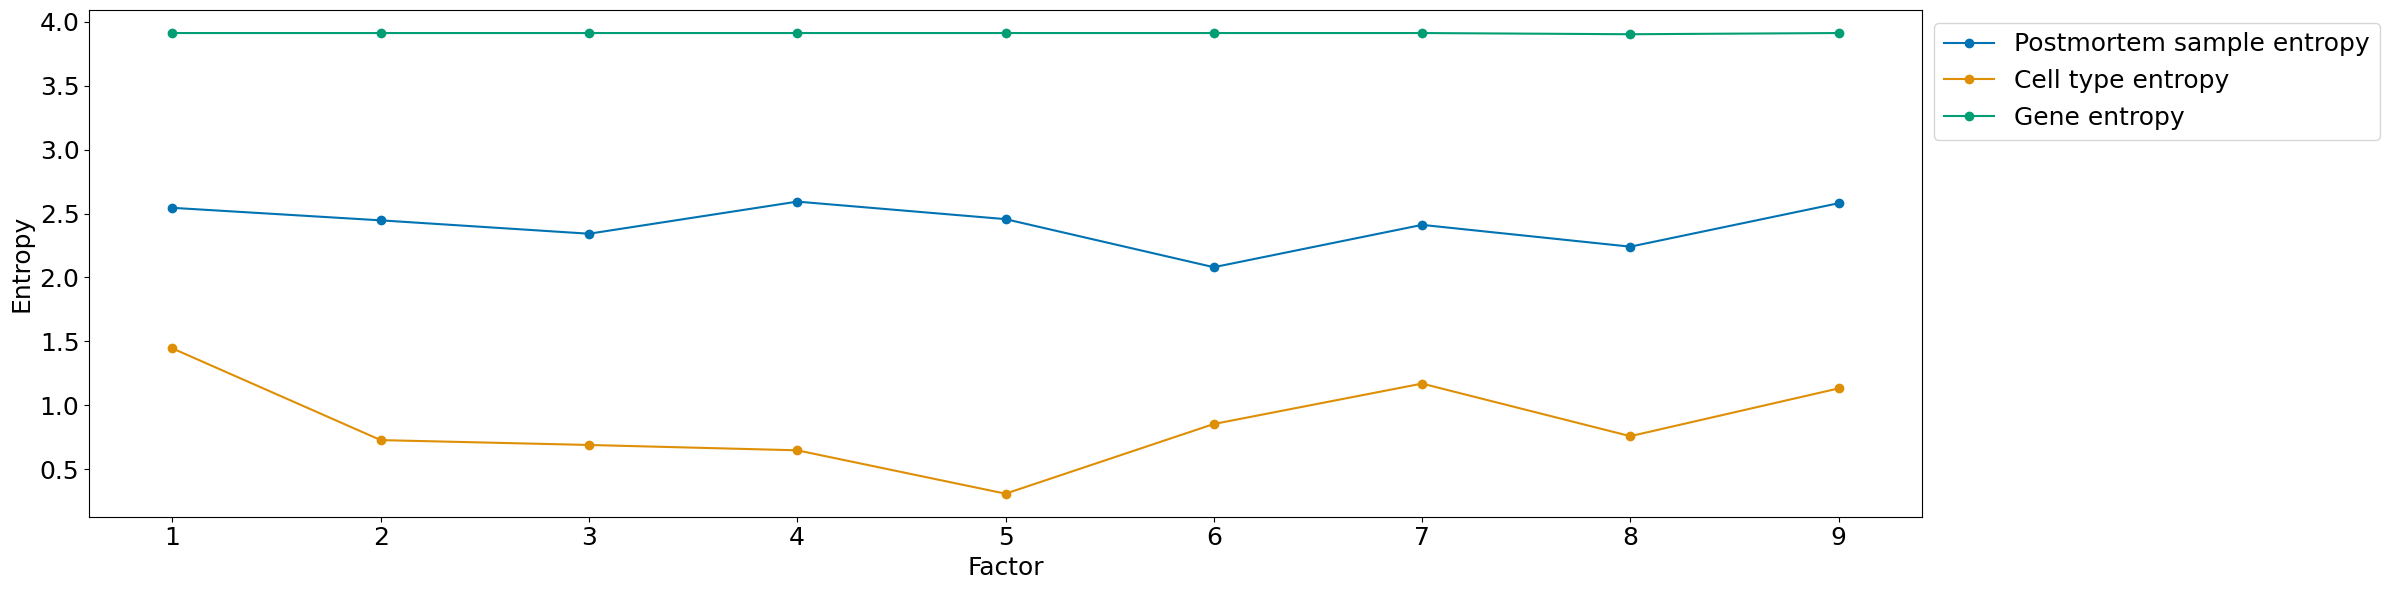


Factor: 1
MT-CO3', 'MT-CO2', 'CADM2', 'PTPRZ1', 'PCDH9', 'MT-ATP6', 'LRP1B', 'NPAS3', 'PPP2R2B', 'DLG2', 'FAM155A', 'MAGI2', 'MT-ND3', 'MT-ND4', 'NRCAM', 'MT-CYB', 'ADGRB3', 'DPP6', 'MT-ND1', 'NRXN1', 'NRG3', 'PTPRG', 'NCAM2', 'ANKS1B', 'IL1RAPL1', 'PDE4B', 'GPC6', 'DOCK4', 'NRXN3', 'FRMD4A', 'GPM6A', 'CTNND2', 'PDE4D', 'RPLP1', 'RBFOX1', 'ANK2', 'HFM1', 'DNM3', 'NTM', 'FMNL2', 'RORA', 'MT-ND2', 'TRIM9', 'SNTG1', 'DLGAP1', 'ADGRL3', 'CTNNA2', 'GRIK2', 'CTNNA3', 'PTPRD', 'LDLRAD3', 'ZEB1', 'NAALADL2', 'PTN', 'ERBB4', 'RPS18', 'MAML2', 'CSMD1', 'SCMH1', 'NOVA1', 'AKAP6', 'CLU', 'DTNA', 'SIK3', 'CMSS1', 'RPL13', 'KALRN', 'EXT1', 'NLGN1', 'NF1', 'MAGI1', 'NEGR1', 'CHD9', 'NCKAP5', 'CELF2', 'PRKCA', 'NAV2', 'GPM6B', 'MDGA2', 'MAP2', 'TIAM1', 'PTK2', 'MARCHF1', 'MTRNR2L12', 'SRGAP3', 'FOXN3', 'PSD3', 'DSCAM', 'SLC1A3', 'NTRK2', 'RPL3', 'GRIA2', 'VIM', 'PLCB1', 'FRMD5', 'NCAM1', 'KCNMA1', 'TBC1D5', 'SOX5', 'CHST11

Factor: 2
RPS18', 'RPL18A', 'RPS4X', 'RPL23A', 'RPL26', 'RPL15', 'RPS7', 'RPS

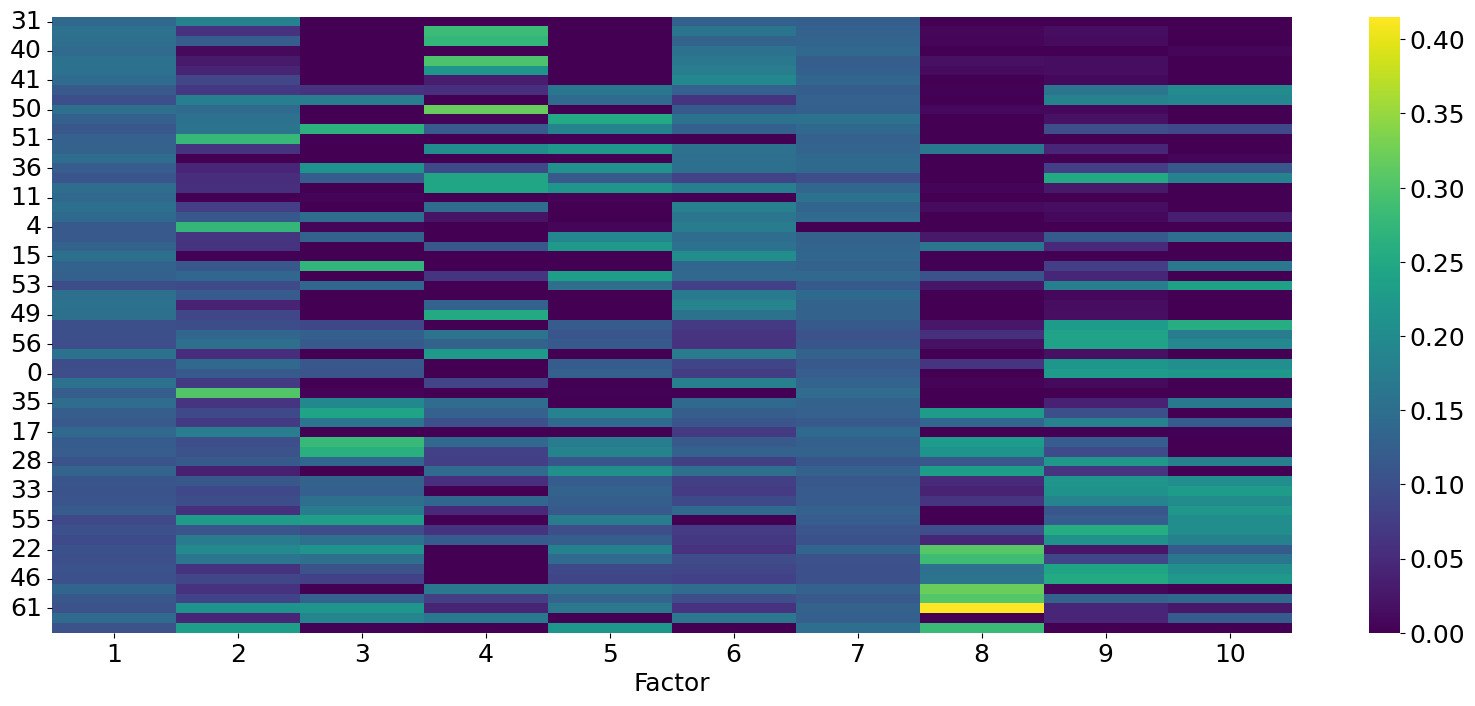

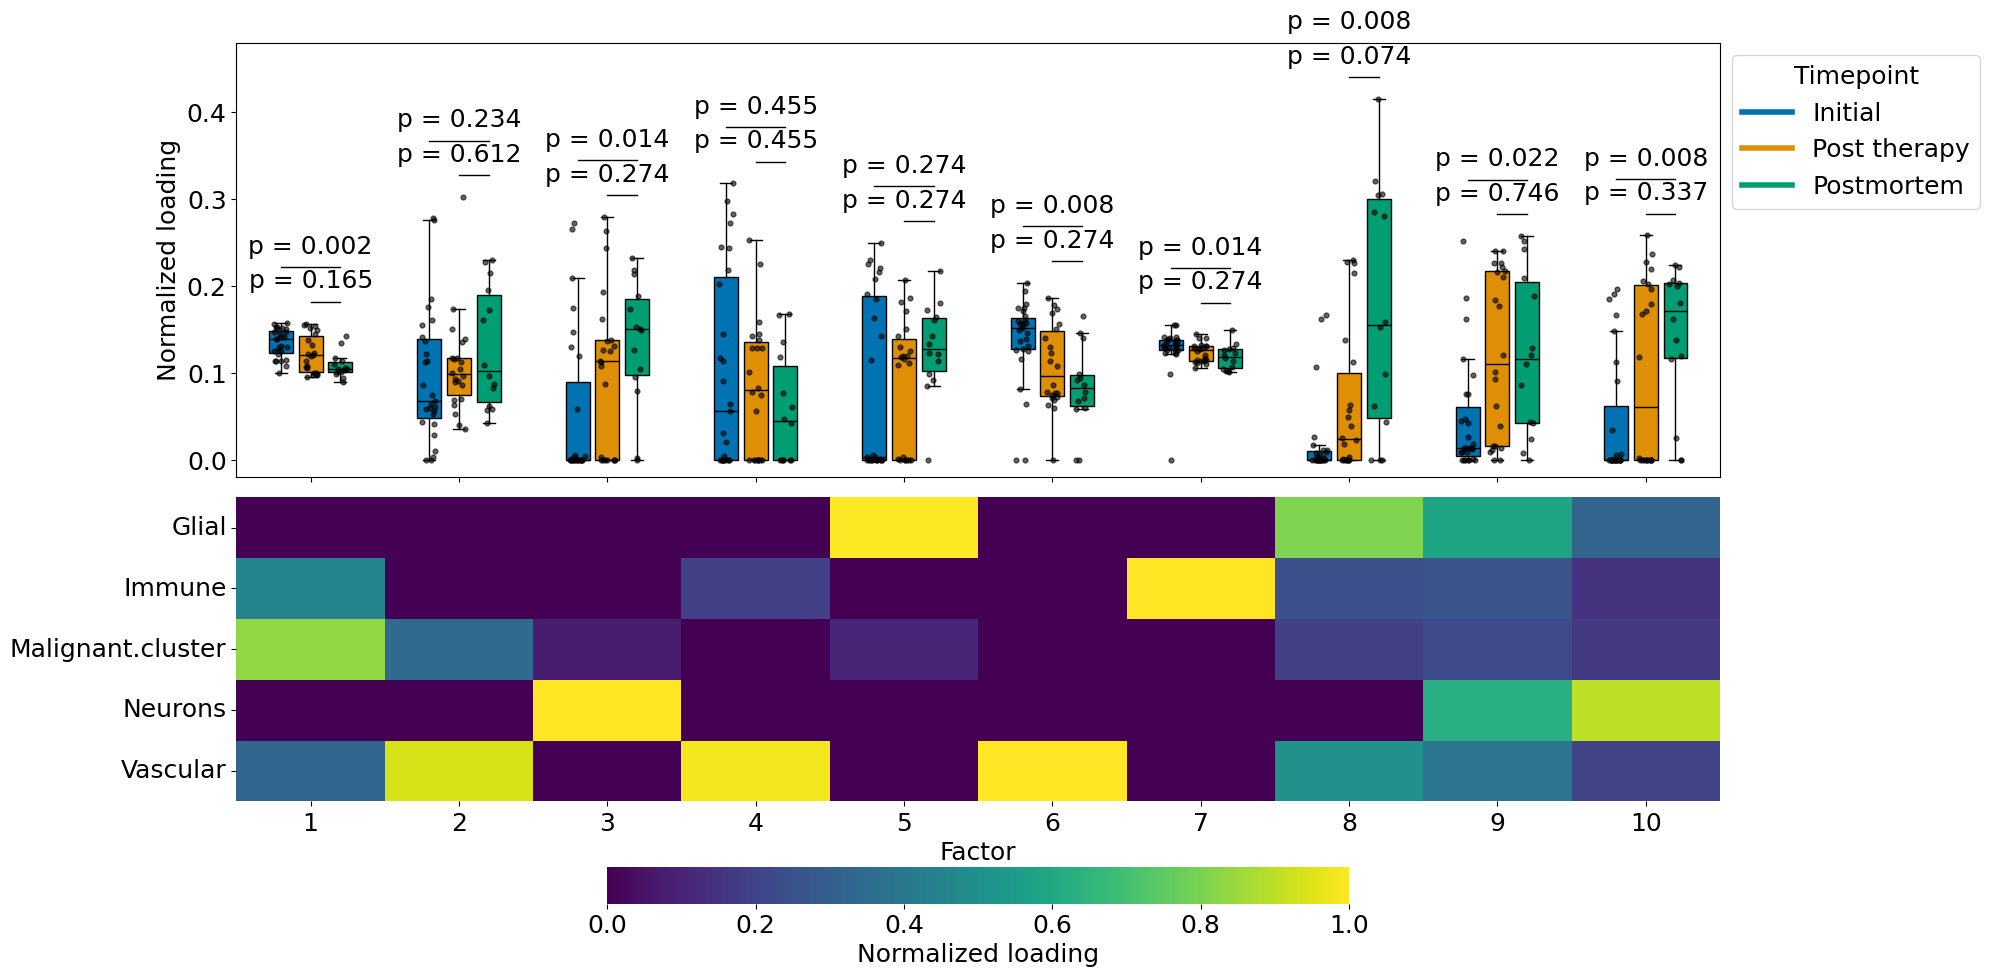

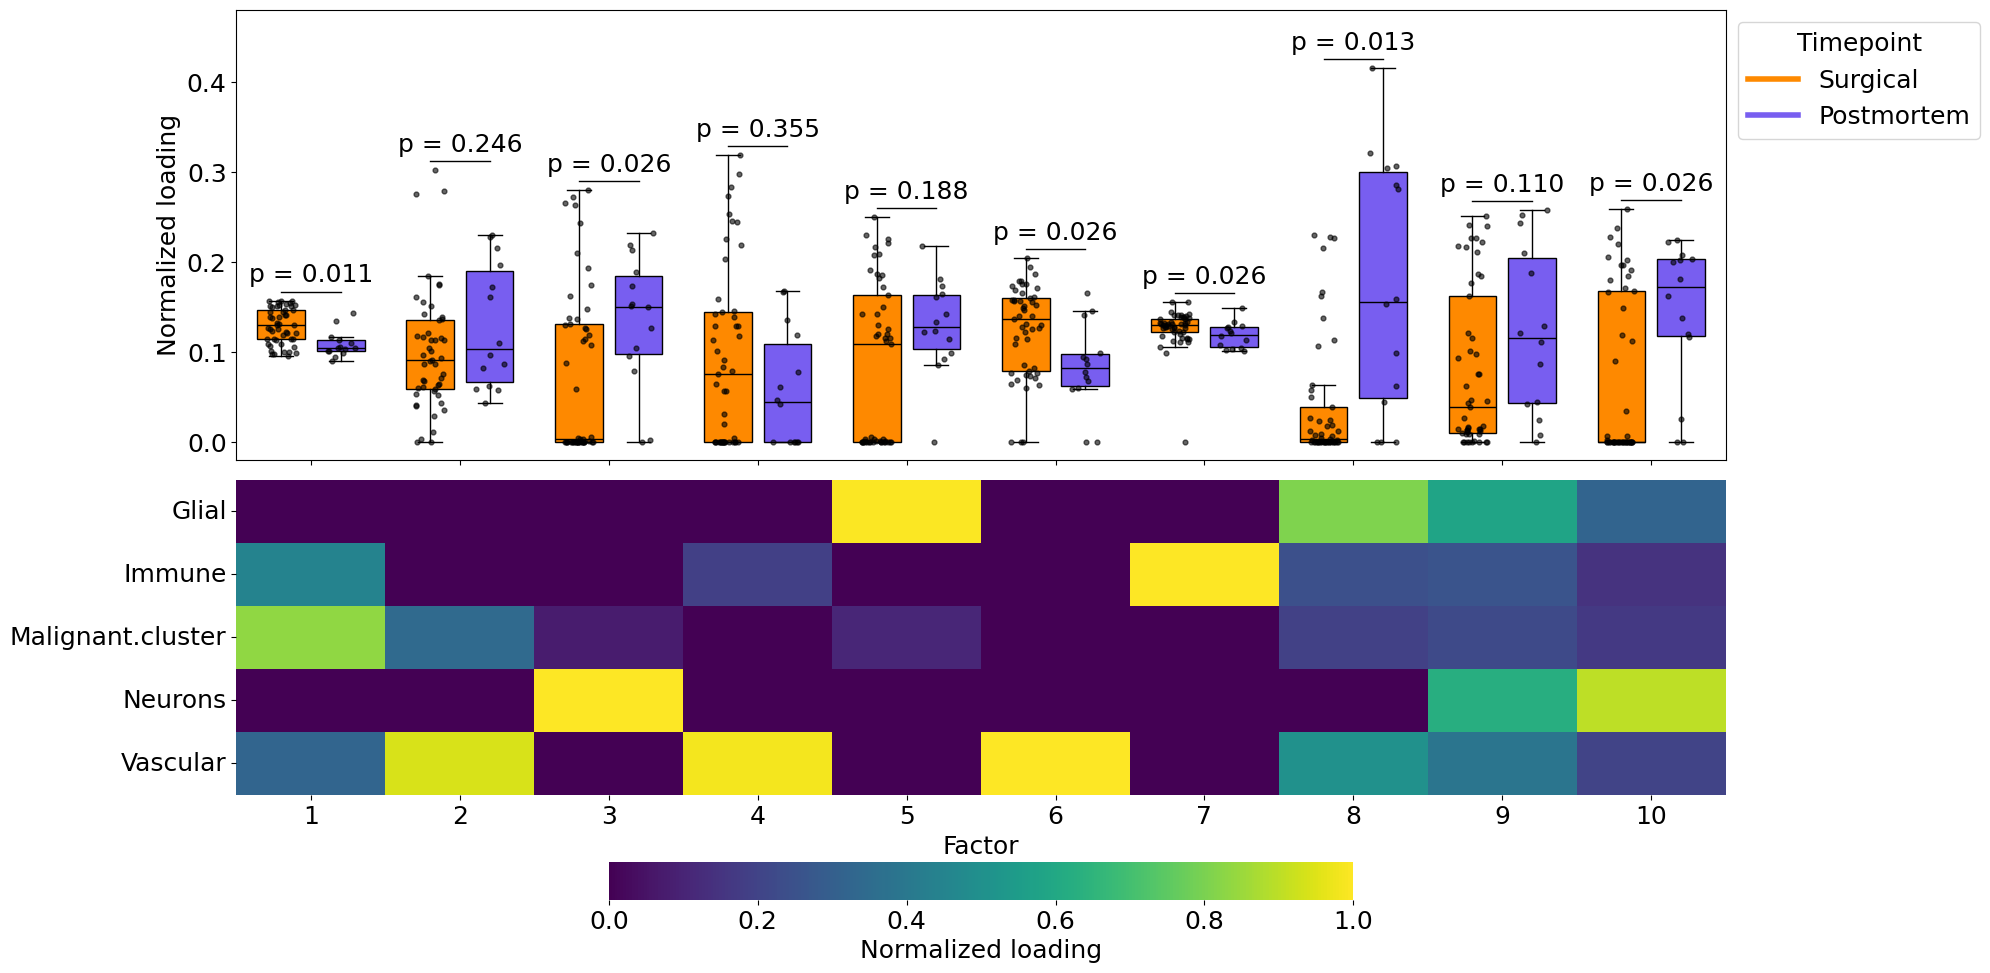

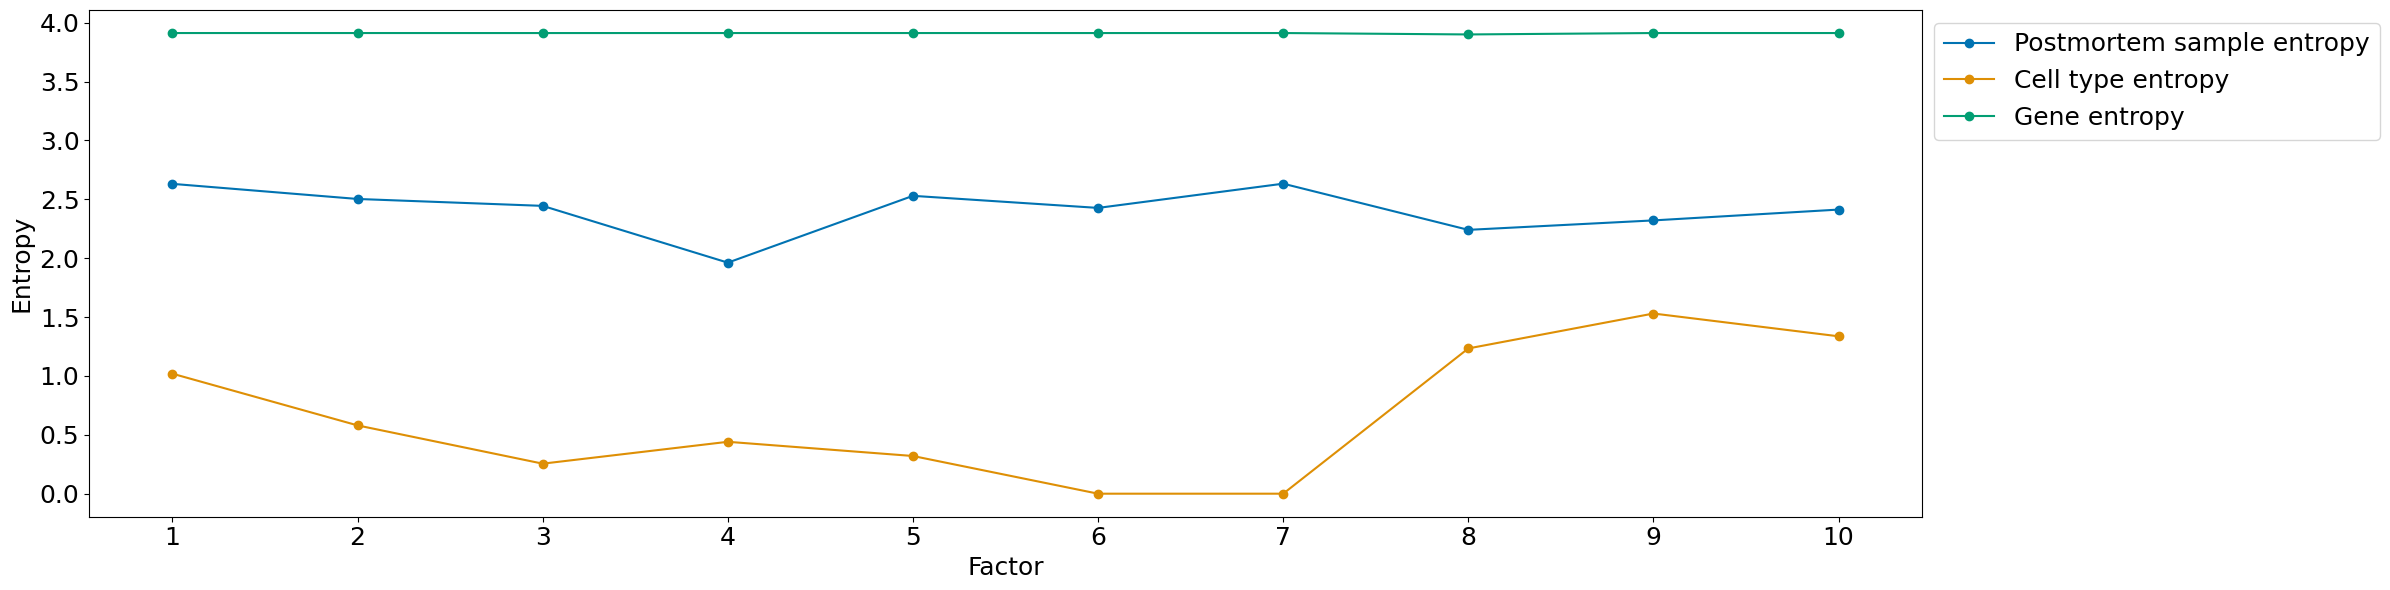


Factor: 1
MT-CO3', 'PCDH9', 'CADM2', 'MT-CO2', 'PTPRZ1', 'NPAS3', 'LRP1B', 'MT-ATP6', 'PPP2R2B', 'DLG2', 'NRCAM', 'FAM155A', 'MAGI2', 'MT-ND4', 'ANKS1B', 'DPP6', 'MT-ND3', 'IL1RAPL1', 'ADGRB3', 'MT-ND1', 'NRG3', 'GPC6', 'MT-CYB', 'DOCK4', 'GPM6A', 'NCAM2', 'FRMD4A', 'DNM3', 'SNTG1', 'CTNND2', 'ANK2', 'TRIM9', 'RPLP1', 'CMSS1', 'NTM', 'PTN', 'PTPRD', 'FMNL2', 'PDE4B', 'CTNNA3', 'PTPRG', 'MT-ND2', 'AKAP6', 'ADGRL3', 'CLU', 'RPL13', 'NAALADL2', 'PDE4D', 'MAML2', 'KALRN', 'NLGN1', 'NTRK2', 'MDGA2', 'RORA', 'RPS18', 'ERBB4', 'NRXN1', 'NOVA1', 'FOXN3', 'NEGR1', 'PRKCA', 'DLGAP1', 'SIK3', 'DTNA', 'LDLRAD3', 'HFM1', 'GPM6B', 'EXT1', 'ZEB1', 'CTNNA2', 'CHST11', 'NCAM1', 'SLC1A3', 'PTK2', 'SOX5', 'NAV2', 'MAGI1', 'GRID1', 'KCNMA1', 'TMCC1', 'MARCHF1', 'LDLRAD4', 'MAP2', 'FRMD5', 'ACTG1', 'MTRNR2L12', 'DOCK3', 'PSD3', 'DAB1', 'SORBS1', 'CDH2', 'ZSWIM6', 'CHD9', 'CNKSR2', 'PLCB1', 'RBFOX2', 'RPL37A', 'DDAH1', 'PBX1', 'TIAM1

Factor: 2
ATP10A', 'ST6GALNAC3', 'SCARB1', 'GALNT18', 'MYRIP', 'PTPRG', 

In [25]:
for rank in range(min_rank, max_rank + 1):
    print(rank)
    tensor_id = "rank_" + str(rank)
    sig_tensor_fact = torch.load(output_dir + "consensus/" + "consensus_tensor_rank_" + str(rank) + ".pt", weights_only=False)

    # create folder
    figures_output_dir = figures_dir + tensor_id + "/"
    if save_figures:
        if not os.path.exists(figures_output_dir):
            os.makedirs(figures_output_dir)
            print(f"Folder '{figures_output_dir}' created.")
        else:
            print(f"Folder '{figures_output_dir}' already exists.")


    # create data frames for factors
    sig_tensor_fact = cp_normalize(sig_tensor_fact) # (20586, 63, 6)

    gene_facs = sig_tensor_fact[1][0]
    sample_facs = sig_tensor_fact[1][1]
    celltype_facs = sig_tensor_fact[1][2]

    gene_facs_df = pd.DataFrame(gene_facs)
    gene_facs_df.index = all_genes
    gene_facs_df.columns = [str(x) for x in np.arange(1, rank + 1)]

    celltype_facs_df = pd.DataFrame(celltype_facs)
    celltype_facs_df.index = all_celltypes
    celltype_facs_df.columns = [str(x) for x in np.arange(1, rank + 1)]
    celltype_facs_df["celltype"] = celltype_facs_df.index
    celltype_facs_df_long = pd.melt(celltype_facs_df, id_vars=['celltype'], var_name='factor', value_name='value')

    sample_facs_df = pd.DataFrame(sample_facs)
    sample_facs_df.columns = [str(x) for x in np.arange(1, rank + 1)]
    sample_facs_df.index = all_samples
    sample_facs_df["sample.id"] = sample_facs_df.index
    sample_facs_w_metadata_df = pd.merge(sample_facs_df, sample_metadata_df, on='sample.id', how='inner')
    sample_facs_w_metadata_df['timepoint'] = sample_facs_w_metadata_df['timepoint'].astype(CategoricalDtype(categories=["Initial", "Post therapy", "Postmortem"], ordered=True))
    sample_facs_w_metadata_df = sample_facs_w_metadata_df.sort_values(by='timepoint')


    # sample facs plots
    sample_facs_w_metadata_df_long = pd.melt(sample_facs_w_metadata_df, id_vars=['sample.id', 'timepoint', 'is_postmortem', 'timepoint.original'], var_name='factor', value_name='value')

    plot_sample_facs_heatmap(sample_facs_w_metadata_df, rank)
    
    df = sample_facs_w_metadata_df_long 
    pval_df = summary_df[summary_df['rank'] == rank]

    factor_plot(df, pval_df, value_col = "value", group_col = "factor", subgroup_col = "timepoint", fig_width = 20, fig_height = 10, width = 0.2, figure_outpath = figures_output_dir + "sample_factors_and_cell_type_factors_summary_all_timepoints.pdf", plot_points = True, plot_significant_only = False)
    factor_plot(df, pval_df, value_col = "value", group_col = "factor", subgroup_col = "is_postmortem", fig_width = 20, fig_height = 10, width = 0.4, figure_outpath = figures_output_dir + "sample_factors_and_cell_type_factors_summary.pdf", plot_points = True, plot_significant_only = False)


    # cell type and gene (top 50 per factor) entropies for each factor
    plot_factor_entropies(sample_facs_w_metadata_df_long, celltype_facs_df_long, gene_facs_df, top_genes_per_factor = 50)
    
    print_signatures = True
    top_n = 100 # how many genes to use for signature
    gene_signatures = {}
    for f in range(rank):
        top_genes_factor = gene_facs_df.sort_values(by=str(f + 1), ascending=False).head(top_n).index.tolist() 
    
        if print_signatures:
            print("\nFactor: " + str(f + 1))
            print("', '".join(top_genes_factor))
            
        gene_signatures[str(f + 1)] = top_genes_factor
    pd.DataFrame(gene_signatures).to_csv(figures_output_dir + "gene_signatures.tsv", sep = "\t", index=False)

    
    # save all gene factors
    gene_facs_df['gene'] = gene_facs_df.index
    gene_facs_df.columns = ['Factor ' + i for i in gene_facs_df.columns]
    gene_facs_df.to_csv(figures_output_dir + "gene_factors.tsv", sep = "\t", index=False)